In [5]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import MinMaxScaler
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Wedge
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle




sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [6]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'
integr_output = '../../../3_integrated_assay_results/3_outputs'

In [7]:
AM_df = pd.read_csv('../../../1_allele_collection/1_inputs/raw_inputs/AlphaMissense/AlphaMissense_hg38.tsv', sep='\t', skiprows=3)
AM_df

,#CHROM,POS,REF,ALT,genome,uniprot_id,transcript_id,protein_variant,am_pathogenicity,am_class
0,chr1,69094,G,T,hg38,Q8NH21,ENST00000335137.4,V2L,0.2937,likely_benign
1,chr1,69094,G,C,hg38,Q8NH21,ENST00000335137.4,V2L,0.2937,likely_benign
2,chr1,69094,G,A,hg38,Q8NH21,ENST00000335137.4,V2M,0.3296,likely_benign
3,chr1,69095,T,C,hg38,Q8NH21,ENST00000335137.4,V2A,0.2609,likely_benign
4,chr1,69095,T,A,hg38,Q8NH21,ENST00000335137.4,V2E,0.2922,likely_benign
...,...,...,...,...,...,...,...,...,...,...
71697551,chrY,57196925,T,G,hg38,Q01113,ENST00000244174.10_PAR_Y,F521C,0.1903,likely_benign
71697552,chrY,57196925,T,C,hg38,Q01113,ENST00000244174.10_PAR_Y,F521S,0.2045,likely_benign
71697553,chrY,57196925,T,A,hg38,Q01113,ENST00000244174.10_PAR_Y,F521Y,0.1440,likely_benign
71697554,chrY,57196926,C,G,hg38,Q01113,ENST00000244174.10_PAR_Y,F521L,0.5879,likely_pathogenic


In [8]:
orf_distances = pd.read_csv(f"{outputs_dir}/orf_distances.csv").pipe(pl.from_pandas)
edge_df = pd.read_csv(f"{outputs_dir}/edges_df.csv")
all_assay_df = pd.read_csv(f"{integr_output}/0_all_gene_variants_assayed_summary.tsv", sep="\t")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/885406984.py:2: DtypeWarning: Columns (191,209,210,227,228,229,230,231,232,233,234,241,242,284,285,610,612,674,676,678,964,974,983,985,994,996,1004,1005,1006,1010,1013,1020,1024,1026,1029) have mixed types. Specify dtype option on import or set low_memory=False.
  edge_df = pd.read_csv(f"{outputs_dir}/edges_df.csv")
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/885406984.py:3: DtypeWarning: Columns (164,185,186,198,208,214,215,253,254,257,258,479,481,523,553,555,557,569,571,583,585,593,595,647,649,651,657,663,667,699,701,703,823,875,877,879,881,883,938,947,949,952,959,960,967,972,977,978,979,983,986,995,996,997) have mixed types. Specify dtype option on import or set low_memory=False.
  all_assay_df = pd.read_csv(f"{integr_output}/0_all_gene_variants_assayed_summary.tsv", sep="\t")


In [9]:
all_assay_df

,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,...,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,imaging_hit
0,ABCD1,Arg389Gly,ABCD1_Arg389Gly,NC_000023.11:153736194:C:G,1165C>G,23,153736195,C,G,X,...,2.001570,0.101735,0.134305,2025_01_Batch_13-14,0.693378,0.573403,False,False,False,False
1,ABCD1,Arg518Gln,ABCD1_Arg518Gln,NC_000023.11:153740155:G:A,1553G>A,23,153740156,G,A,X,...,-0.564297,0.596924,0.645086,2025_01_Batch_13-14,0.784993,0.691867,False,False,False,False
2,ACSF3,Ala17Pro,ACSF3_Ala17Pro,NC_000016.10:89100729:G:C,49G>C,16,89100730,G,C,16,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ACSF3,Ala197Thr,ACSF3_Ala197Thr,NC_000016.10:89101269:G:A,589G>A,16,89101270,G,A,16,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ACSF3,Arg10Trp,ACSF3_Arg10Trp,NC_000016.10:89100708:C:T,28C>T,16,89100709,C,T,16,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1402,ZC4H2,Pro201Ser,ZC4H2_Pro201Ser,NC_000023.11:64917856:G:A,601C>T,23,64917857,G,A,X,...,3.412556,0.058483,0.076827,2025_01_Batch_13-14,0.802143,0.776184,False,False,False,False
1403,ZC4H2,Val63Leu,ZC4H2_Val63Leu,NC_000023.11:64921854:C:G,187G>C,23,64921855,C,G,X,...,-3.575493,1.000000,1.000000,2025_01_Batch_13-14,0.921160,0.805641,False,False,False,False
1404,ZMYND10,Arg243Cys,ZMYND10_Arg243Cys,NC_000003.12:50342542:G:A,727C>T,3,50342543,G,A,3,...,1.676036,0.144748,0.183814,2024_01_Batch_7-8,0.904041,0.842055,False,False,False,False
1405,ZMYND10,Leu266Pro,ZMYND10_Leu266Pro,NC_000003.12:50342472:A:G,797T>C,3,50342473,A,G,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Fast mapping using merge instead of dictionary lookup for all_assay_df

# Prepare all_assay_df columns
all_assay_df['nuc_loc'] = pd.to_numeric(all_assay_df['nuc_loc'], errors='coerce').astype('Int64')

# Get unique variants from all_assay_df to filter AM_df first
unique_positions = all_assay_df['nuc_loc'].dropna().unique()

# Filter AM_df to only positions we care about (MUCH faster)
AM_filtered = AM_df[AM_df['POS'].isin(unique_positions)].copy()

# Convert #CHROM: chr1 -> 1, chrX -> 23, chrY -> 24
def parse_chrom(chrom_str):
    chrom = str(chrom_str).replace('chr', '')
    if chrom == 'X':
        return 23
    elif chrom == 'Y':
        return 24
    elif chrom == 'M' or chrom == 'MT':
        return 25
    else:
        try:
            return int(chrom)
        except ValueError:
            return None

AM_filtered['chr_num'] = AM_filtered['#CHROM'].apply(parse_chrom).astype('Int64')

# Drop duplicates BEFORE merge
AM_filtered_dedup = AM_filtered.drop_duplicates(subset=['chr_num', 'POS', 'REF', 'ALT'], keep='first')

print(f"Filtered AM_df from {len(AM_df):,} to {len(AM_filtered):,} rows")
print(f"After dedup: {len(AM_filtered_dedup):,} rows")

# Now merge on chromosome + position + alleles
merged = all_assay_df.merge(
    AM_filtered_dedup[['chr_num', 'POS', 'REF', 'ALT', 'am_pathogenicity']],
    left_on=['chr_num', 'nuc_loc', 'ref_allele', 'alt_allele'],
    right_on=['chr_num', 'POS', 'REF', 'ALT'],
    how='left',
    suffixes=('', '_am')
)

# Verify shapes match
print(f"all_assay_df shape: {all_assay_df.shape}")
print(f"merged shape: {merged.shape}")

# Copy the score to all_assay_df
all_assay_df['am_pathogenicity'] = merged['am_pathogenicity'].values

# Check results
print(f"Total variants in all_assay_df: {len(all_assay_df)}")
print(f"Variants with AM score mapped: {all_assay_df['am_pathogenicity'].notna().sum()}")
print(f"Variants without AM score: {all_assay_df['am_pathogenicity'].isna().sum()}")

Filtered AM_df from 71,697,556 to 4,375 rows
After dedup: 4,296 rows
all_assay_df shape: (1407, 1036)
merged shape: (1407, 1040)
Total variants in all_assay_df: 1407
Variants with AM score mapped: 1407
Variants without AM score: 0


In [11]:
# Fast mapping using merge instead of dictionary lookup for edge_df

# Prepare edge_df columns
edge_df['nuc_loc'] = pd.to_numeric(edge_df['nuc_loc'], errors='coerce').astype('Int64')

# Get unique variants from edge_df to filter AM_df first
unique_positions = edge_df['nuc_loc'].dropna().unique()

# Filter AM_df to only positions we care about (MUCH faster)
AM_filtered = AM_df[AM_df['POS'].isin(unique_positions)].copy()

# Convert #CHROM: chr1 -> 1, chrX -> 23, chrY -> 24
def parse_chrom(chrom_str):
    chrom = str(chrom_str).replace('chr', '')
    if chrom == 'X':
        return 23
    elif chrom == 'Y':
        return 24
    elif chrom == 'M' or chrom == 'MT':
        return 25
    else:
        try:
            return int(chrom)
        except ValueError:
            return None

AM_filtered['chr_num'] = AM_filtered['#CHROM'].apply(parse_chrom).astype('Int64')

# Drop duplicates BEFORE merge
AM_filtered_dedup = AM_filtered.drop_duplicates(subset=['chr_num', 'POS', 'REF', 'ALT'], keep='first')

print(f"Filtered AM_df from {len(AM_df):,} to {len(AM_filtered):,} rows")
print(f"After dedup: {len(AM_filtered_dedup):,} rows")

# Now merge on chromosome + position + alleles
merged = edge_df.merge(
    AM_filtered_dedup[['chr_num', 'POS', 'REF', 'ALT', 'am_pathogenicity']],
    left_on=['chr_num', 'nuc_loc', 'ref_allele', 'alt_allele'],
    right_on=['chr_num', 'POS', 'REF', 'ALT'],
    how='left',
    suffixes=('', '_am')
)

# Verify shapes match
print(f"edge_df shape: {edge_df.shape}")
print(f"merged shape: {merged.shape}")

# Copy the score to edge_df
edge_df['am_pathogenicity'] = merged['am_pathogenicity'].values

# Check results
print(f"Total variants in edge_df: {len(edge_df)}")
print(f"Variants with AM score mapped: {edge_df['am_pathogenicity'].notna().sum()}")
print(f"Variants without AM score: {edge_df['am_pathogenicity'].isna().sum()}")

Filtered AM_df from 71,697,556 to 1,613 rows
After dedup: 1,545 rows
edge_df shape: (2140, 1056)
merged shape: (2140, 1060)
Total variants in edge_df: 2140
Variants with AM score mapped: 1841
Variants without AM score: 299


In [13]:
# all_assay_df[all_assay_df['am_pathogenicity'].isna()].to_csv('variants_missing_AM_score.csv', index=False)
all_assay_df[all_assay_df['am_pathogenicity'].isna()]#.symbol.unique()

,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,...,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,imaging_hit


In [14]:
all_assay_df[all_assay_df['am_pathogenicity'].isna()].gene_variant.unique()

array([], dtype=object)

In [15]:
edge_df[edge_df.symbol == 'KCNJ2'][['ad_symbol', 'ad_orf_id']]

,ad_symbol,ad_orf_id
36,KCNJ2,100016069
52,KCNJ2,100016069
142,KCNJ2,100016069
176,KCNJ2,100016069
415,KCNJ2,100016069
462,KCNJ2,100016069
469,KCNJ2,100016069
496,KCNJ2,100016069
586,KCNJ2,100016069
663,KCNJ2,100016069


In [16]:
# https://pmc.ncbi.nlm.nih.gov/articles/PMC8267277/

def classify_af(af):
    if pd.isna(af):
        return 'Missing' # or 'Ultra-Rare' depending on your assumption
    if af < 0.0001:
        return 'Ultra-Rare (<0.01%)'
    elif af < 0.01:
        return 'Rare (0.01-1%)'
    elif af < 0.05:
        return 'Low Freq (1-5%)'
    else:
        return 'Common (>5%)'

# Create the new column
edge_df['gnomAD_Class'] = pd.to_numeric(edge_df['gnomAD4.1_joint_AF'], errors='coerce').apply(classify_af)
all_assay_df['gnomAD_Class'] = pd.to_numeric(all_assay_df['gnomAD4.1_joint_AF'], errors='coerce').apply(classify_af)

# Check the counts
print(edge_df['gnomAD_Class'].value_counts())
print(all_assay_df['gnomAD_Class'].value_counts())

gnomAD_Class
Missing                1297
Ultra-Rare (<0.01%)     596
Rare (0.01-1%)          236
Low Freq (1-5%)           9
Common (>5%)              2
Name: count, dtype: int64
gnomAD_Class
Missing                679
Ultra-Rare (<0.01%)    500
Rare (0.01-1%)         187
Common (>5%)            21
Low Freq (1-5%)         20
Name: count, dtype: int64


# Simple Log2FC

In [17]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(10, 12), save_path=None):
    """
    Plot Log2FC panel with RMS distance for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    
    Returns:
    --------
    fig, ax : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP ---
    fig, ax = plt.subplots(figsize=figsize)
    
    # Add header for RMS distance
    if orf_distances is not None:
        header_y = len(variants_sorted) * row_height
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=9, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # RMS distance text
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=10, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Horizontal grid lines
    for i in range(len(variants_sorted)):
        ax.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_title(f"{db_symbol} - Log2FC with RMS Distance", fontsize=14, fontweight='bold')
    
    # --- LEGENDS ---
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax.legend(handles=interactor_patches, bbox_to_anchor=(1.02, 1), loc='upper left',
                     title='Interactor', fontsize=8, title_fontsize=9)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax.legend(handles=clinvar_patches, bbox_to_anchor=(1.02, 0.5), loc='upper left',
                         title='ClinVar', fontsize=8, title_fontsize=9)
        ax.add_artist(leg1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, ax

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3773049836.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


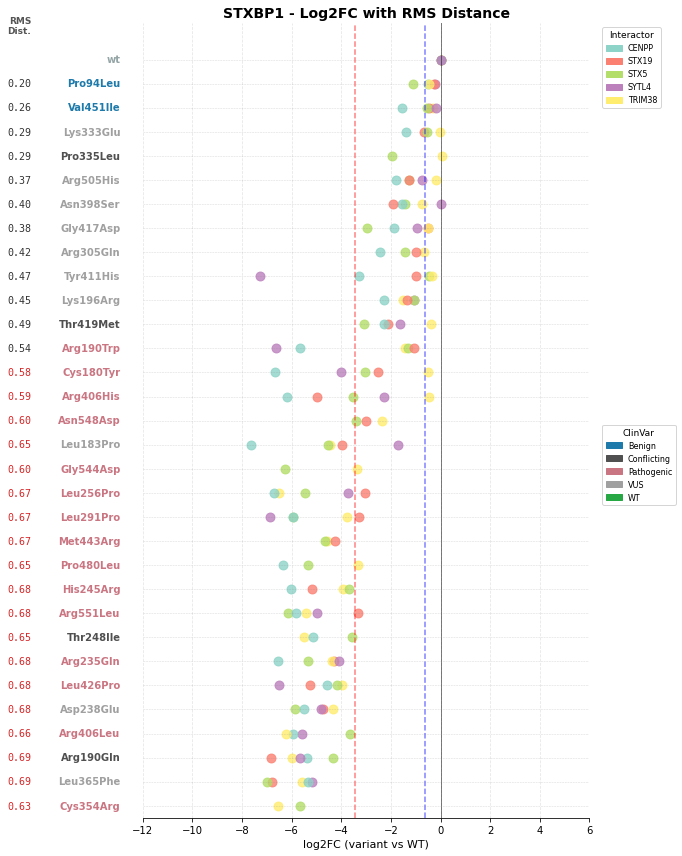

In [18]:
# Single gene plot

fig, ax = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    palette_dict=palette_dict,
    # save_path=f"{outputs_dir}/ZMYND10_log2fc.pdf"
)

In [19]:
edge_df[['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
 'gnomAD4.1_joint_AF','phyloP100way_vertebrate', 'phastCons100way_vertebrate', 'GERP++_RS', 'PROVEAN_score']]

,plddt_f32,rsa_f32,AlphaMissense_score,gnomAD4.1_joint_AF,phyloP100way_vertebrate,phastCons100way_vertebrate,GERP++_RS,PROVEAN_score
0,94.47,0.000000,0.9471,.,7.624,1.000,4.81,-4.97
1,62.83,75.352110,0.5825,1.573780e-04,4.090,0.998,4.42,.
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,72.16,54.634148,0.0726,1.369300e-04,2.153,1.000,1.72,-1.53
4,71.66,88.235300,0.4658,1.053270e-05,5.116,1.000,5.28,.
...,...,...,...,...,...,...,...,...
2135,97.45,69.014084,0.9894,.,7.803,1.000,5.10,-5.38
2136,95.43,7.048458,0.9999,.,9.870,1.000,5.10,-12.53
2137,72.16,54.634148,0.0726,1.369300e-04,2.153,1.000,1.72,-1.53
2138,87.90,25.000000,0.3709,.,5.477,1.000,4.53,.


# Heatmap

In [20]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(18, 12), save_path=None,
                      annotation_cols=None):
    """
    Plot Log2FC panel with RMS distance and annotation bars for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    annotation_cols : list, optional
        List of column names to plot as vertical bars
    
    Returns:
    --------
    fig, axes : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
                          'gnomAD4.1_joint_AF', 'phyloP100way_vertebrate', 
                          'phastCons100way_vertebrate', 'GERP++_RS', 'PROVEAN_score']
    
    # Filter to only columns that exist in the dataframe
    annotation_cols = [col for col in annotation_cols if col in edge_df.columns]
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # Get annotation values per variant (take first value per variant)
    variant_annotations = gene_data.groupby('aa_change')[annotation_cols].first()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP WITH GRIDSPEC ---
    n_annotations = len(annotation_cols)
    width_ratios = [3] + [0.3] * n_annotations  # Main plot + narrow bars for annotations
    
    fig, axes = plt.subplots(1, 1 + n_annotations, figsize=figsize,
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.02})
    
    ax = axes[0]  # Main log2fc axis
    
    # Add header for RMS distance
    if orf_distances is not None:
        header_y = len(variants_sorted) * row_height
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=9, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ON MAIN AXIS ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # RMS distance text
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=10, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Horizontal grid lines
    for i in range(len(variants_sorted)):
        ax.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_title(f"{db_symbol} - Log2FC with RMS Distance", fontsize=14, fontweight='bold')
    
    # --- ANNOTATION BAR PLOTS ---
    # Define colormaps for different annotation types
    annotation_cmaps = {
        'plddt_f32': 'RdYlGn',           # High is good (green)
        'rsa_f32': 'viridis',             # Neutral
        'AlphaMissense_score': 'RdYlGn_r', # High is bad (red)
        'gnomAD4.1_joint_AF': 'Blues',    # Frequency
        'phyloP100way_vertebrate': 'RdYlGn',  # High = conserved (good)
        'phastCons100way_vertebrate': 'RdYlGn',  # High = conserved
        'GERP++_RS': 'RdYlGn',            # High = conserved
        'PROVEAN_score': 'RdYlGn',        # High (less negative) = benign
    }
    
    # Define display names
    annotation_labels = {
        'plddt_f32': 'pLDDT',
        'rsa_f32': 'RSA',
        'AlphaMissense_score': 'AM',
        'gnomAD4.1_joint_AF': 'gnomAD',
        'phyloP100way_vertebrate': 'phyloP',
        'phastCons100way_vertebrate': 'phastCons',
        'GERP++_RS': 'GERP',
        'PROVEAN_score': 'PROVEAN',
    }
    

    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 1]
        
        # Get values for this annotation
        values = []
        for variant in variants_sorted:
            if variant in variant_annotations.index:
                val = variant_annotations.loc[variant, col]
                # Convert to float, handle non-numeric values
                try:
                    values.append(float(val) if pd.notna(val) else np.nan)
                except (ValueError, TypeError):
                    values.append(np.nan)
            else:
                values.append(np.nan)
        
        values = np.array(values, dtype=float)
        
        # Normalize values for coloring (handle NaN)
        valid_mask = ~np.isnan(values)

        if valid_mask.sum() > 0:
            vmin, vmax = np.nanmin(values), np.nanmax(values)
            if vmin == vmax:
                normalized = np.where(valid_mask, 0.5, np.nan)
            else:
                normalized = (values - vmin) / (vmax - vmin)
        else:
            normalized = np.full_like(values, np.nan)
        
        # Get colormap
        cmap_name = annotation_cmaps.get(col, 'viridis')
        cmap_obj = plt.cm.get_cmap(cmap_name)
        
        # Plot horizontal bars
        for i, variant in enumerate(variants_sorted):
            y_pos = i * row_height
            
            if pd.notna(values[i]):
                color = cmap_obj(normalized[i])
                ax_bar.barh(y_pos, 1, height=row_height * 0.8, color=color, alpha=0.8)
            else:
                # Gray for missing data
                ax_bar.barh(y_pos, 1, height=row_height * 0.8, color='#E0E0E0', alpha=0.5)
        
        # Styling for annotation axes
        ax_bar.set_xlim(0, 1)
        ax_bar.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
        ax_bar.set_xticks([])
        ax_bar.set_yticks([])
        ax_bar.spines['left'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['bottom'].set_visible(False)
        
        # Add column label at top
        label = annotation_labels.get(col, col)
        ax_bar.set_title(label, fontsize=8, rotation=45, ha='left', fontweight='bold')
        
        # Add horizontal grid lines to match main plot
        for i in range(len(variants_sorted)):
            ax_bar.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    # --- LEGENDS ON MAIN AXIS ---
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax.legend(handles=interactor_patches, bbox_to_anchor=(-0.35, 1), loc='upper right',
                     title='Interactor', fontsize=8, title_fontsize=9)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax.legend(handles=clinvar_patches, bbox_to_anchor=(-0.35, 0.5), loc='upper right',
                         title='ClinVar', fontsize=8, title_fontsize=9)
        ax.add_artist(leg1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/2729365479.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/2729365479.py:224: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = plt.cm.get_cmap(cmap_name)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/2729365479.py:269: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout

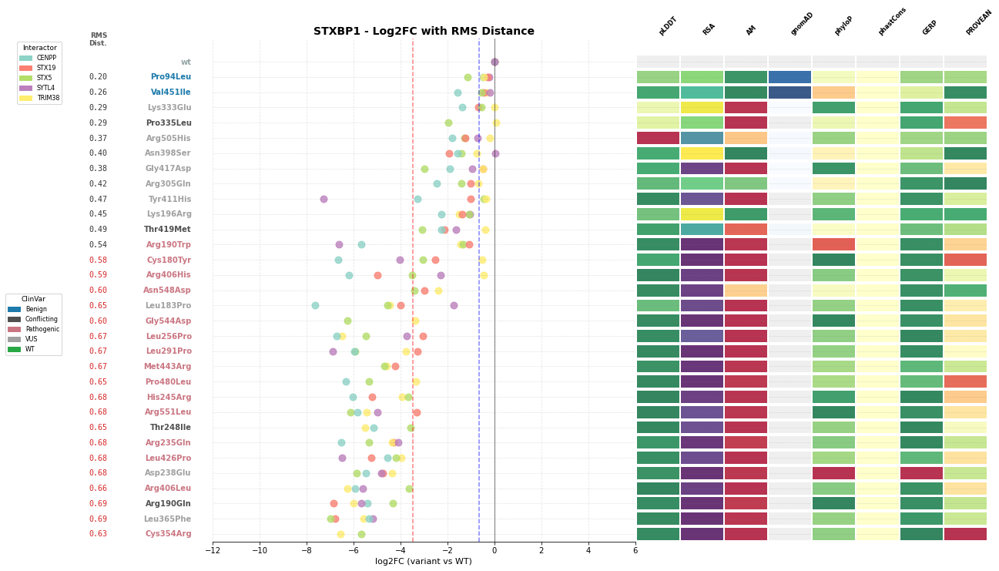

In [21]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    palette_dict=palette_dict,
    # Optionally specify which columns to show:
    # annotation_cols=['plddt_f32', 'AlphaMissense_score', 'phyloP100way_vertebrate'],
)

# Barplot

In [22]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(24, 12), save_path=None,
                      annotation_cols=None):
    """
    Plot Log2FC panel with RMS distance and annotation bar plots for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    annotation_cols : list, optional
        List of column names to plot as bar plots
    
    Returns:
    --------
    fig, axes : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
                          'gnomAD4.1_joint_AF', 'phyloP100way_vertebrate', 
                          'phastCons100way_vertebrate', 'GERP++_RS', 'PROVEAN_score']
    
    # Filter to only columns that exist in the dataframe
    annotation_cols = [col for col in annotation_cols if col in edge_df.columns]
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # Get annotation values per variant (take first value per variant)
    variant_annotations = gene_data.groupby('aa_change')[annotation_cols].first()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP WITH GRIDSPEC ---
    n_annotations = len(annotation_cols)
    # Main plot gets more space, annotation plots get equal smaller space
    width_ratios = [3] + [1] * n_annotations
    
    fig, axes = plt.subplots(1, 1 + n_annotations, figsize=figsize,
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.15})
    
    ax = axes[0]  # Main log2fc axis
    
    # Add header for RMS distance
    if orf_distances is not None:
        header_y = len(variants_sorted) * row_height
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=9, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ON MAIN AXIS ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # RMS distance text
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=10, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Horizontal grid lines
    # for i in range(len(variants_sorted)):
    #     ax.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    # ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_title(f"{db_symbol} - Log2FC with RMS Distance", fontsize=14, fontweight='bold')
    
    # --- ANNOTATION BAR PLOTS ---
    # Define bar colors for different annotation types
    annotation_colors = {
        'plddt_f32': '#2ecc71',           # Green - structure confidence
        'rsa_f32': '#3498db',             # Blue - accessibility
        'AlphaMissense_score': '#e74c3c', # Red - pathogenicity
        'gnomAD4.1_joint_AF': '#9b59b6',  # Purple - frequency
        'phyloP100way_vertebrate': '#f39c12',  # Orange - conservation
        'phastCons100way_vertebrate': '#e67e22',  # Dark orange - conservation
        'GERP++_RS': '#1abc9c',            # Teal - conservation
        'PROVEAN_score': '#34495e',        # Dark gray - functional
    }
    
    # Define display names
    annotation_labels = {
        'plddt_f32': 'pLDDT',
        'rsa_f32': 'RSA',
        'AlphaMissense_score': 'AlphaMissense',
        'gnomAD4.1_joint_AF': 'gnomAD AF',
        'phyloP100way_vertebrate': 'phyloP',
        'phastCons100way_vertebrate': 'phastCons',
        'GERP++_RS': 'GERP++',
        'PROVEAN_score': 'PROVEAN',
    }
    
    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 1]
        
        # Get values for this annotation
        values = []
        bar_colors = []
        for variant in variants_sorted:
            if variant in variant_annotations.index:
                val = variant_annotations.loc[variant, col]
                try:
                    values.append(float(val) if pd.notna(val) else np.nan)
                except (ValueError, TypeError):
                    values.append(np.nan)
            else:
                values.append(np.nan)
            
            # Get color based on ClinVar status
            if variant == 'WT':
                bar_colors.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                bar_colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        values = np.array(values, dtype=float)
        y_positions = np.arange(len(variants_sorted)) * row_height
        
        # Plot horizontal bars
        bars = ax_bar.barh(y_positions, values, height=row_height * 0.7, 
                          color=bar_colors, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # Handle missing values - plot gray placeholder
        for i, val in enumerate(values):
            if np.isnan(val):
                ax_bar.barh(y_positions[i], 0.1, height=row_height * 0.7,
                           color='#E0E0E0', alpha=0.5, edgecolor='gray', linewidth=0.5)
        
        # Styling for annotation axes
        ax_bar.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
        ax_bar.set_yticks([])
        ax_bar.spines['left'].set_visible(False)
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        
        # Set x-axis label
        label = annotation_labels.get(col, col)
        ax_bar.set_xlabel(label, fontsize=9, fontweight='bold')
        
        # Add horizontal grid lines to match main plot
        for i in range(len(variants_sorted)):
            ax_bar.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
        
        ax_bar.grid(axis='x', linestyle='--', alpha=0.3)
        
        # Add zero line for scores that can be negative
        if col in ['PROVEAN_score', 'GERP++_RS', 'phyloP100way_vertebrate']:
            ax_bar.axvline(x=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
    
    # --- LEGENDS ON MAIN AXIS ---
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax.legend(handles=interactor_patches, bbox_to_anchor=(-0.35, 1), loc='upper right',
                     title='Interactor', fontsize=8, title_fontsize=9)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax.legend(handles=clinvar_patches, bbox_to_anchor=(-0.35, 0.5), loc='upper right',
                         title='ClinVar', fontsize=8, title_fontsize=9)
        ax.add_artist(leg1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/35442339.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/35442339.py:263: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


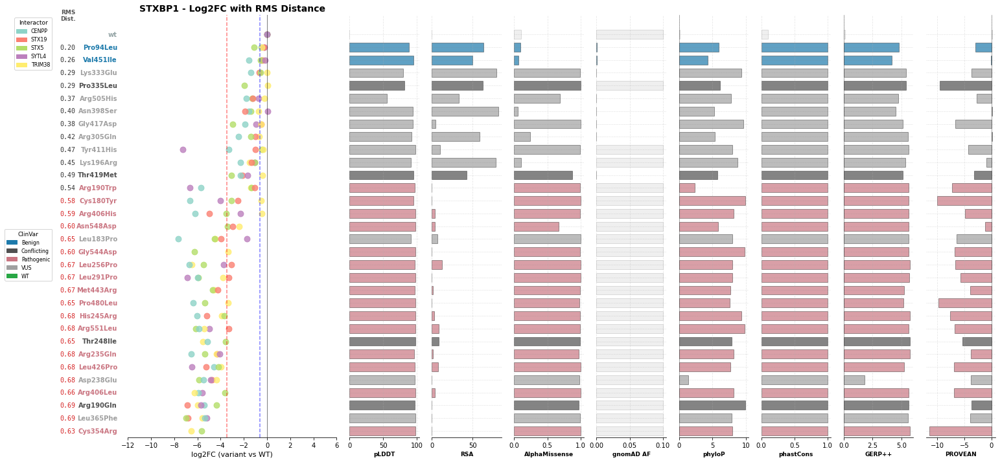

In [23]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    palette_dict=palette_dict,
    # Optionally specify which columns to show:
    # annotation_cols=['plddt_f32', 'AlphaMissense_score', 'phyloP100way_vertebrate'],
)

# Barplot + Misloc + abundance

In [24]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      all_assay_df=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(24, 12), save_path=None,
                      annotation_cols=None):
    """
    Plot Log2FC panel with RMS distance, DualIPA, IMG misloc and annotation bar plots for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    all_assay_df : pd.DataFrame, optional
        DataFrame with DualIPA and IMG misloc scores
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    annotation_cols : list, optional
        List of column names to plot as bar plots
    
    Returns:
    --------
    fig, axes : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
                          'gnomAD4.1_joint_AF', 'phyloP100way_vertebrate', 
                          'GERP++_RS', 'PROVEAN_score']
    
    # Filter to only columns that exist in the dataframe
    annotation_cols = [col for col in annotation_cols if col in edge_df.columns]
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # Get annotation values per variant (take first value per variant)
    variant_annotations = gene_data.groupby('aa_change')[annotation_cols].first()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- ASSAY SCORES DATA SETUP ---
    dualipa_map = {}
    dualipa_hit_map = {}
    img_misloc_map = {}
    img_misloc_hit_map = {}
    
    if all_assay_df is not None:
        assay_gene = all_assay_df[all_assay_df['symbol'] == db_symbol].copy()
        if not assay_gene.empty:
            assay_gene['aa_change'] = assay_gene['aa_change'].fillna('WT')
            if 'dualipa_score' in assay_gene.columns:
                dualipa_map = assay_gene.set_index('aa_change')['dualipa_score'].to_dict()
            if 'dualipa_hit' in assay_gene.columns:
                dualipa_hit_map = assay_gene.set_index('aa_change')['dualipa_hit'].to_dict()
            if 'img_misloc_score' in assay_gene.columns:
                img_misloc_map = assay_gene.set_index('aa_change')['img_misloc_score'].to_dict()
            if 'img_misloc_hit' in assay_gene.columns:
                img_misloc_hit_map = assay_gene.set_index('aa_change')['img_misloc_hit'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP WITH GRIDSPEC ---
    n_annotations = len(annotation_cols)
    n_interactors = len(all_interactors)
    
    # Adjust figure width if we need two columns for legend
    base_width = figsize[0]
    if n_interactors > 15:
        base_width += 3  # Add extra width for two-column legend
    
    # Main plot gets more space, annotation plots get equal smaller space
    width_ratios = [3] + [1] * n_annotations
    
    fig, axes = plt.subplots(1, 1 + n_annotations, figsize=(base_width, figsize[1]),
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.15})
    
    ax = axes[0]  # Main log2fc axis
    
    # Add headers for score columns (from left to right: IMG, DualIPA, RMS)
    header_y = len(variants_sorted) * row_height
    ax.text(-0.45, header_y, "IMG\nMisloc", 
            fontsize=8, ha='right', va='bottom', fontweight='bold', color='#555555',
            transform=ax.get_yaxis_transform())
    ax.text(-0.35, header_y, "Dual\nIPA", 
            fontsize=8, ha='right', va='bottom', fontweight='bold', color='#555555',
            transform=ax.get_yaxis_transform())
    if orf_distances is not None:
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=8, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ON MAIN AXIS ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # IMG misloc score (leftmost)
        img_val = img_misloc_map.get(variant, np.nan)
        if pd.notna(img_val):
            try:
                img_val = float(img_val)
                img_hit = img_misloc_hit_map.get(variant, False)
                img_color = '#d62728' if img_hit else '#333333'
                ax.text(-0.45, y_pos, f"{img_val:.2f}", 
                        fontsize=9, ha='right', va='center', 
                        fontfamily='monospace', color=img_color,
                        transform=ax.get_yaxis_transform())
            except (ValueError, TypeError):
                pass
        
        # DualIPA score (middle)
        dualipa_val = dualipa_map.get(variant, np.nan)
        if pd.notna(dualipa_val):
            try:
                dualipa_val = float(dualipa_val)
                dualipa_hit = dualipa_hit_map.get(variant, False)
                dualipa_color = '#d62728' if dualipa_hit else '#333333'
                ax.text(-0.35, y_pos, f"{dualipa_val:.2f}", 
                        fontsize=9, ha='right', va='center', 
                        fontfamily='monospace', color=dualipa_color,
                        transform=ax.get_yaxis_transform())
            except (ValueError, TypeError):
                pass
        
        # RMS distance (closest to plot)
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=9, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.set_title(f"{db_symbol} - Log2FC with Assay Scores", fontsize=14, fontweight='bold')
    
    # --- ANNOTATION BAR PLOTS ---
    annotation_labels = {
        'plddt_f32': 'pLDDT',
        'rsa_f32': 'RSA',
        'AlphaMissense_score': 'AlphaMissense',
        'gnomAD4.1_joint_AF': 'gnomAD AF',
        'phyloP100way_vertebrate': 'phyloP',
        'phastCons100way_vertebrate': 'phastCons',
        'GERP++_RS': 'GERP++',
        'PROVEAN_score': 'PROVEAN',
    }
    
    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 1]
        
        # Get values for this annotation
        values = []
        bar_colors = []
        for variant in variants_sorted:
            if variant in variant_annotations.index:
                val = variant_annotations.loc[variant, col]
                try:
                    values.append(float(val) if pd.notna(val) else np.nan)
                except (ValueError, TypeError):
                    values.append(np.nan)
            else:
                values.append(np.nan)
            
            # Get color based on ClinVar status
            if variant == 'WT':
                bar_colors.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                bar_colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        values = np.array(values, dtype=float)
        y_positions = np.arange(len(variants_sorted)) * row_height
        
        # Plot horizontal bars
        ax_bar.barh(y_positions, values, height=row_height * 0.7, 
                   color=bar_colors, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # Handle missing values - plot gray placeholder
        for i, val in enumerate(values):
            if np.isnan(val):
                ax_bar.barh(y_positions[i], 0.1, height=row_height * 0.7,
                           color='#E0E0E0', alpha=0.5, edgecolor='gray', linewidth=0.5)
        
        # Styling for annotation axes
        ax_bar.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
        ax_bar.set_yticks([])
        ax_bar.spines['left'].set_visible(False)
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        
        label = annotation_labels.get(col, col)
        ax_bar.set_xlabel(label, fontsize=9, fontweight='bold')
        
        for i in range(len(variants_sorted)):
            ax_bar.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
        
        ax_bar.grid(axis='x', linestyle='--', alpha=0.3)
        
        if col in ['PROVEAN_score', 'GERP++_RS', 'phyloP100way_vertebrate']:
            ax_bar.axvline(x=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
    
    
    # --- LEGENDS ON MAIN AXIS ---
    
    # 1. Determine layout parameters first
    n_interactors = len(interactors)
    use_two_cols = n_interactors > 15
    legend_x = -0.55
    
    # 2. Plot ClinVar Legend FIRST (Top)
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    clinvar_height = 0.0
    
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        
        # Plot at y=1 (Top)
        leg_clinvar = ax.legend(handles=clinvar_patches, bbox_to_anchor=(legend_x, 0.85), loc='upper right',
                                title='ClinVar', fontsize=7, title_fontsize=8)
        
        # Add it manually so the next legend doesn't wipe it out
        ax.add_artist(leg_clinvar)
        
        # Calculate approximate height to offset the next legend
        # ~0.04 height unit per row (items + title + padding)
        clinvar_height = (len(clinvar_patches) * 0.04) + 0.06

    # 3. Plot Interactor Legend SECOND (Below ClinVar)
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    
    # Y position = Top - ClinVar Height - Gap
    interactor_y_pos = 1.0 - clinvar_height - 0.05
    
    leg_interactors = ax.legend(handles=interactor_patches, bbox_to_anchor=(legend_x, interactor_y_pos), loc='upper right',
                                title='Interactor', fontsize=7, title_fontsize=8, 
                                ncol=2 if use_two_cols else 1)
    
    plt.tight_layout()
    
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ./tmp/test.pdf


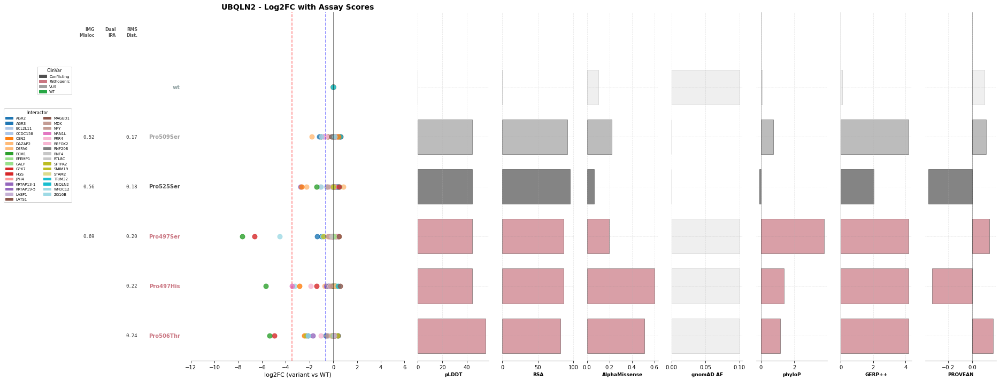

In [25]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='UBQLN2',
    orf_distances=orf_distances,
    all_assay_df=all_assay_df,
    palette_dict=palette_dict,
    save_path='./tmp/test.pdf'
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


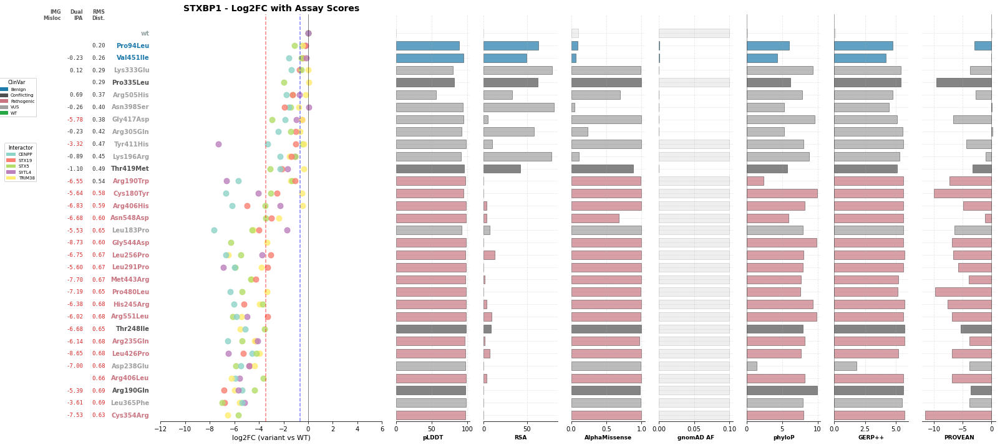

In [26]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    all_assay_df=all_assay_df,
    palette_dict=palette_dict
)

# Loop all genes and save plots

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/MLH1_log2fc_panel.pdf


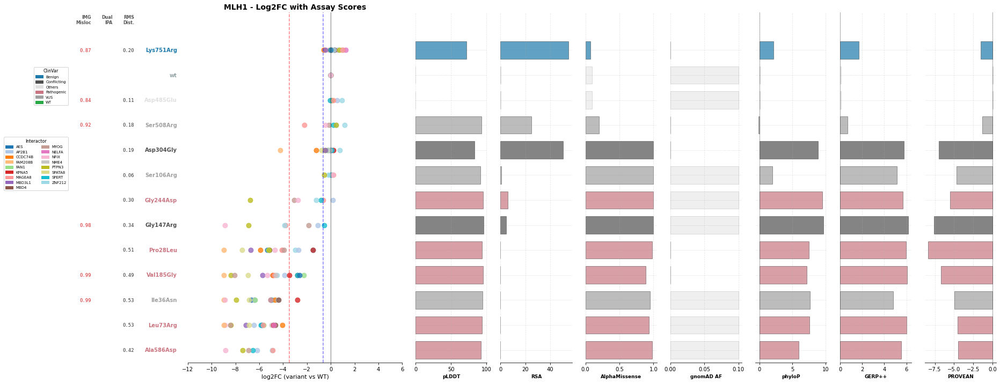

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/LITAF_log2fc_panel.pdf


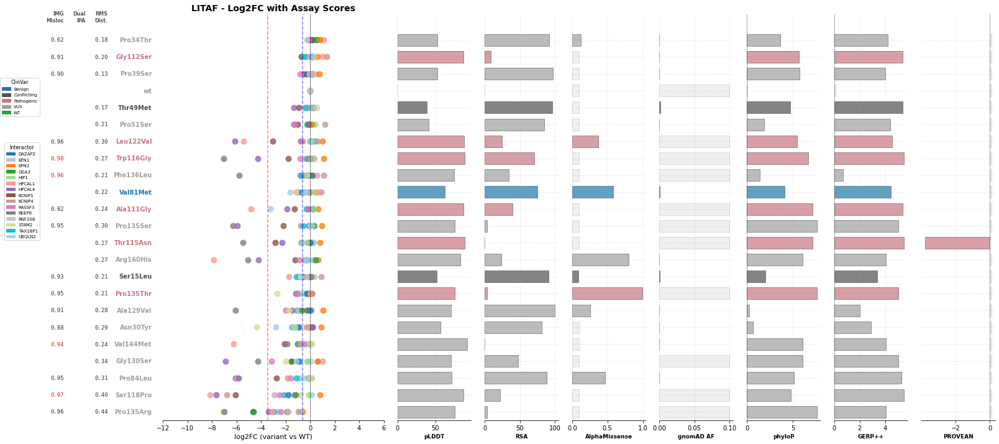

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/EMD_log2fc_panel.pdf


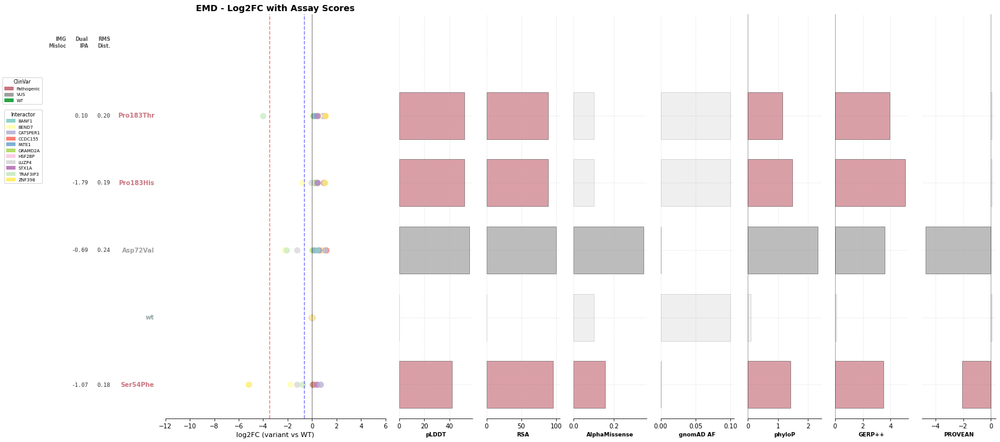

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GFAP_log2fc_panel.pdf


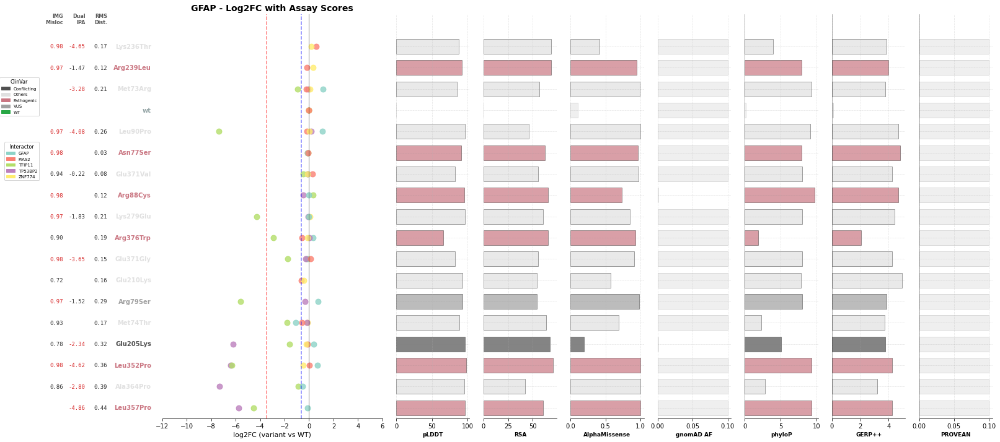

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT6A_log2fc_panel.pdf


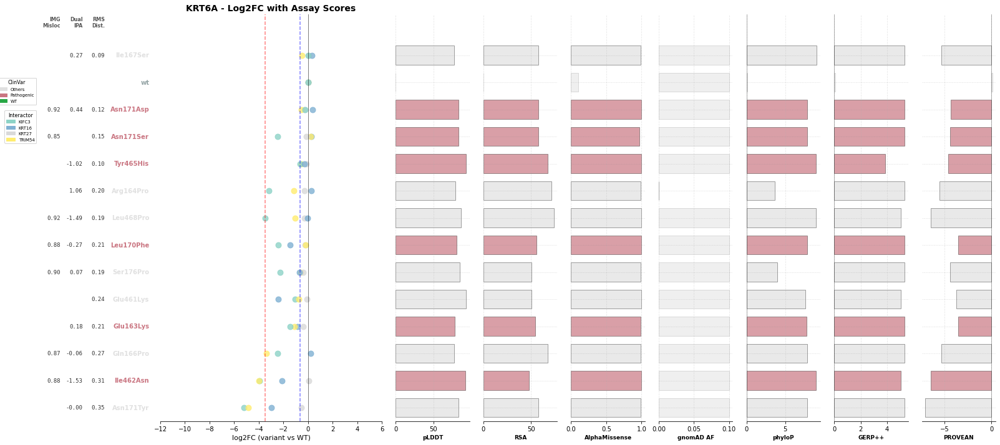

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PLP1_log2fc_panel.pdf


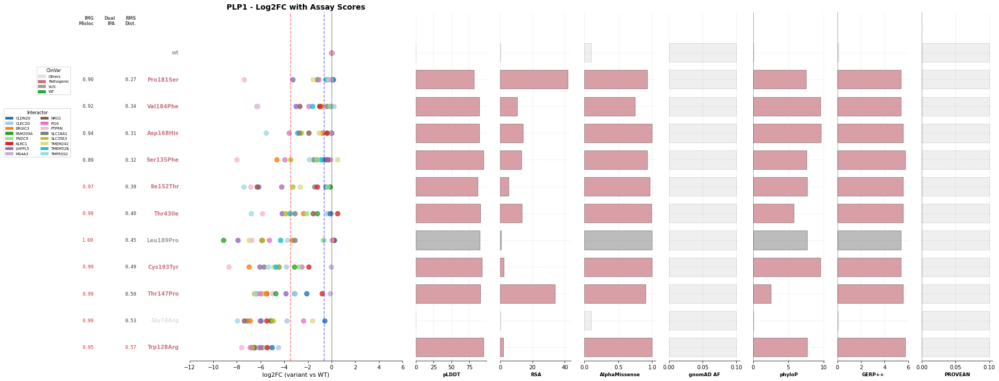

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HGD_log2fc_panel.pdf


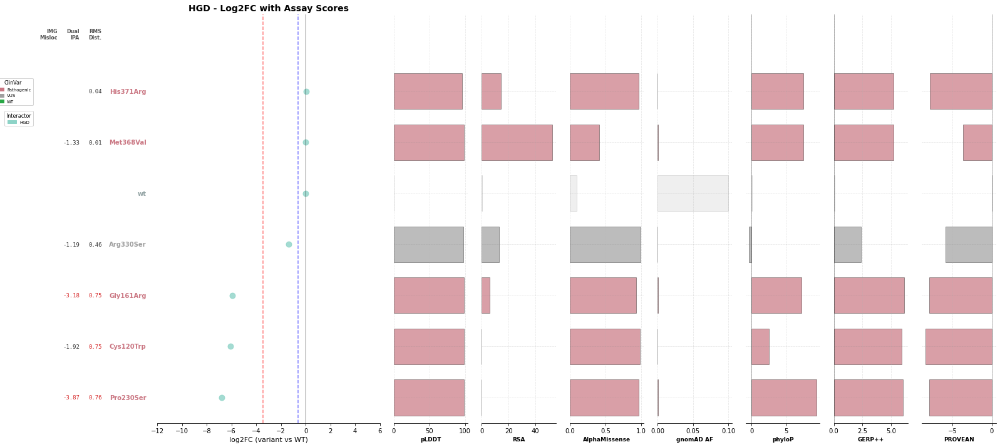

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/STXBP1_log2fc_panel.pdf


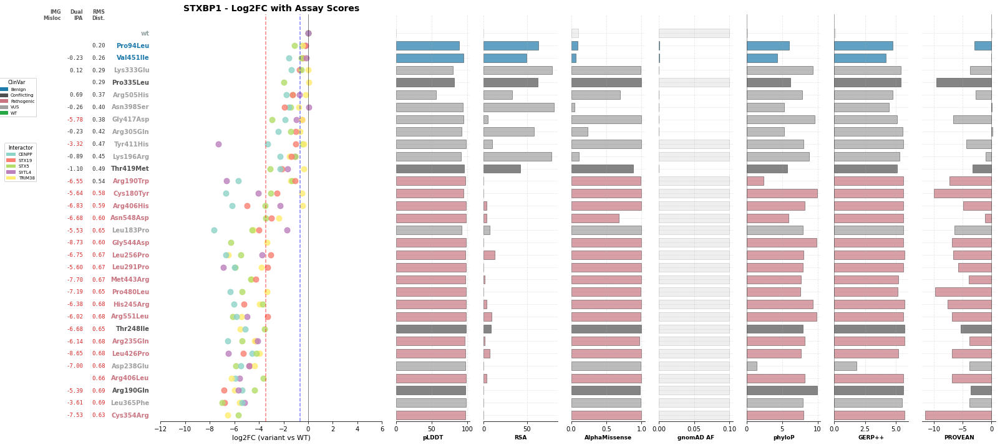

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/UBQLN2_log2fc_panel.pdf


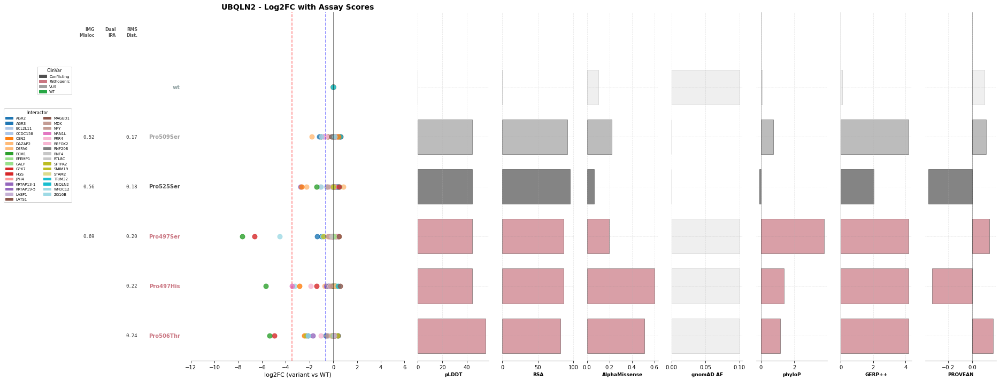

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT8_log2fc_panel.pdf


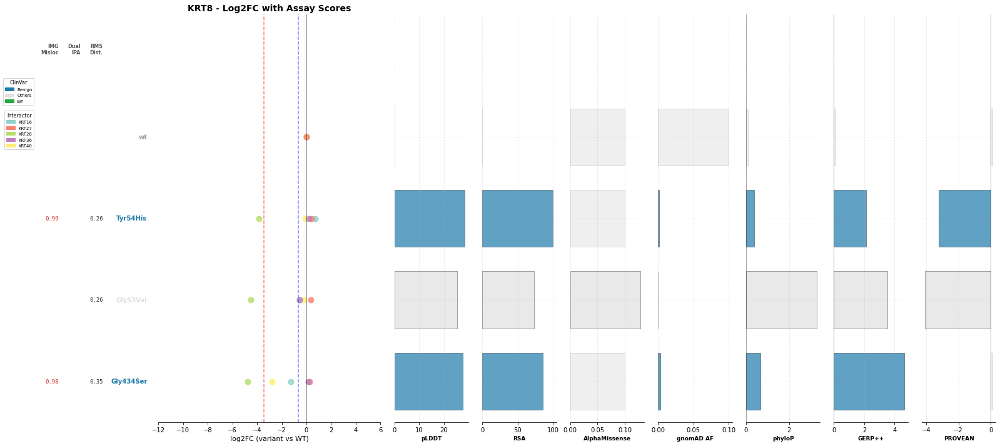

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/AGXT_log2fc_panel.pdf


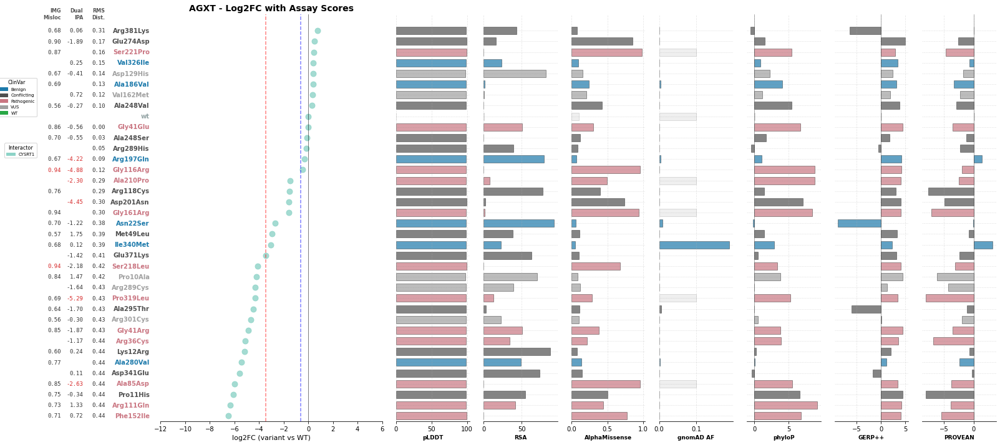

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HPRT1_log2fc_panel.pdf


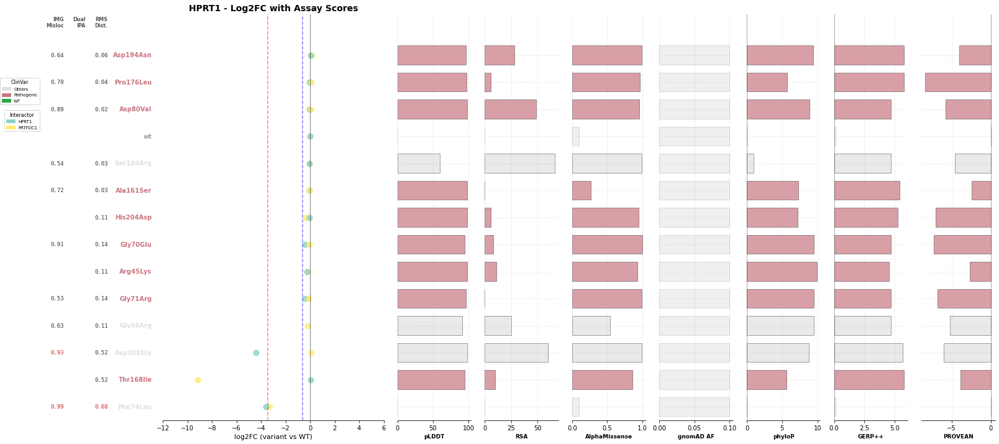

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TPM1_log2fc_panel.pdf


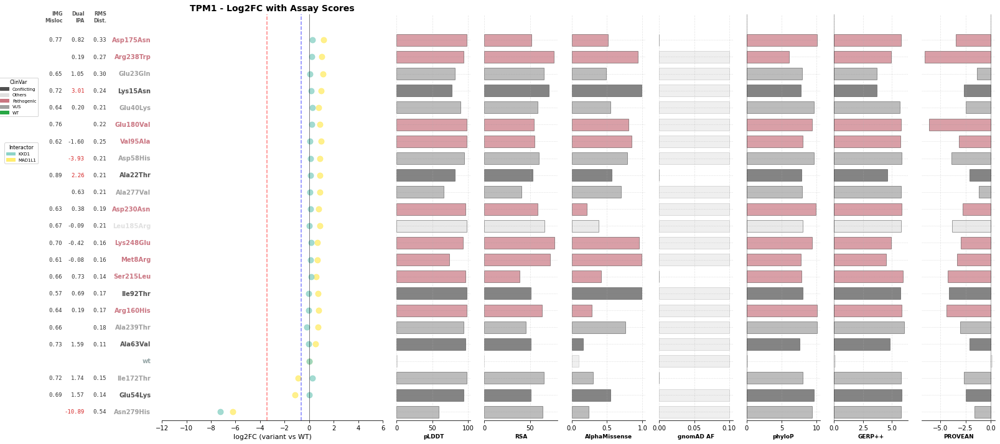

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SUOX_log2fc_panel.pdf


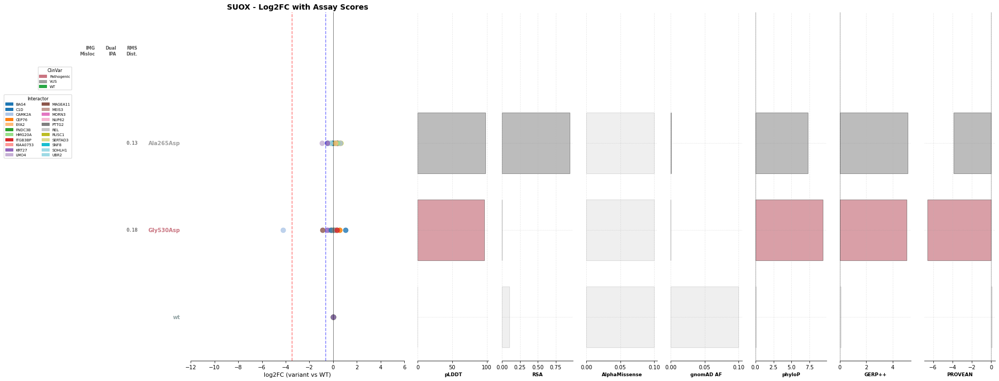

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TTR_log2fc_panel.pdf


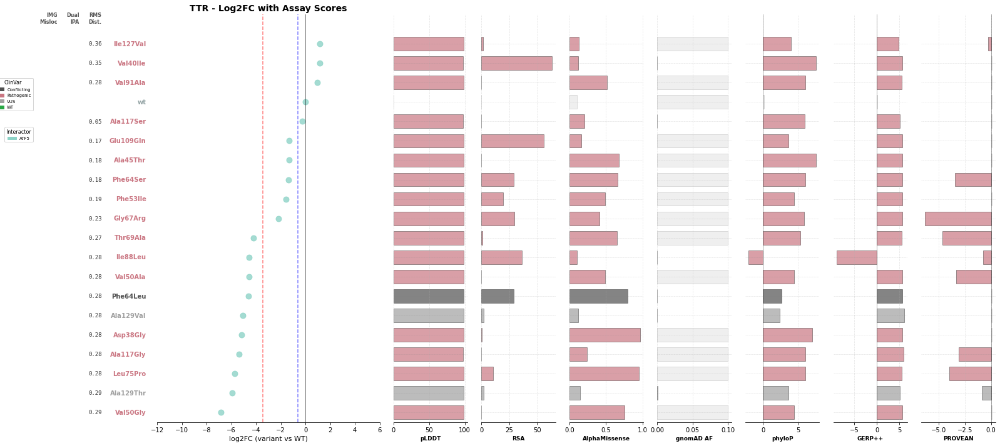

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TMEM43_log2fc_panel.pdf


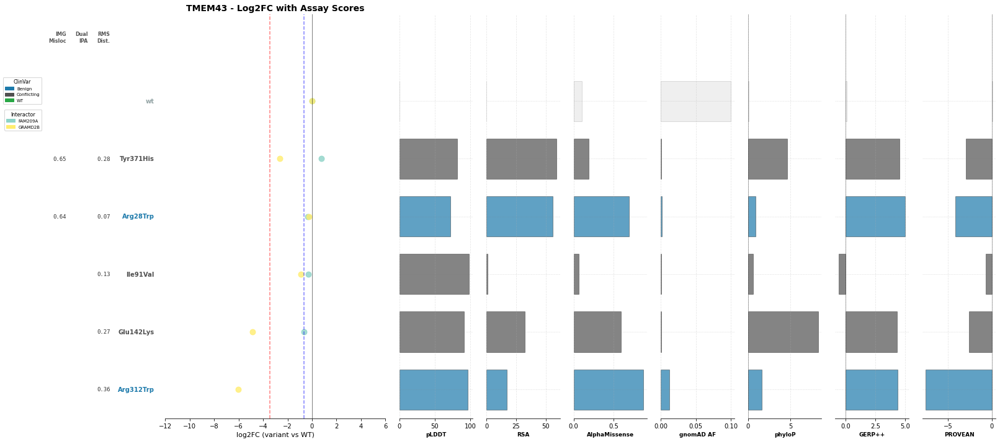

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/BAG3_log2fc_panel.pdf


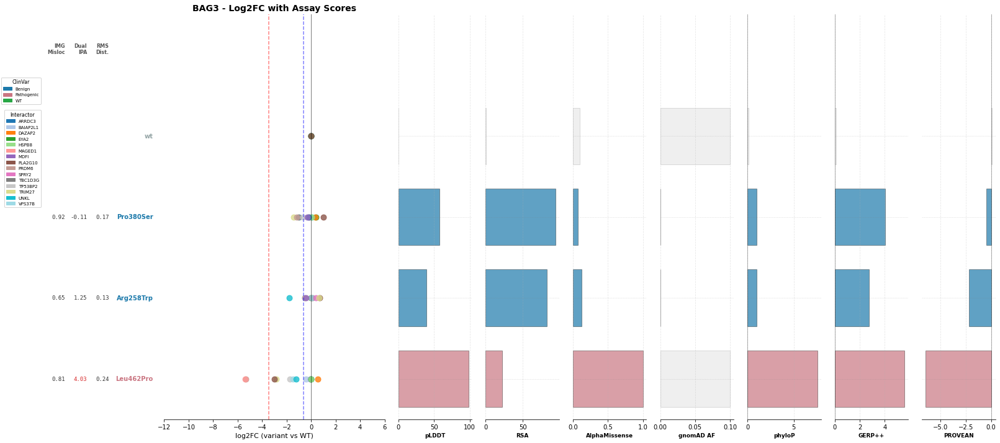

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HMBS_log2fc_panel.pdf


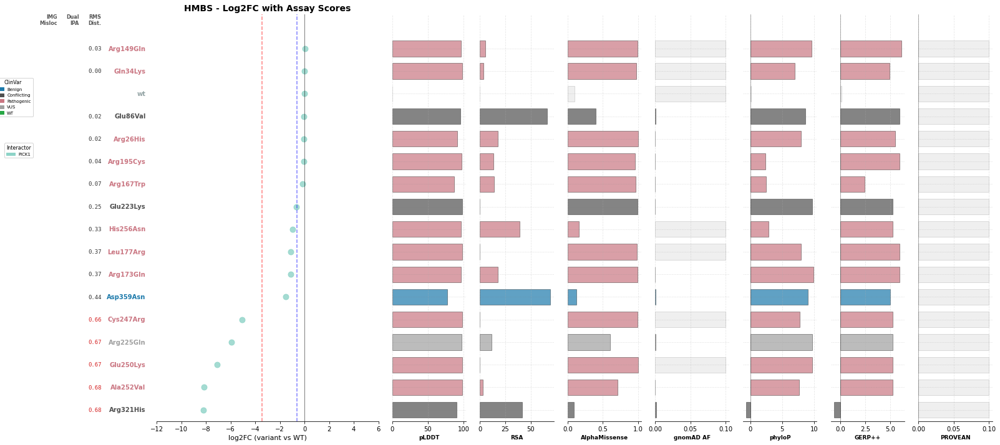

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KCNJ2_log2fc_panel.pdf


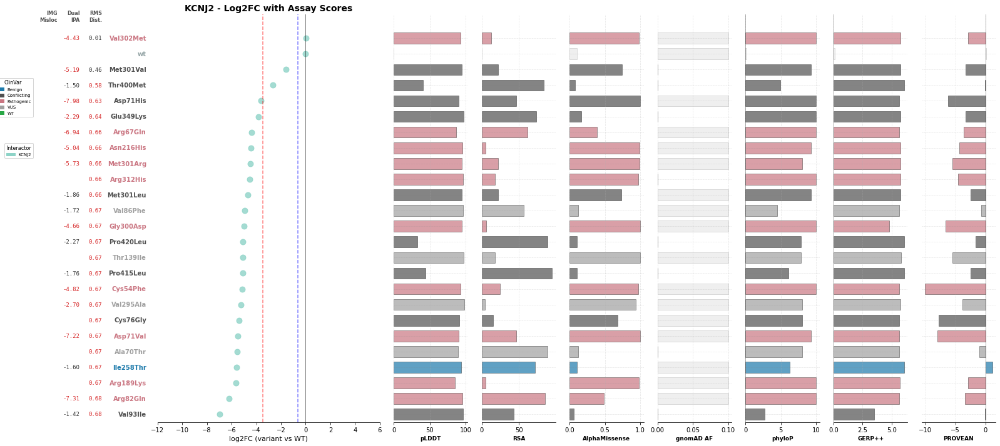

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PMP22_log2fc_panel.pdf


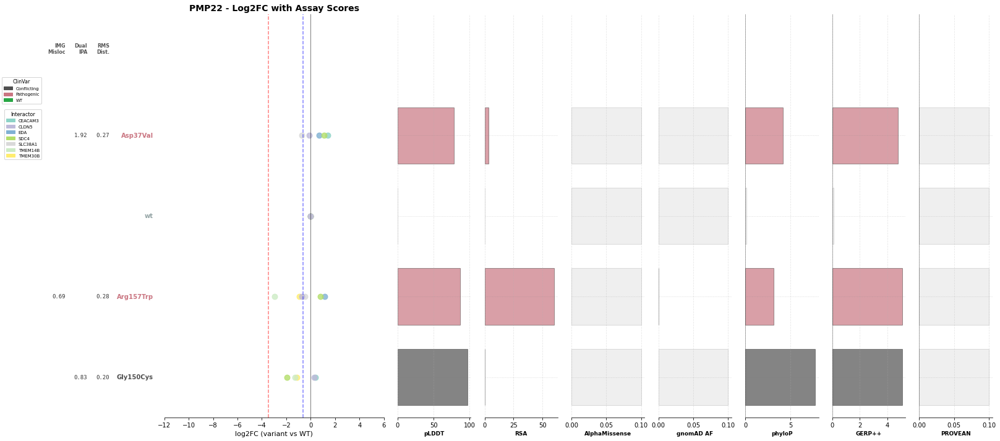

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SFTPC_log2fc_panel.pdf


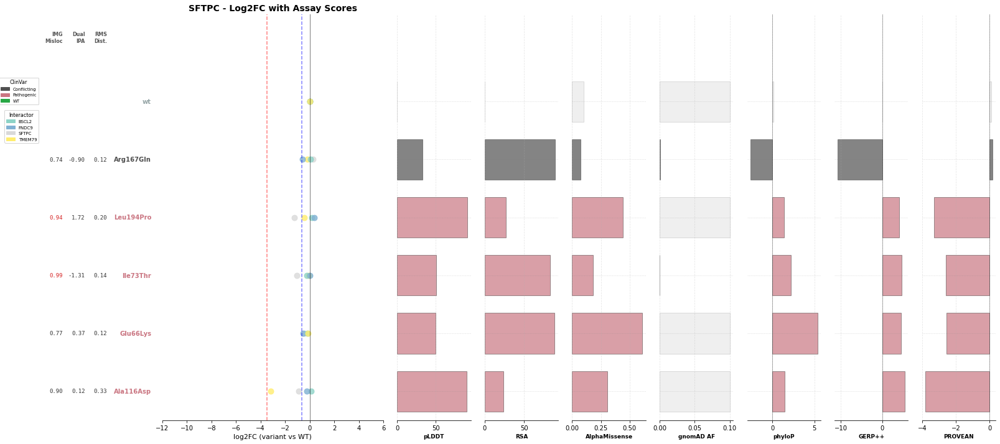

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/FA2H_log2fc_panel.pdf


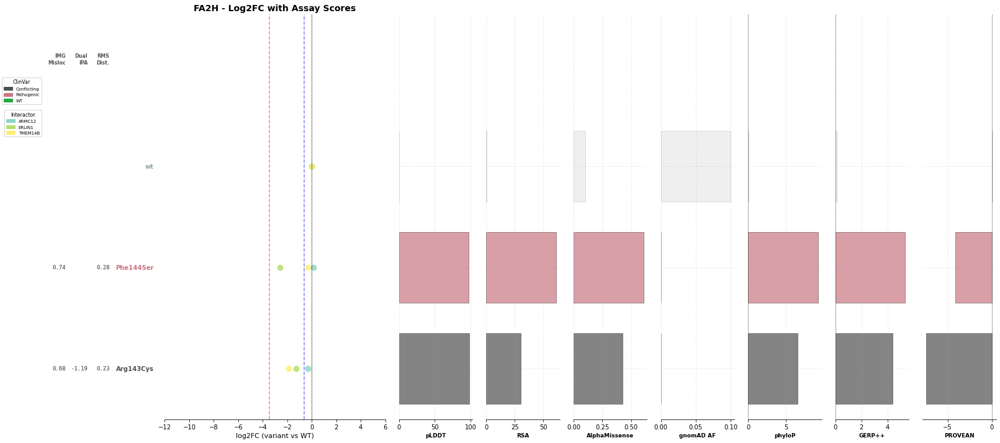

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SH3BP2_log2fc_panel.pdf


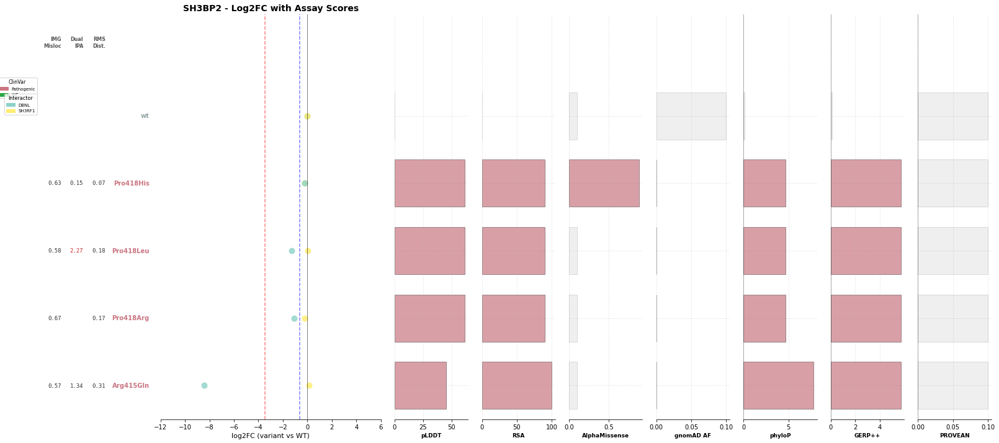

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/IL36RN_log2fc_panel.pdf


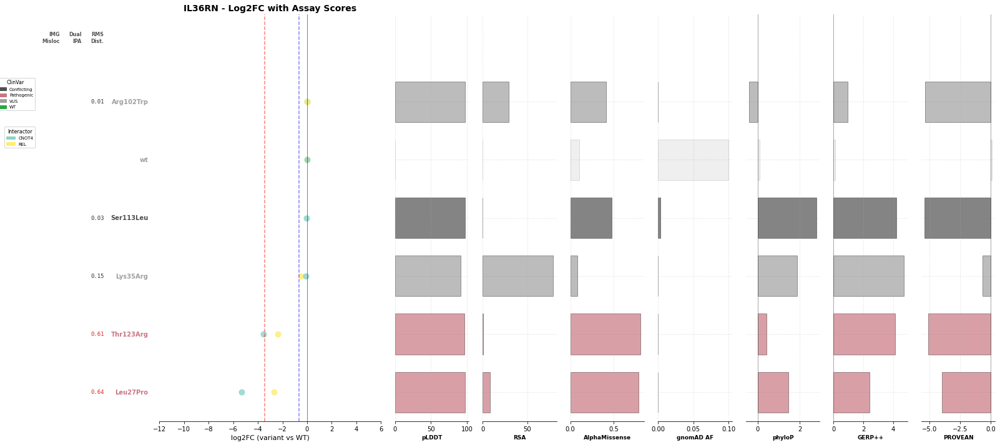

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/MVK_log2fc_panel.pdf


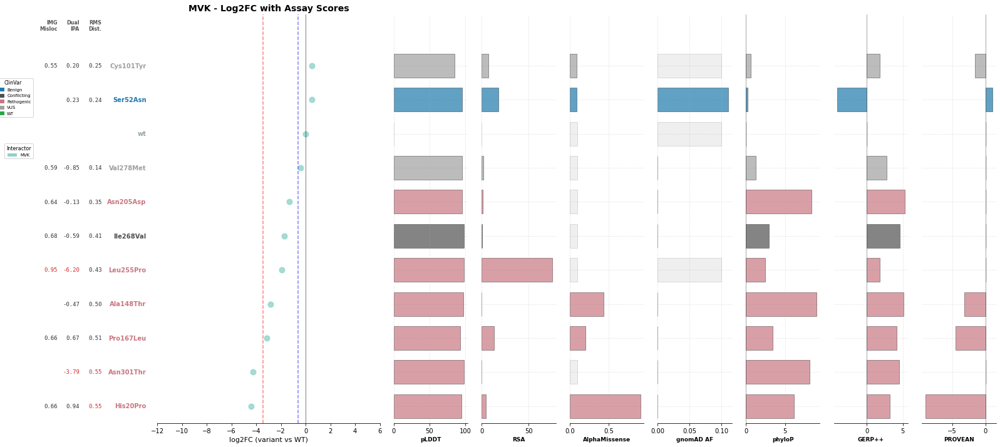

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HBD_log2fc_panel.pdf


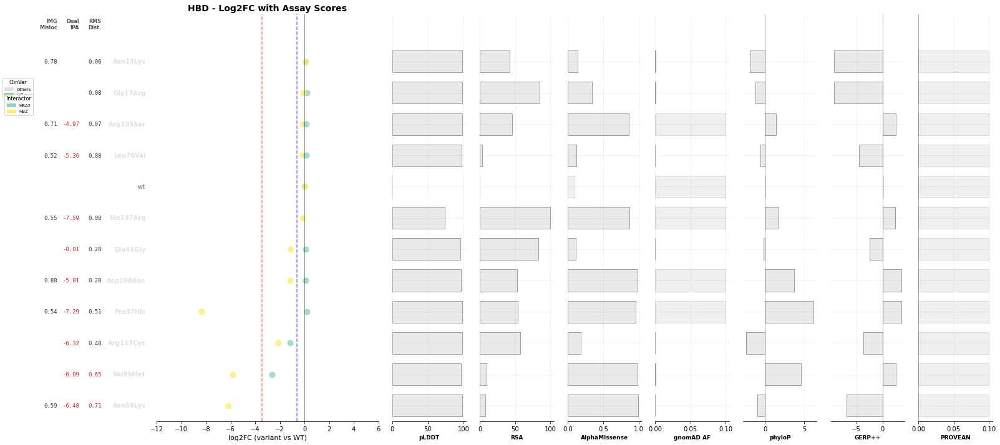

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SMAD3_log2fc_panel.pdf


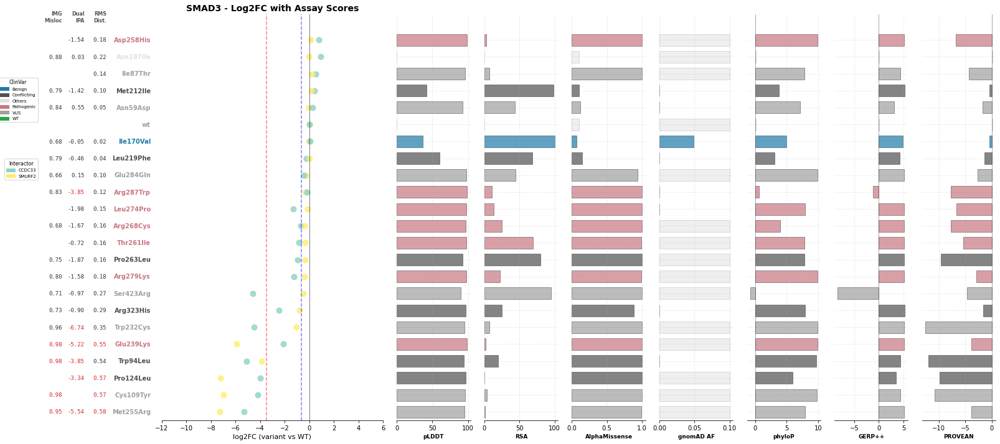

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/COQ8A_log2fc_panel.pdf


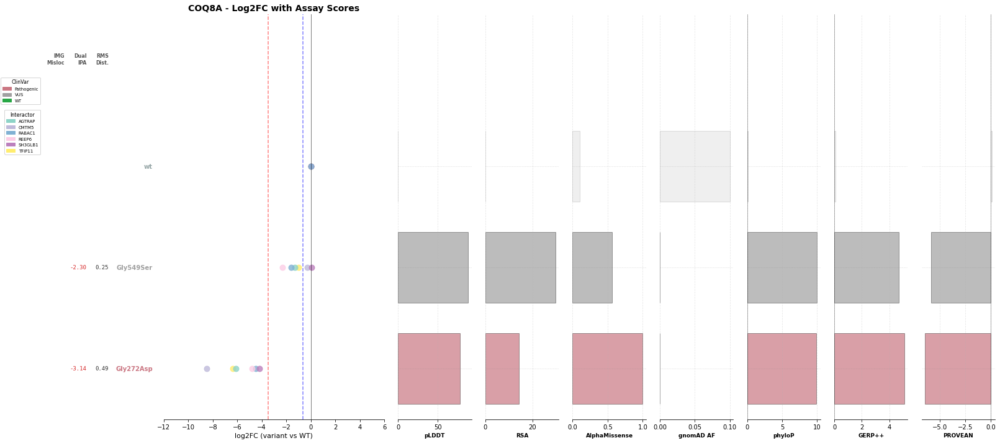

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KCTD7_log2fc_panel.pdf


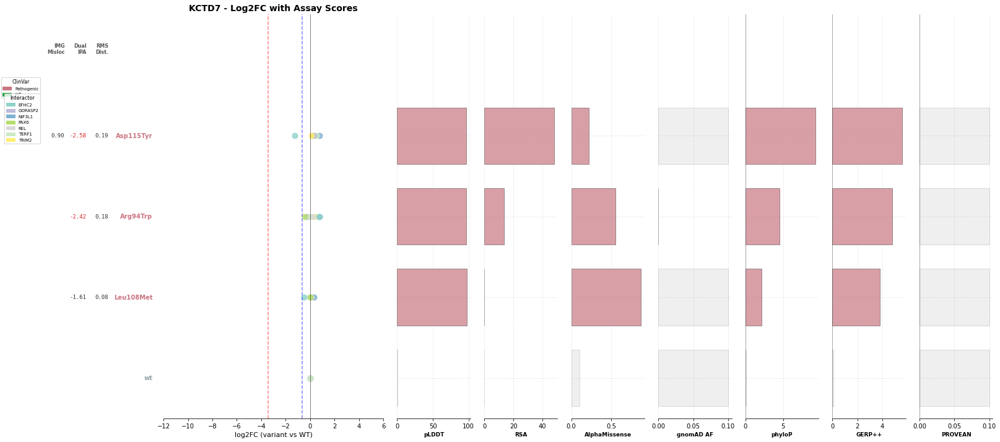

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TH_log2fc_panel.pdf


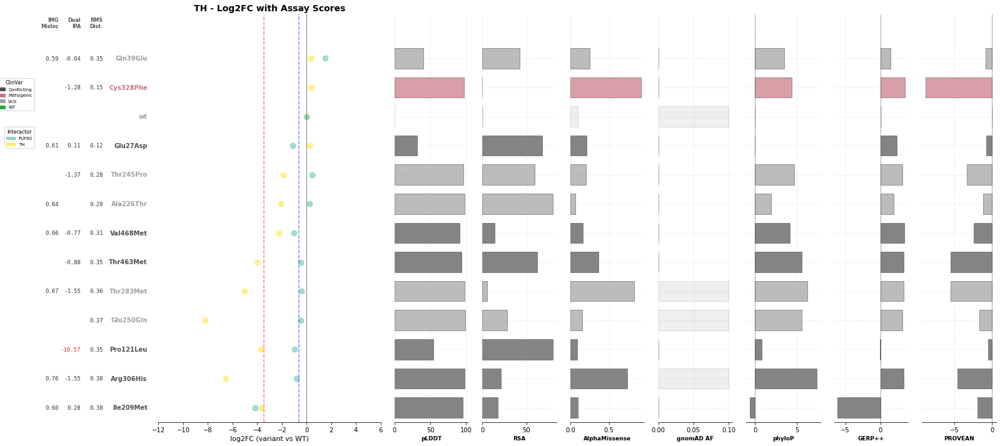

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SMARCB1_log2fc_panel.pdf


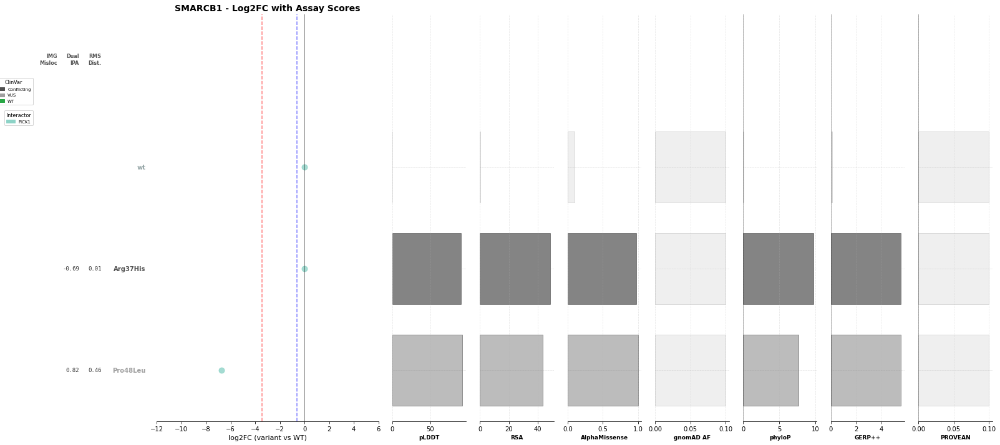

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NAA10_log2fc_panel.pdf


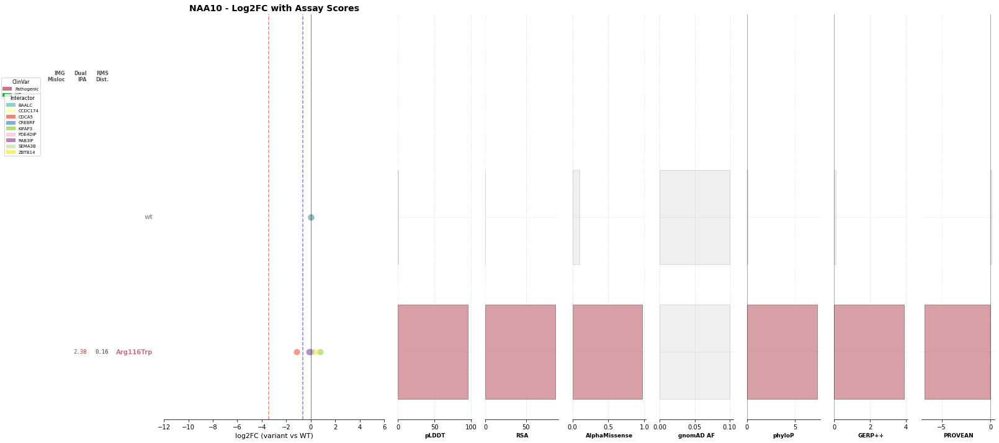

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GSS_log2fc_panel.pdf


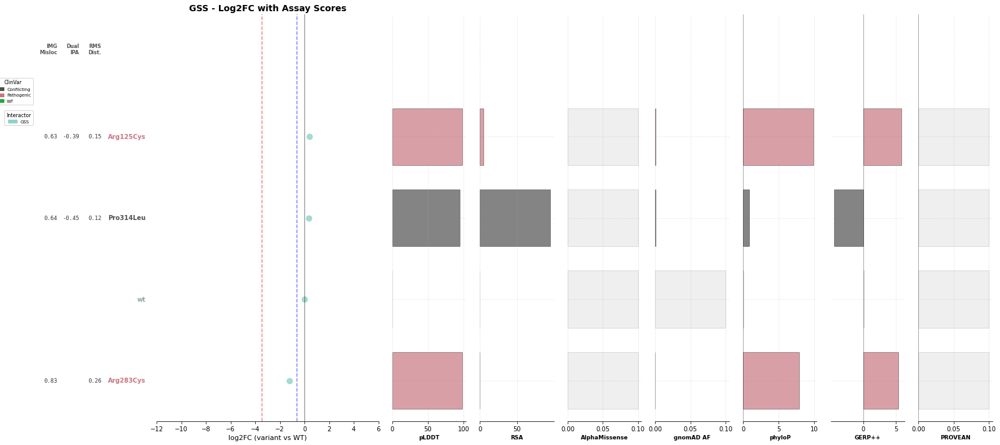

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ALAS2_log2fc_panel.pdf


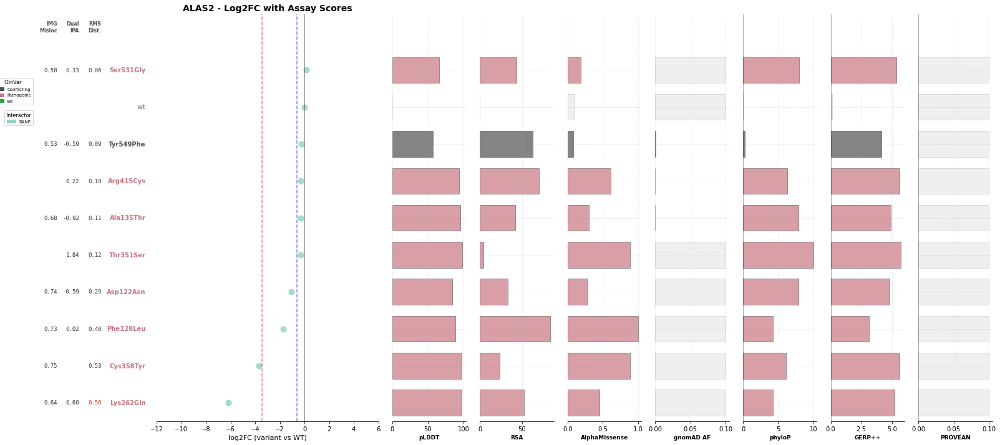

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GRN_log2fc_panel.pdf


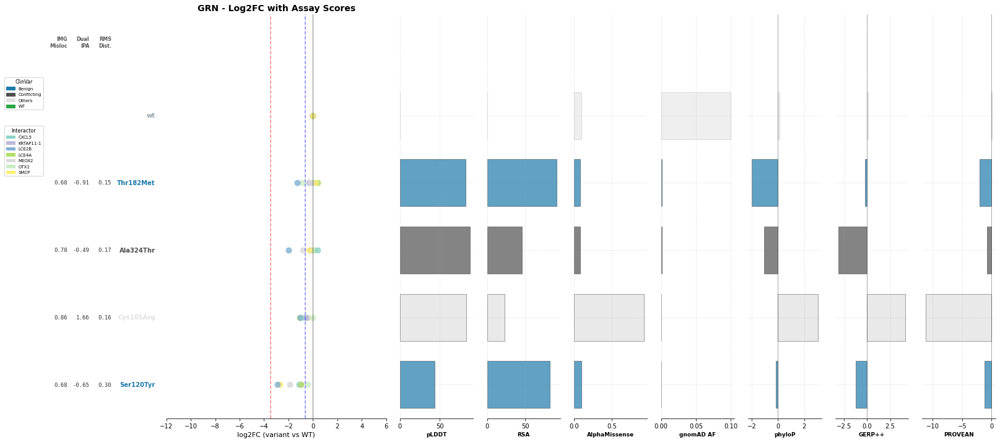

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PITX2_log2fc_panel.pdf


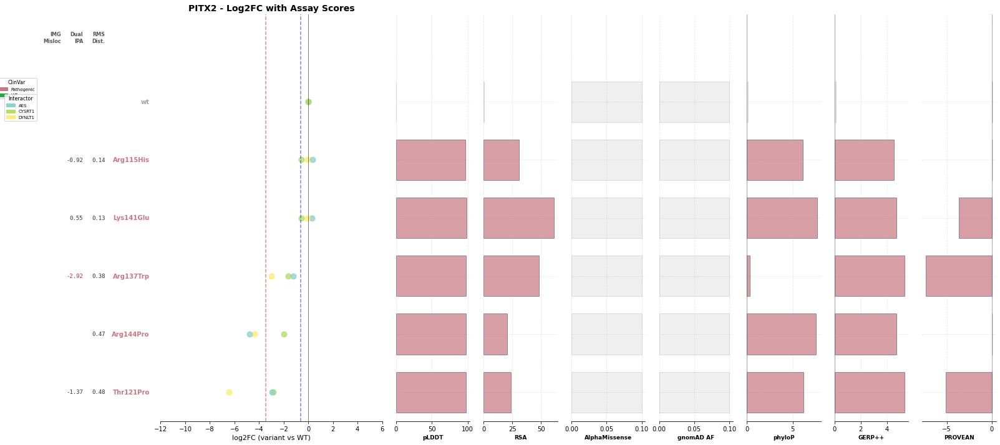

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ACSF3_log2fc_panel.pdf


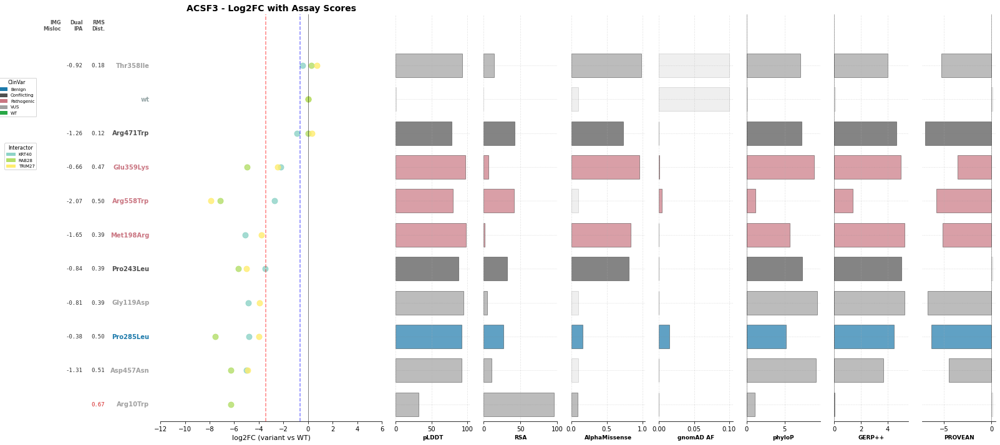

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ASNS_log2fc_panel.pdf


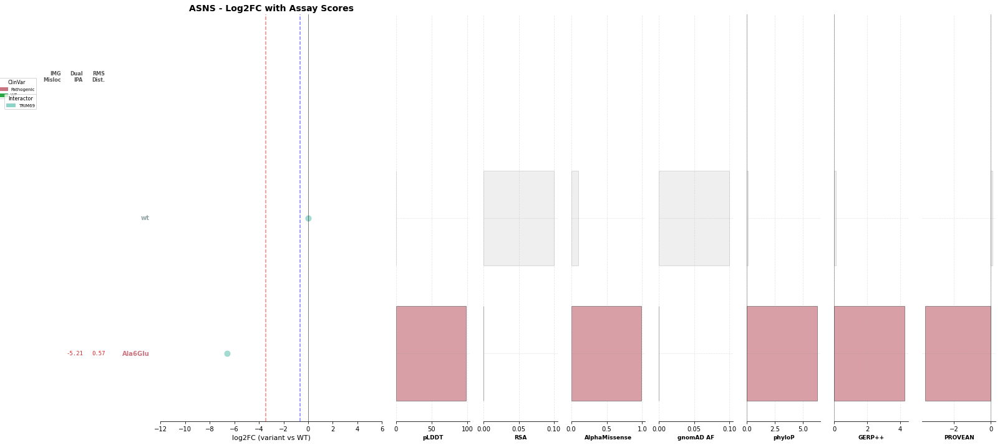

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT2_log2fc_panel.pdf


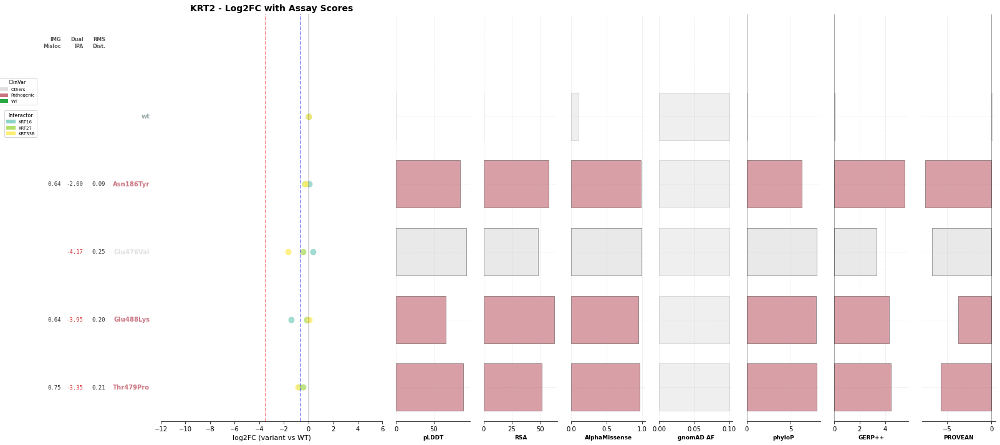

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PRPS1_log2fc_panel.pdf


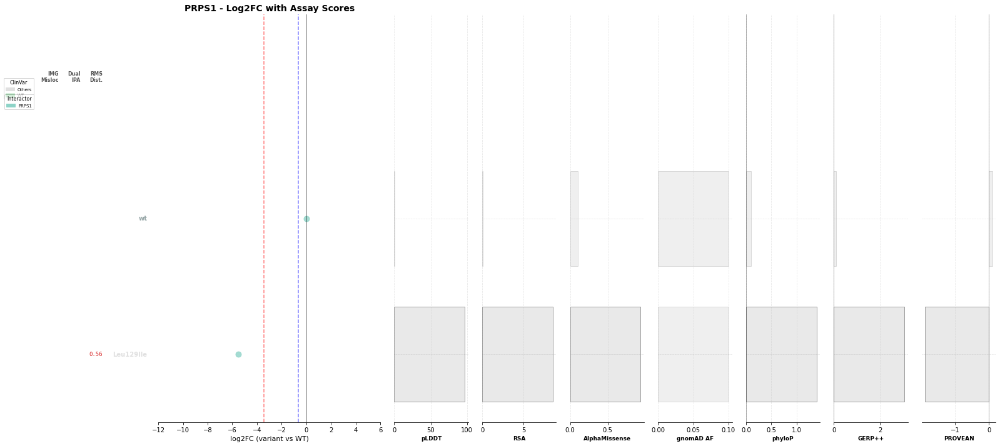

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PRKAR1A_log2fc_panel.pdf


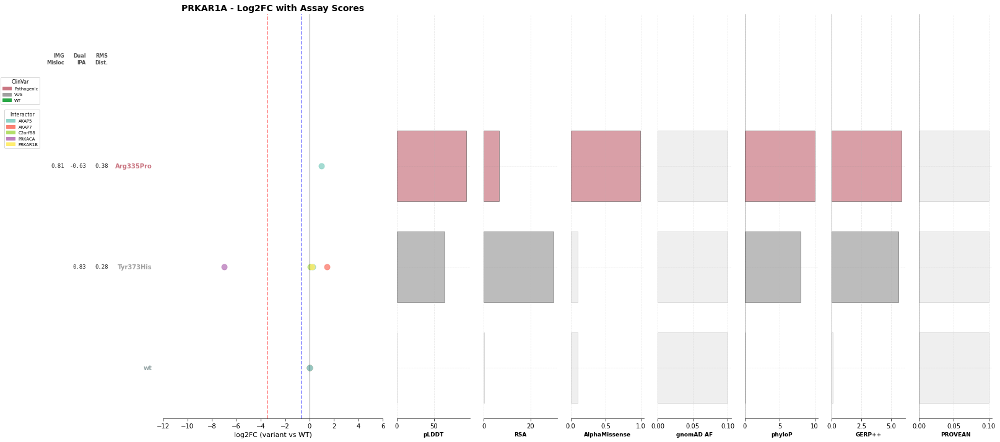

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT86_log2fc_panel.pdf


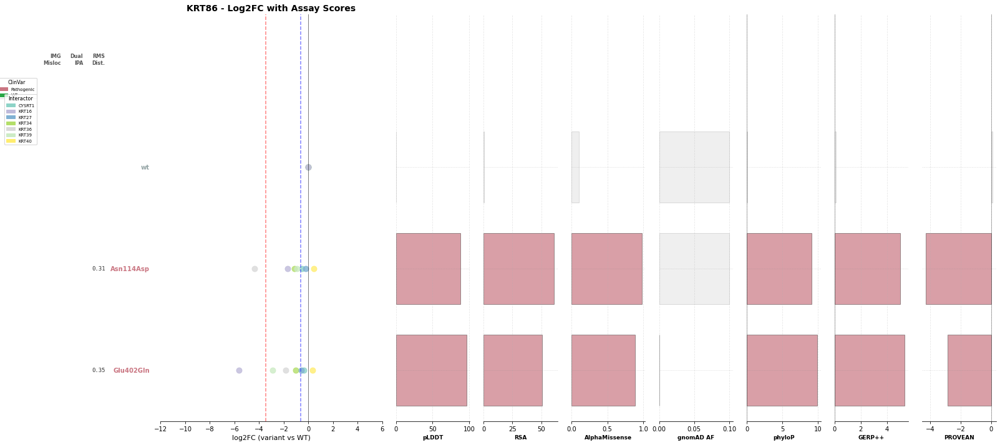

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/IER3IP1_log2fc_panel.pdf


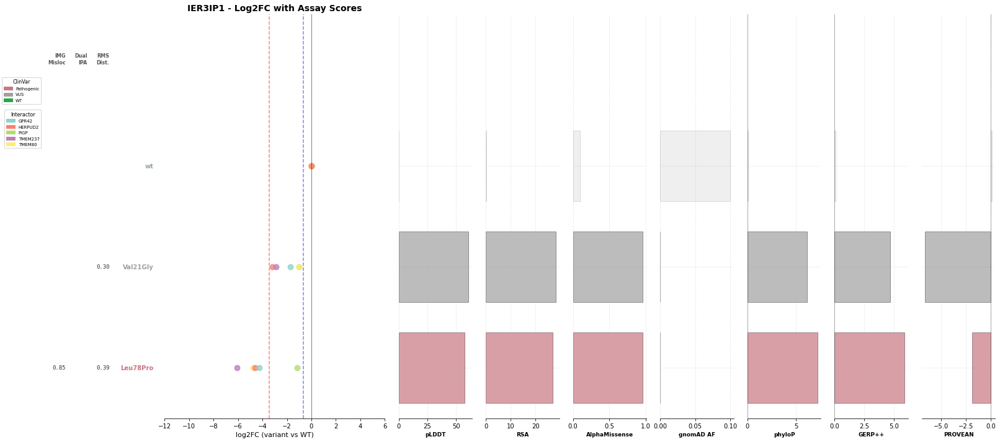

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GCK_log2fc_panel.pdf


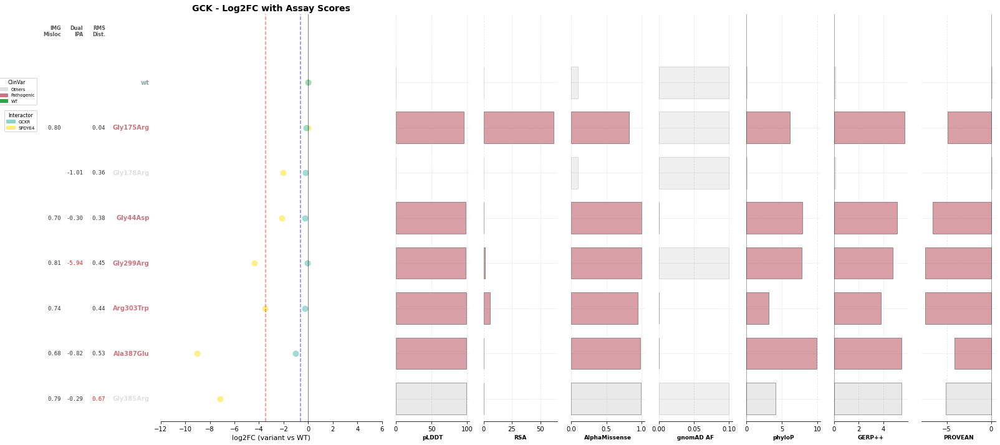

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/UROD_log2fc_panel.pdf


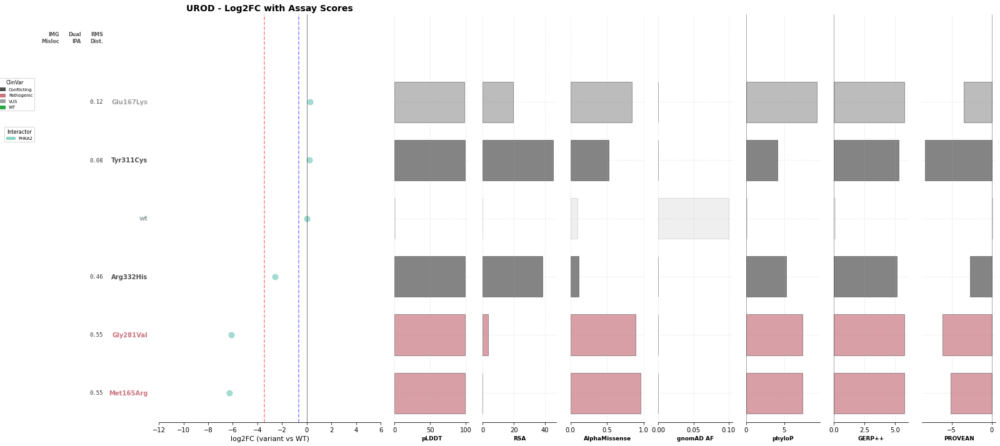

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NEUROG3_log2fc_panel.pdf


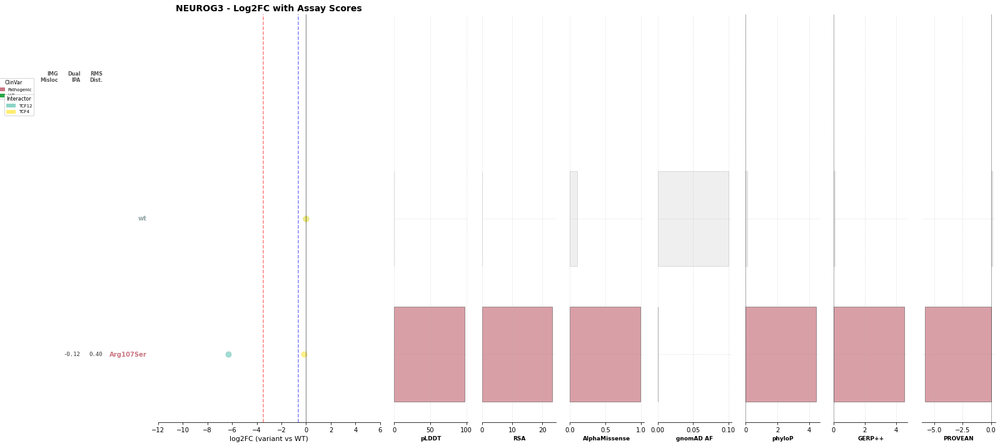

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/STAR_log2fc_panel.pdf


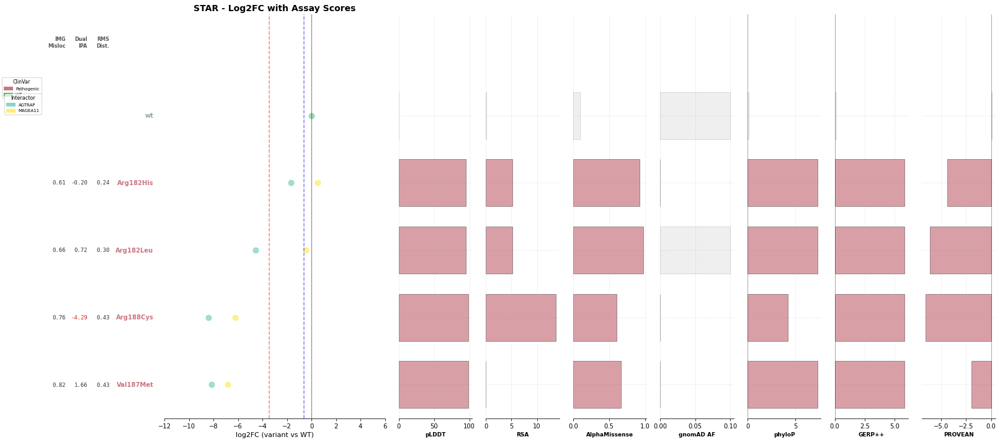

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NMNAT1_log2fc_panel.pdf


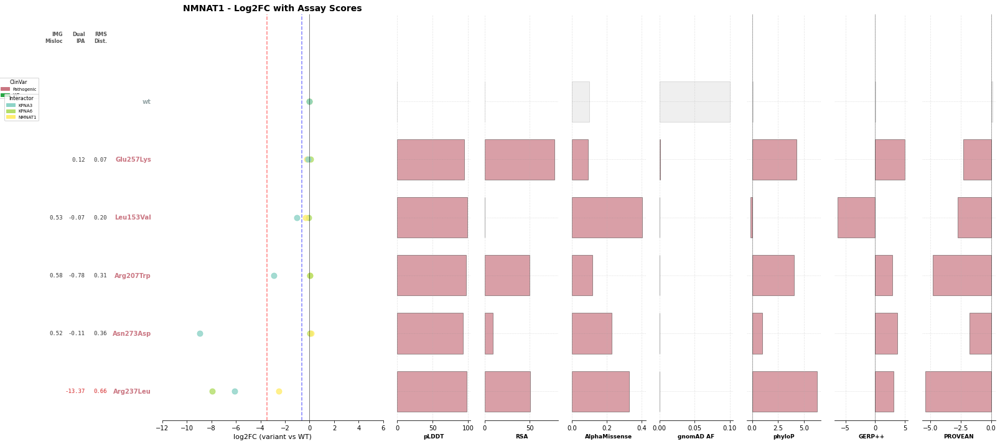

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SIX1_log2fc_panel.pdf


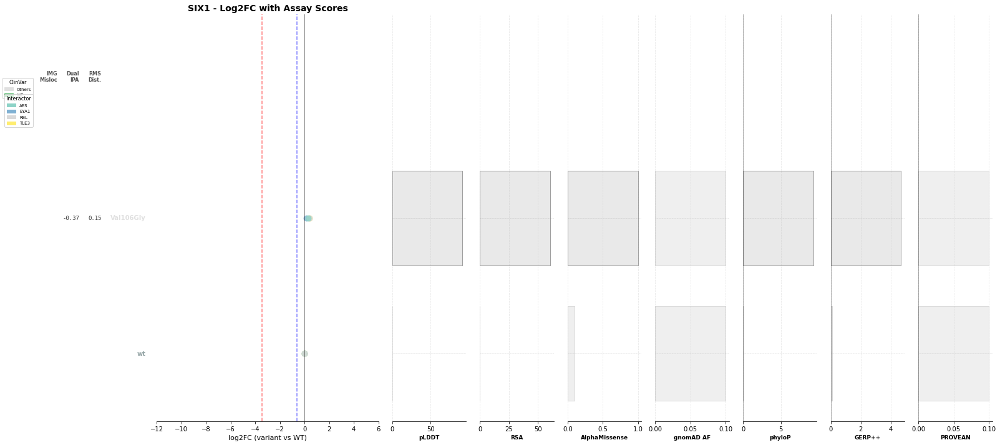

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GMPPB_log2fc_panel.pdf


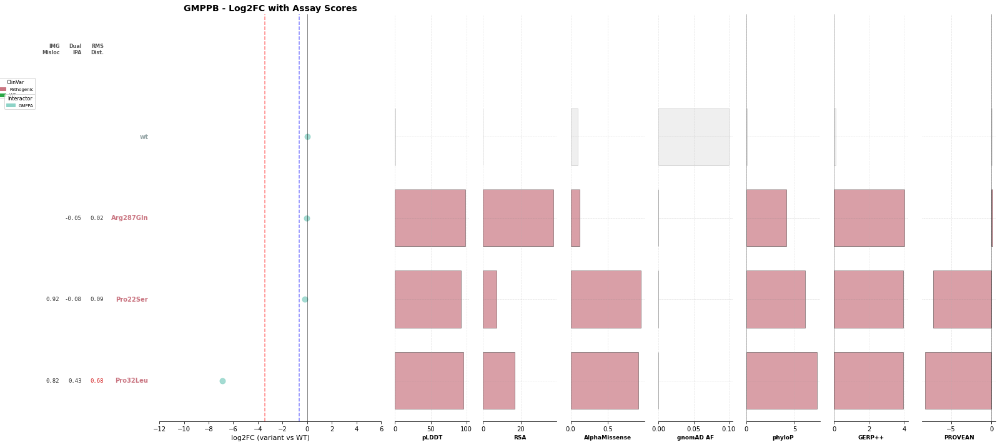

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PCCA_log2fc_panel.pdf


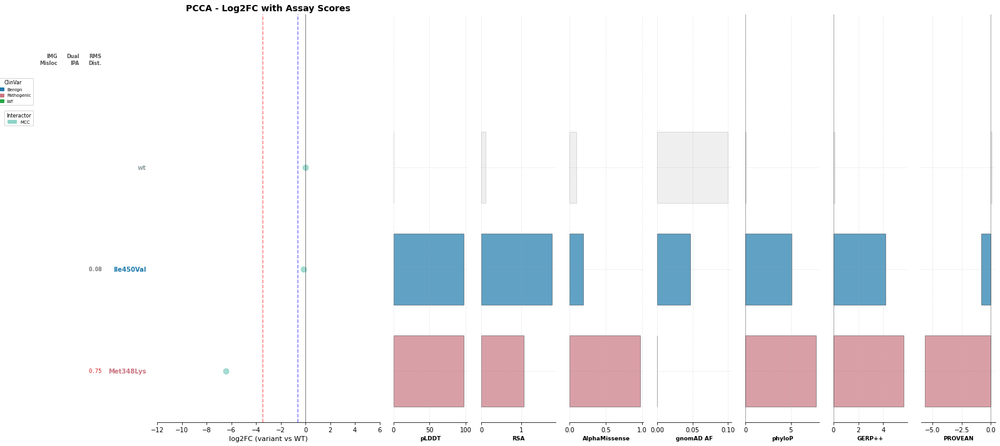

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ZMYND10_log2fc_panel.pdf


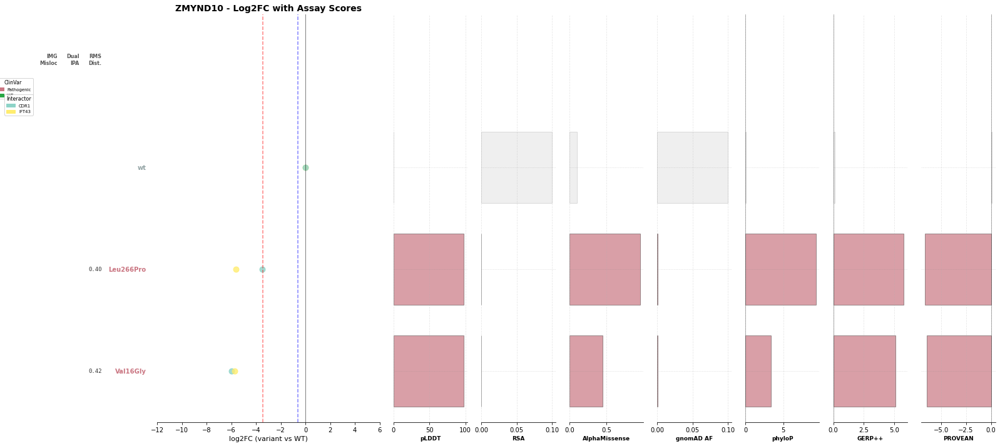

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GALE_log2fc_panel.pdf


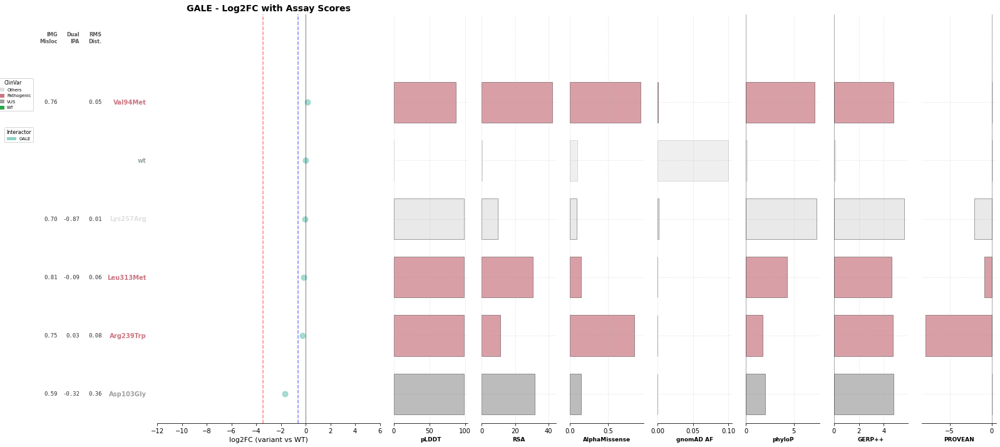

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/VHL_log2fc_panel.pdf


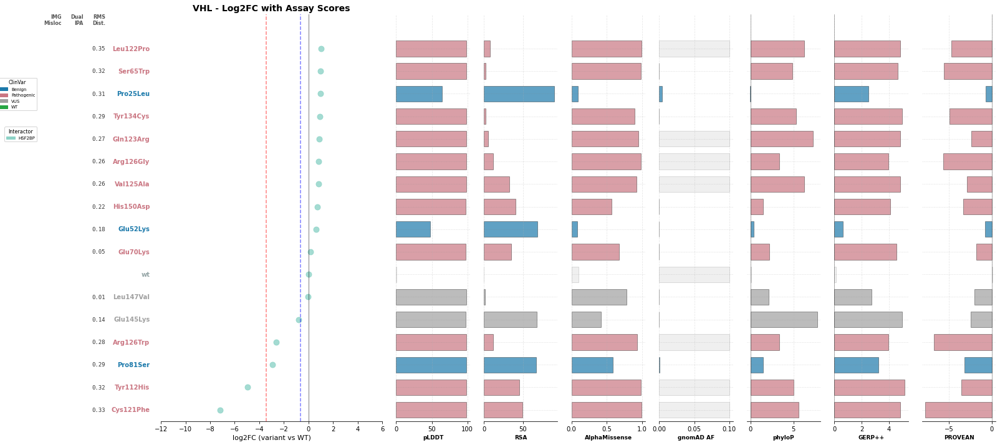

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/FBP1_log2fc_panel.pdf


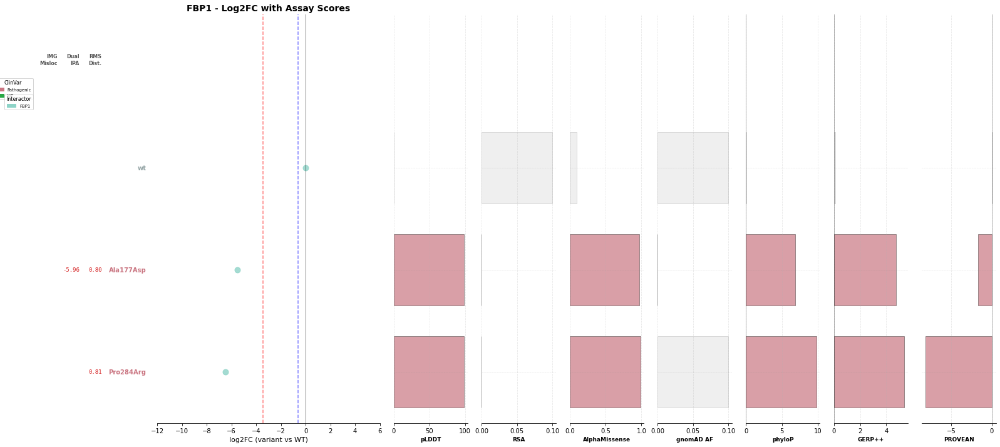

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PYGL_log2fc_panel.pdf


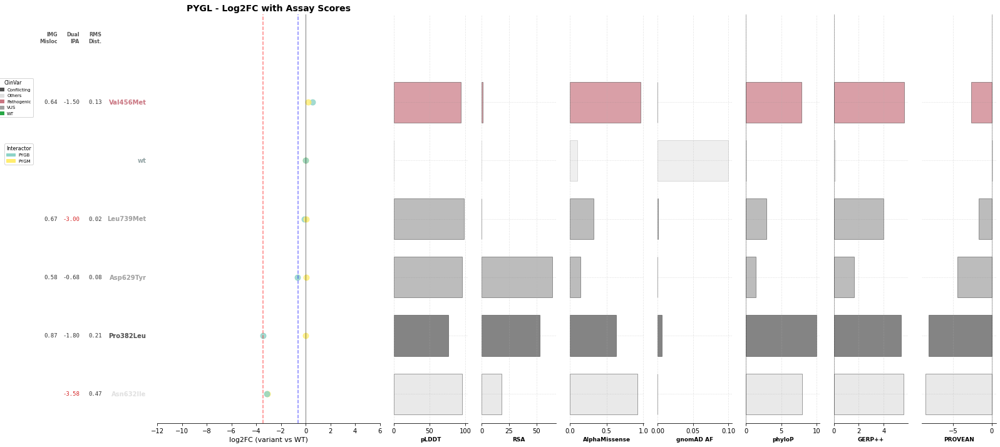

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/AIPL1_log2fc_panel.pdf


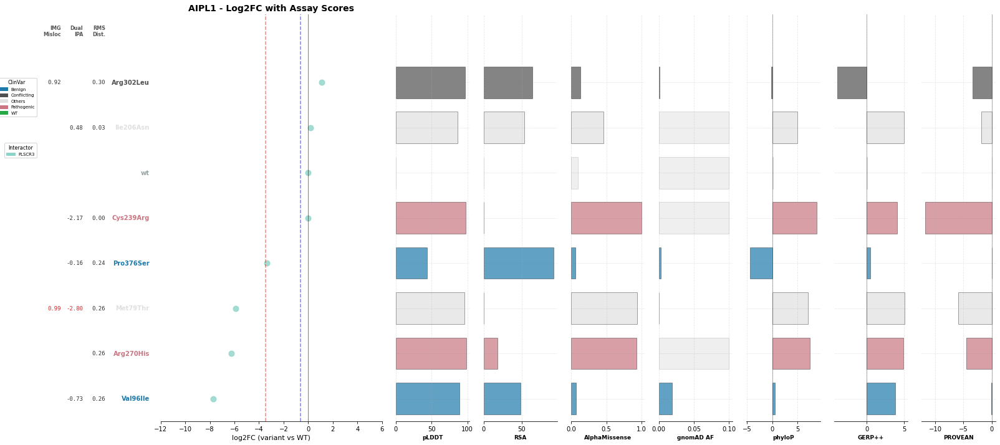

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/COL2A1_log2fc_panel.pdf


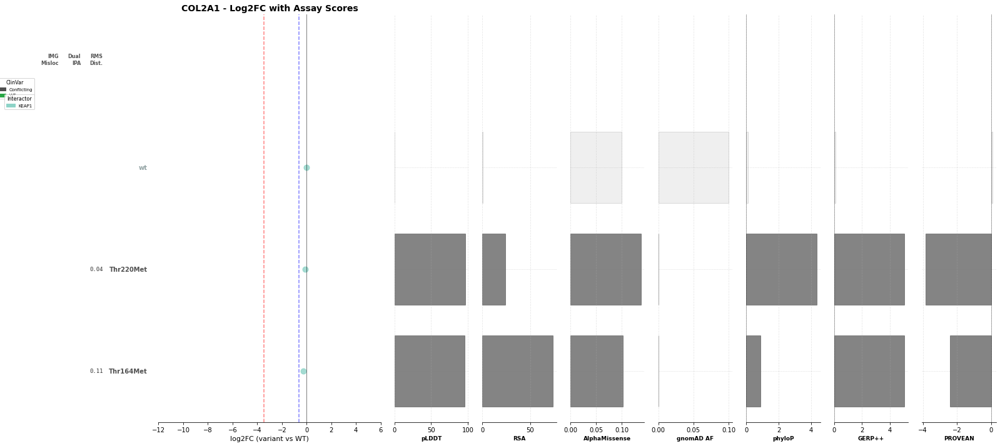

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PNKP_log2fc_panel.pdf


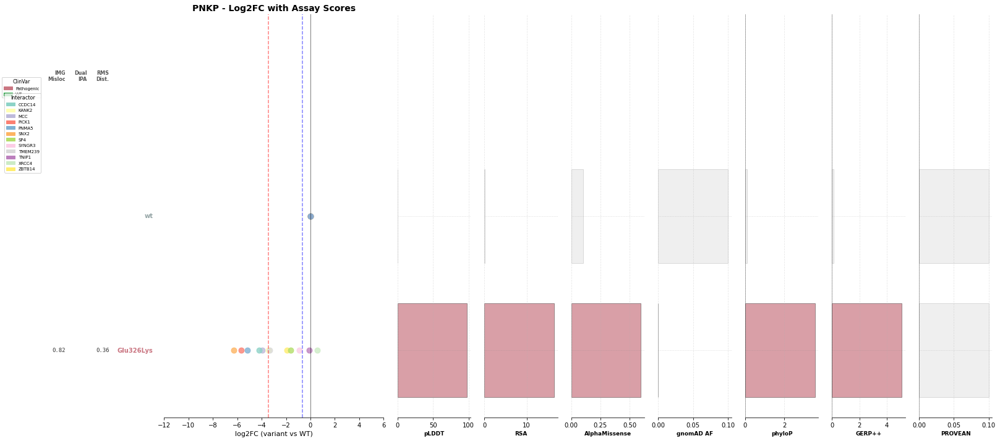

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KLHL3_log2fc_panel.pdf


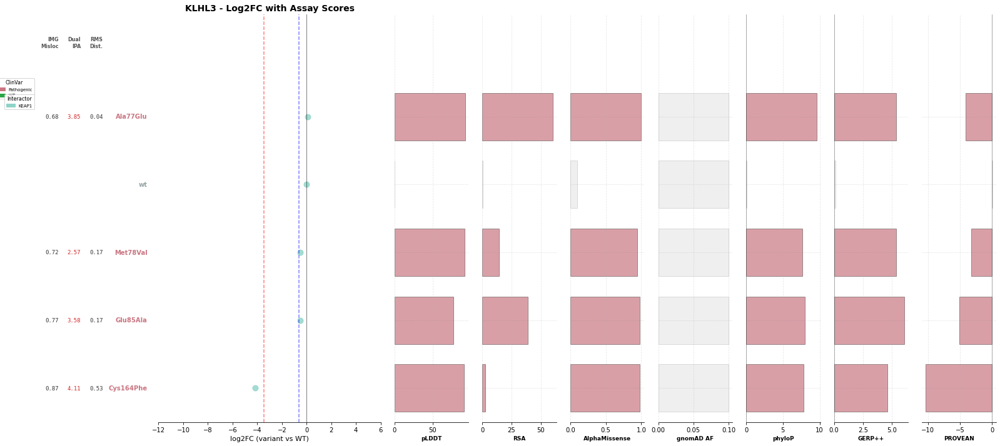

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KCTD1_log2fc_panel.pdf


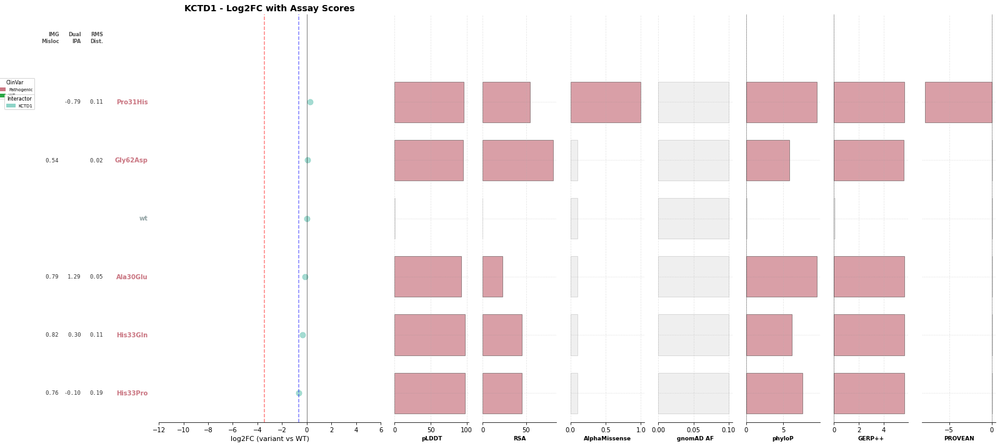

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/CRYAB_log2fc_panel.pdf


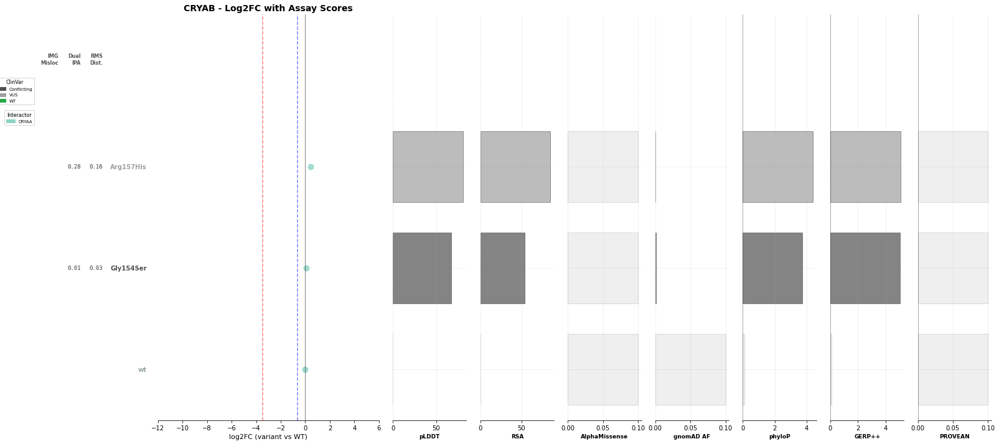

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NR0B1_log2fc_panel.pdf


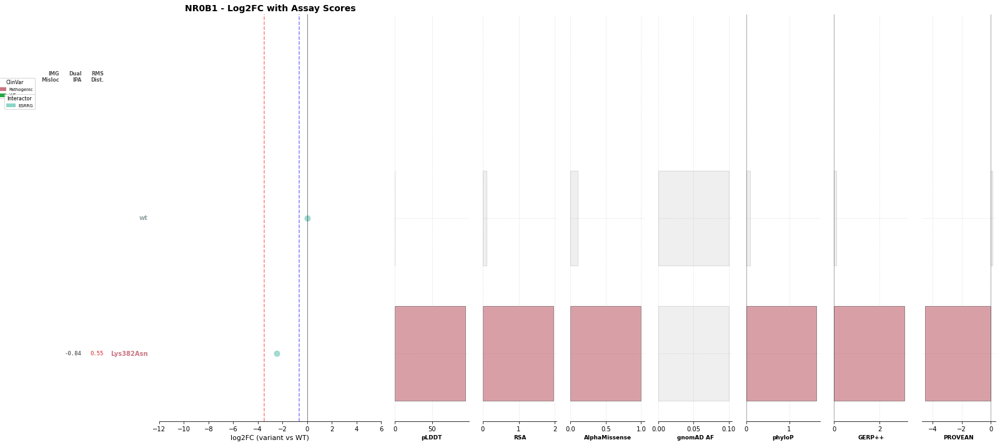

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/THAP1_log2fc_panel.pdf


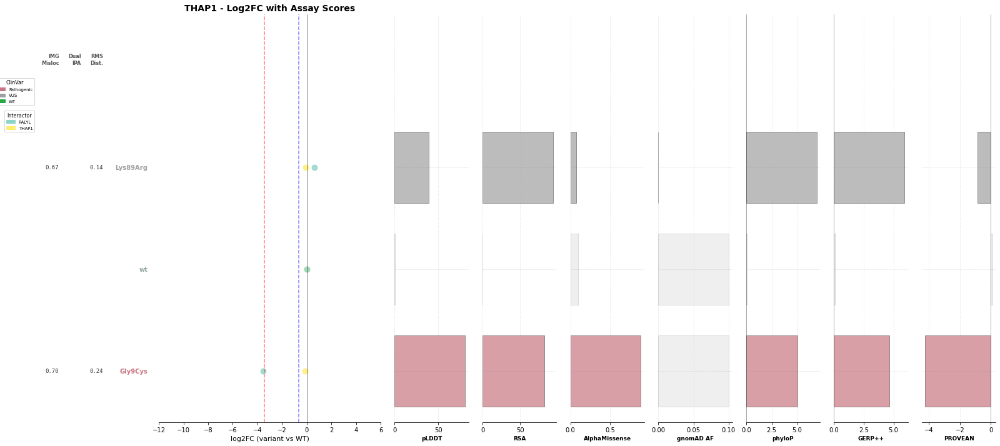

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/CLN6_log2fc_panel.pdf


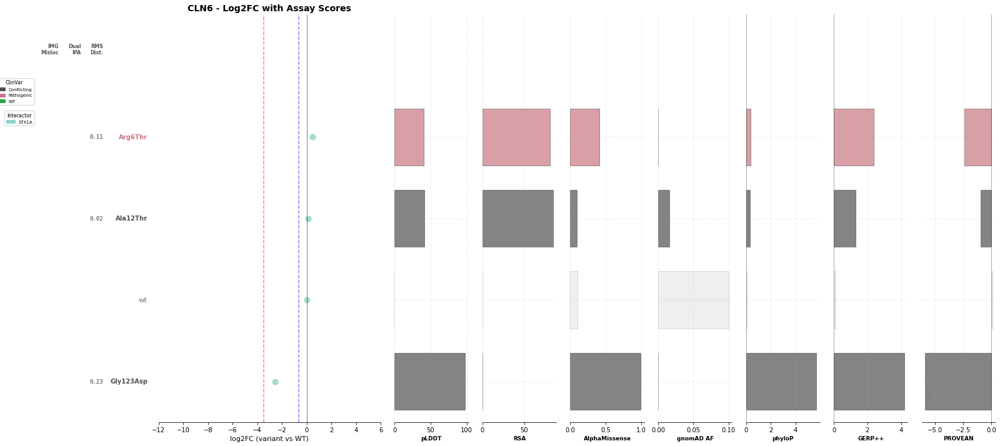

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TPK1_log2fc_panel.pdf


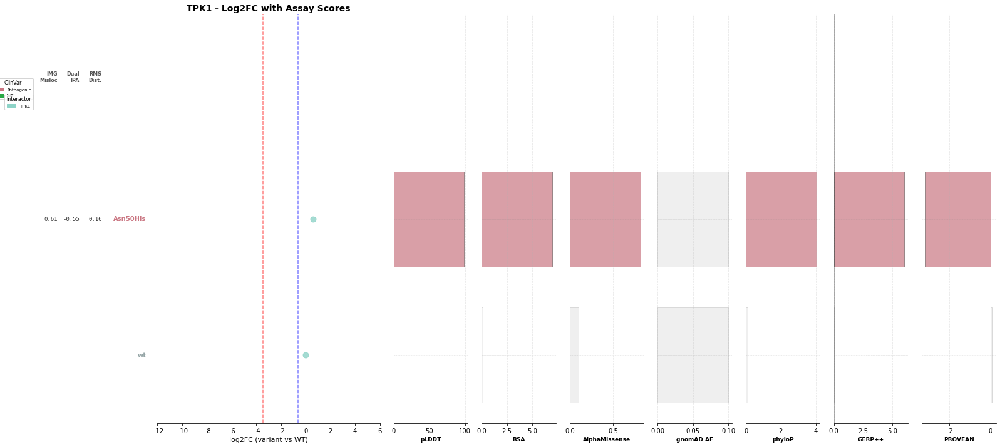

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT5_log2fc_panel.pdf


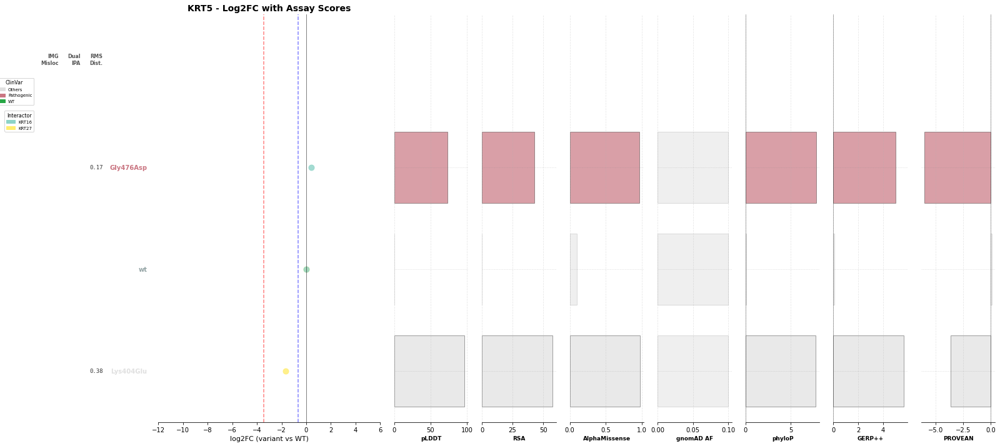

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NCF2_log2fc_panel.pdf


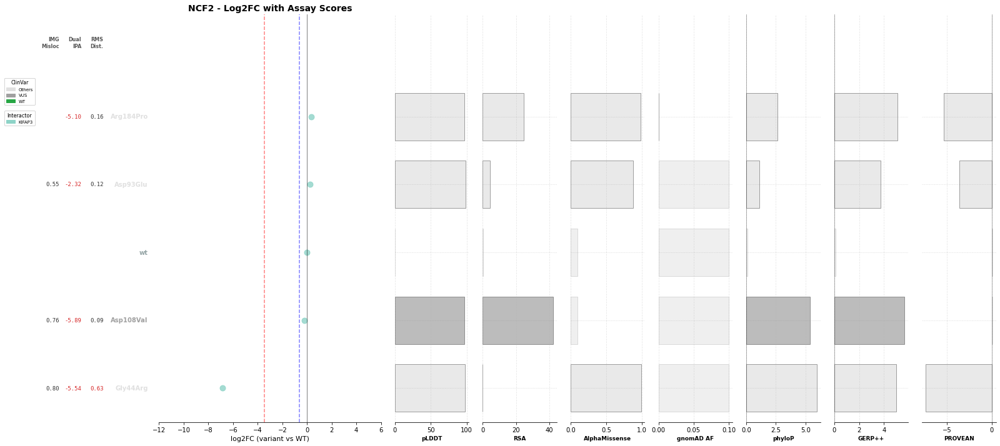

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PKP2_log2fc_panel.pdf


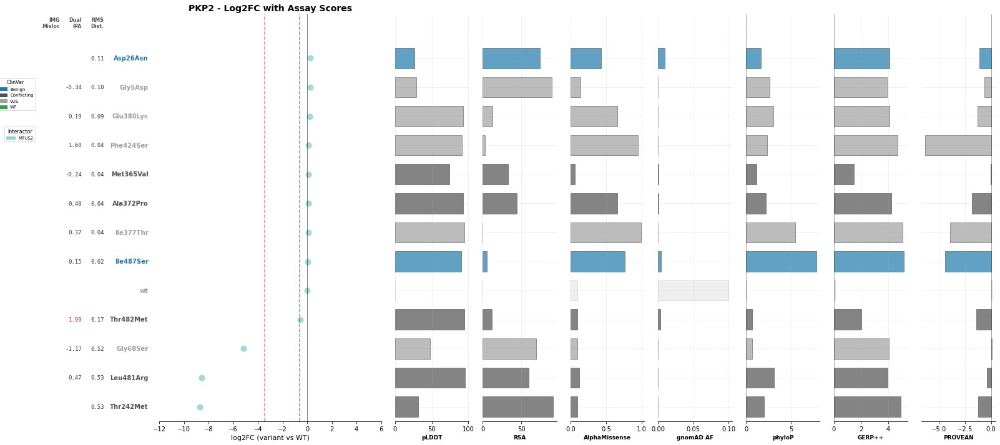

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/CHN1_log2fc_panel.pdf


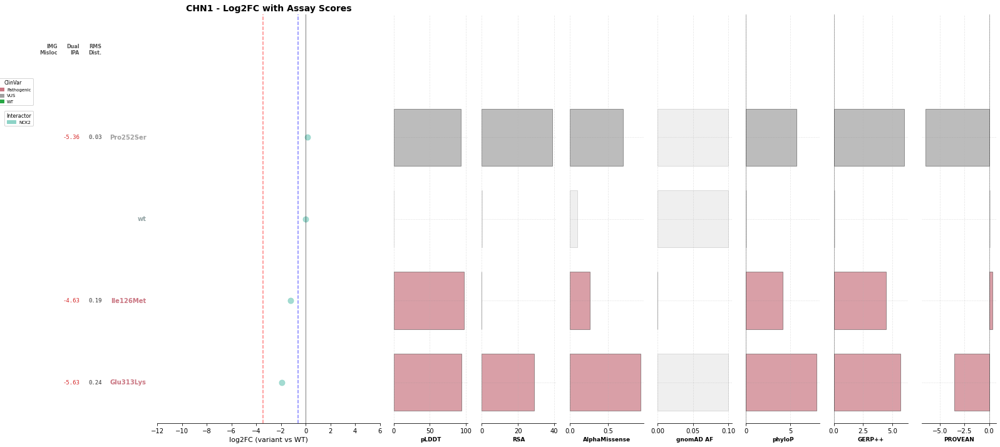

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/LDHB_log2fc_panel.pdf


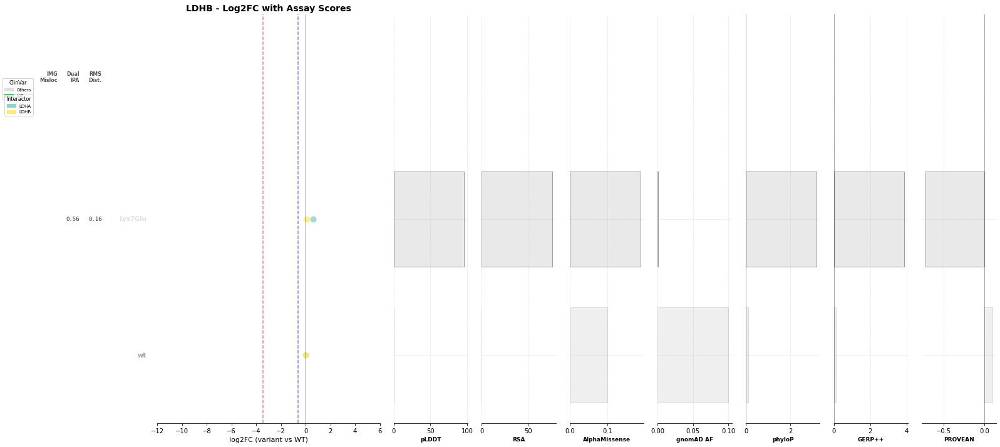

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/EZH2_log2fc_panel.pdf


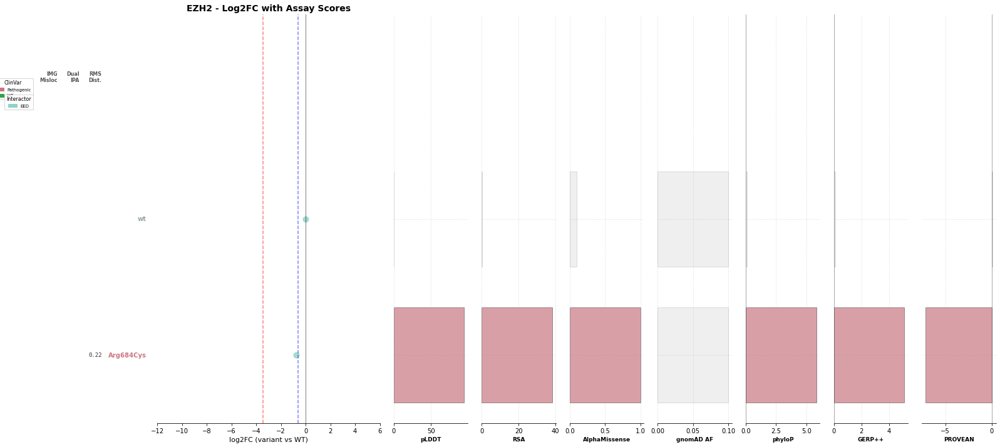

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PTS_log2fc_panel.pdf


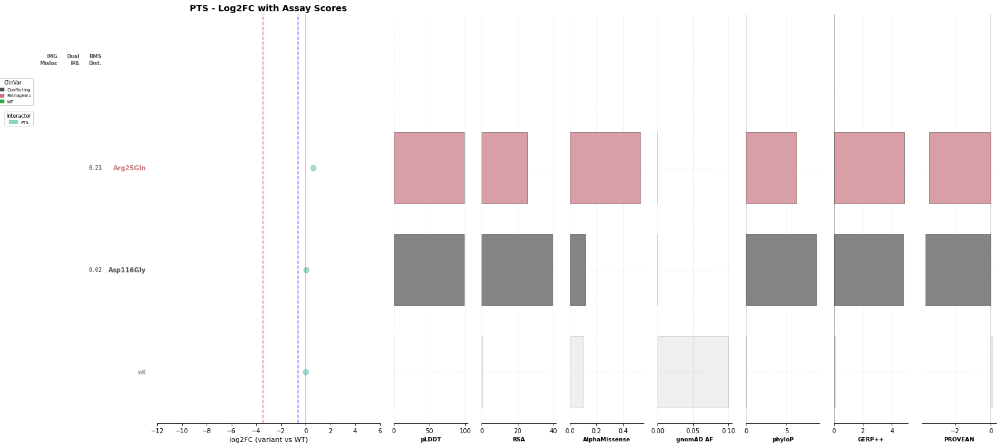

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/AP2S1_log2fc_panel.pdf


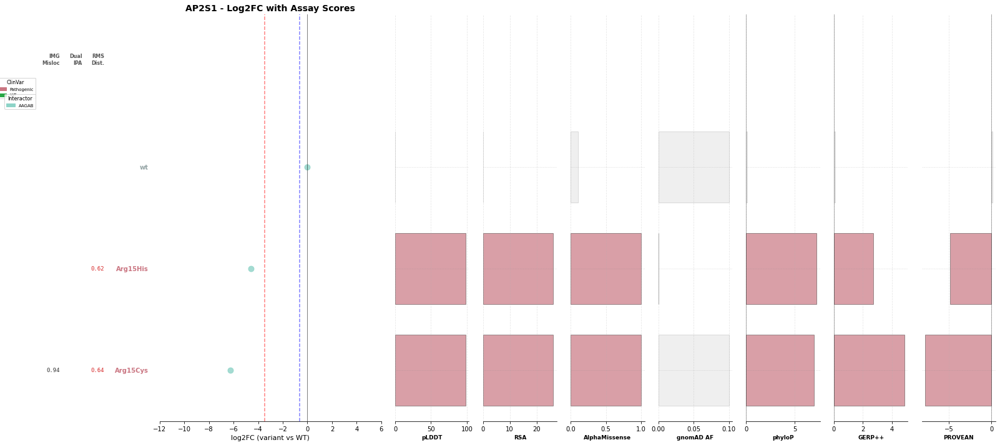

In [27]:
for symbol in edge_df['symbol'].unique():
    fig, axes = plot_log2fc_panel(
        edge_df=edge_df,
        db_symbol=symbol,
        orf_distances=orf_distances,
        all_assay_df=all_assay_df,
        palette_dict=palette_dict,
        save_path=f'{outputs_dir}/log2fc_barplots/{symbol}_log2fc_panel.pdf'
    )

# Swarm plots, only PPI

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3358366170.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 40.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/3358366170.py:201: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this war

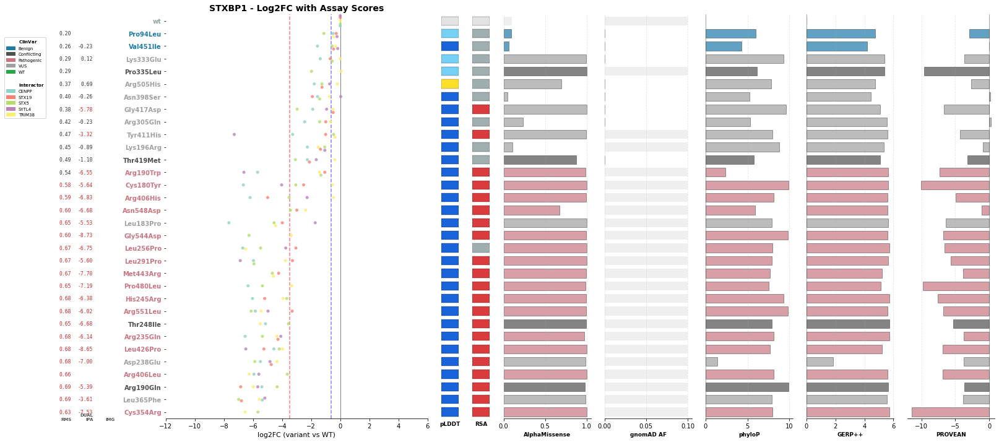

In [28]:
def plot_log2fc_panel_swarm(edge_df, db_symbol, orf_distances=None,
                            all_assay_df=None,
                            clnsig_column='clinvar_clnsig_clean',
                            palette_dict=None, row_height=1.0,
                            figsize=(24, 12), save_path=None,
                            annotation_cols=None, point_size=5):
    """
    Plot Log2FC panel with swarmplot, RMS distance, DualIPA, IMG misloc and annotation bar plots.
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
                          'gnomAD4.1_joint_AF', 'phyloP100way_vertebrate', 
                          'GERP++_RS', 'PROVEAN_score']
    
    annotation_cols = [col for col in annotation_cols if col in edge_df.columns]
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Set WT log2fc to 0
    gene_data.loc[gene_data['aa_change'] == 'WT', 'log2fc'] = 0
    
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    variant_annotations = gene_data.groupby('aa_change')[annotation_cols].first()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE & ASSAY DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    dualipa_map, dualipa_hit_map, img_misloc_map, img_misloc_hit_map = {}, {}, {}, {}
    if all_assay_df is not None:
        assay_gene = all_assay_df[all_assay_df['symbol'] == db_symbol].copy()
        if not assay_gene.empty:
            assay_gene['aa_change'] = assay_gene['aa_change'].fillna('WT')
            if 'dualipa_score' in assay_gene.columns:
                dualipa_map = assay_gene.set_index('aa_change')['dualipa_score'].to_dict()
            if 'dualipa_hit' in assay_gene.columns:
                dualipa_hit_map = assay_gene.set_index('aa_change')['dualipa_hit'].to_dict()
            if 'img_misloc_score' in assay_gene.columns:
                img_misloc_map = assay_gene.set_index('aa_change')['img_misloc_score'].to_dict()
            if 'img_misloc_hit' in assay_gene.columns:
                img_misloc_hit_map = assay_gene.set_index('aa_change')['img_misloc_hit'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=True)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=False).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()
    
    # Set categorical order for swarmplot
    gene_data['aa_change'] = pd.Categorical(gene_data['aa_change'], categories=variants_sorted, ordered=True)

    # --- FIGURE SETUP ---
    n_annotations = len(annotation_cols)
    n_interactors = len(all_interactors)
    base_width = figsize[0] + (3 if n_interactors > 15 else 0)
    
    # Create width ratios: main plot = 3, categorical cols (plddt, rsa) = 0.3, numeric = 1
    width_ratios = [3]
    for col in annotation_cols:
        if col in ['plddt_f32', 'rsa_f32']:
            width_ratios.append(0.2)  # Narrow for categorical
        else:
            width_ratios.append(1)    # Normal for numeric bars
    
    
    fig, axes = plt.subplots(1, 1 + n_annotations, figsize=(base_width, figsize[1]),
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.15})
    ax = axes[0]

    # --- SWARMPLOT ---
    sns.swarmplot(
        data=gene_data,
        x='log2fc',
        y='aa_change',
        hue='ad_symbol',
        palette=interactor_colors,
        size=point_size,
        alpha=0.8,
        ax=ax
    )
    ax.legend_.remove()  # Remove auto legend, we'll add custom ones

    # --- ADD SCORE TEXT & VARIANT COLORS ---
    
    rms_loc = -18.5
    dualipa_loc = rms_loc + 1.5
    img_loc = rms_loc + 3
    
    for i, variant in enumerate(variants_sorted):
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # Color y-tick labels
        ax.get_yticklabels()[i].set_color(variant_color)
        ax.get_yticklabels()[i].set_fontweight('bold')
        
        # IMG misloc score
        img_val = img_misloc_map.get(variant, np.nan)
        if pd.notna(img_val):
            try:
                img_color = '#d62728' if img_misloc_hit_map.get(variant, False) else '#333333'
                ax.text(img_loc, i, f"{float(img_val):.2f}", fontsize=8, ha='right', va='center',
                        fontfamily='monospace', color=img_color)
            except (ValueError, TypeError):
                pass
        
        # DualIPA score
        dualipa_val = dualipa_map.get(variant, np.nan)
        if pd.notna(dualipa_val):
            try:
                dualipa_color = '#d62728' if dualipa_hit_map.get(variant, False) else '#333333'
                ax.text(dualipa_loc, i, f"{float(dualipa_val):.2f}", fontsize=8, ha='right', va='center',
                        fontfamily='monospace', color=dualipa_color)
            except (ValueError, TypeError):
                pass
        
        # RMS distance
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if pd.notna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(rms_loc, i, f"{dist_val:.2f}", fontsize=8, ha='right', va='center',
                        fontfamily='monospace', color=dist_color)

    # Headers
    ax.text(rms_loc, len(variants_sorted) - 0.3, "RMS", fontsize=7, ha='right', va='bottom', fontweight='bold', color='#555555')
    ax.text(dualipa_loc, len(variants_sorted) - 0.3, "DUAL\nIPA", fontsize=7, ha='right', va='bottom', fontweight='bold', color='#555555')
    ax.text(img_loc, len(variants_sorted) - 0.3, "IMG", fontsize=7, ha='right', va='bottom', fontweight='bold', color='#555555')

    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5)
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_ylabel('')
    ax.set_xlim(-12, 6)
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(f"{db_symbol} - Log2FC with Assay Scores", fontsize=14, fontweight='bold')

    # --- ANNOTATION BAR PLOTS ---
    annotation_labels = {
        'plddt_f32': 'pLDDT', 'rsa_f32': 'RSA', 'AlphaMissense_score': 'AlphaMissense',
        'gnomAD4.1_joint_AF': 'gnomAD AF', 'phyloP100way_vertebrate': 'phyloP',
        'GERP++_RS': 'GERP++', 'PROVEAN_score': 'PROVEAN',
        'pLDDT_Category': 'pLDDT', 'RSA_Category': 'RSA',
    }
    
    # AlphaFold pLDDT color scheme
    plddt_colors = {
        '>90': '#0053D6',      # Very high - dark blue
        '70-90': '#65CBF3',    # Confident - light blue  
        '50-70': '#FFDB13',    # Low - yellow
        '$\\leqslant$50': '#FF7D45',  # Very low - orange
    }
    
    # RSA color scheme (buried = potentially deleterious, exposed = benign)
    rsa_colors = {
        '<10': '#d62728',      # Buried - red (deleterious)
        '10-90': '#95a5a6',    # Intermediate - gray (neutral)
        '$\\geqslant$90': '#28a745',  # Exposed - green (benign)
    }
    
    
    # Get category columns from edge_df
    variant_plddt_cat = gene_data.groupby('aa_change')['pLDDT_Category'].first()
    variant_rsa_cat = gene_data.groupby('aa_change')['RSA_Category'].first()
    
    
    
    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 1]
        
        # Check if this is a categorical column (pLDDT or RSA)
        if col == 'plddt_f32' and 'pLDDT_Category' in gene_data.columns:
            # Use categorical pLDDT
            y_positions = np.arange(len(variants_sorted))
            
            for i, variant in enumerate(variants_sorted):
                cat = variant_plddt_cat.get(variant, np.nan)
                if pd.notna(cat):
                    color = plddt_colors.get(cat, '#E0E0E0')
                else:
                    color = '#E0E0E0'
                ax_bar.barh(i, 1, height=0.7, color=color, alpha=0.9, edgecolor='black', linewidth=0.3)
            
            ax_bar.set_xlim(0, 1)
            ax_bar.set_xticks([])
            ax_bar.set_ylim(-0.5, len(variants_sorted) - 0.5)
            ax_bar.invert_yaxis()
            ax_bar.set_yticks([])
            ax_bar.spines['left'].set_visible(False)
            ax_bar.spines['top'].set_visible(False)
            ax_bar.spines['right'].set_visible(False)
            ax_bar.spines['bottom'].set_visible(False)
            ax_bar.set_xlabel('pLDDT', fontsize=9, fontweight='bold')
            
        elif col == 'rsa_f32' and 'RSA_Category' in gene_data.columns:
            # Use categorical RSA
            y_positions = np.arange(len(variants_sorted))
            
            for i, variant in enumerate(variants_sorted):
                cat = variant_rsa_cat.get(variant, np.nan)
                if pd.notna(cat):
                    color = rsa_colors.get(cat, '#E0E0E0')
                else:
                    color = '#E0E0E0'
                ax_bar.barh(i, 1, height=0.7, color=color, alpha=0.9, edgecolor='black', linewidth=0.3)
            
            ax_bar.set_xlim(0, 1)
            ax_bar.set_xticks([])
            ax_bar.set_ylim(-0.5, len(variants_sorted) - 0.5)
            ax_bar.invert_yaxis()
            ax_bar.set_yticks([])
            ax_bar.spines['left'].set_visible(False)
            ax_bar.spines['top'].set_visible(False)
            ax_bar.spines['right'].set_visible(False)
            ax_bar.spines['bottom'].set_visible(False)
            ax_bar.set_xlabel('RSA', fontsize=9, fontweight='bold')
            
        else:
            # Original numeric bar plot logic
            values, bar_colors = [], []
            
            for variant in variants_sorted:
                if variant in variant_annotations.index:
                    val = variant_annotations.loc[variant, col]
                    try:
                        values.append(float(val) if pd.notna(val) else np.nan)
                    except (ValueError, TypeError):
                        values.append(np.nan)
                else:
                    values.append(np.nan)
                
                if variant == 'WT':
                    bar_colors.append('#28a745')
                else:
                    clnsig = variant_to_clnsig.get(variant, 'Unknown')
                    bar_colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
            
            values = np.array(values, dtype=float)
            y_positions = np.arange(len(variants_sorted))
            
            ax_bar.barh(y_positions, values, height=0.7, color=bar_colors, alpha=0.7, edgecolor='black', linewidth=0.5)
            
            for i, val in enumerate(values):
                if np.isnan(val):
                    ax_bar.barh(y_positions[i], 0.1, height=0.7, color='#E0E0E0', alpha=0.5)
            
            ax_bar.set_ylim(-0.5, len(variants_sorted) - 0.5)
            ax_bar.invert_yaxis() 
            ax_bar.set_yticks([])
            ax_bar.spines['left'].set_visible(False)
            ax_bar.spines['top'].set_visible(False)
            ax_bar.spines['right'].set_visible(False)
            ax_bar.set_xlabel(annotation_labels.get(col, col), fontsize=9, fontweight='bold')
            ax_bar.grid(axis='x', linestyle='--', alpha=0.3)
            
            if col in ['PROVEAN_score', 'GERP++_RS', 'phyloP100way_vertebrate']:
                ax_bar.axvline(x=0, color='black', linestyle='-', alpha=0.3, linewidth=1)

    # --- COMBINED LEGEND ---
    legend_x = -0.45
    legend_handles = []
    legend_labels = []
    
    # Add ClinVar section
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        # Add section title as empty patch
        legend_handles.append(Patch(facecolor='none', edgecolor='none', label=''))
        legend_labels.append(r'$\bf{ClinVar}$')
        
        for cat in sorted(clinvar_categories_used):
            legend_handles.append(Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black")))
            legend_labels.append(cat)
        
        legend_handles.append(Patch(color='#28a745'))
        legend_labels.append('WT')
        
        # Add spacer
        legend_handles.append(Patch(facecolor='none', edgecolor='none'))
        legend_labels.append('')
    
    # Add Interactor section
    legend_handles.append(Patch(facecolor='none', edgecolor='none'))
    legend_labels.append(r'$\bf{Interactor}$')
    
    for i in sorted(interactors):
        legend_handles.append(Patch(color=interactor_colors[i]))
        legend_labels.append(i)
    
    # Create single combined legend
    ax.legend(handles=legend_handles, labels=legend_labels,
              bbox_to_anchor=(legend_x, 0.95), loc='upper right',
              fontsize=7, frameon=True, fancybox=True,
              ncol=2 if n_interactors > 15 else 1)

    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes


# Single gene plot with all annotations
fig, axes = plot_log2fc_panel_swarm(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    all_assay_df=all_assay_df,
    palette_dict=palette_dict
)

# Swarm plot all variants

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

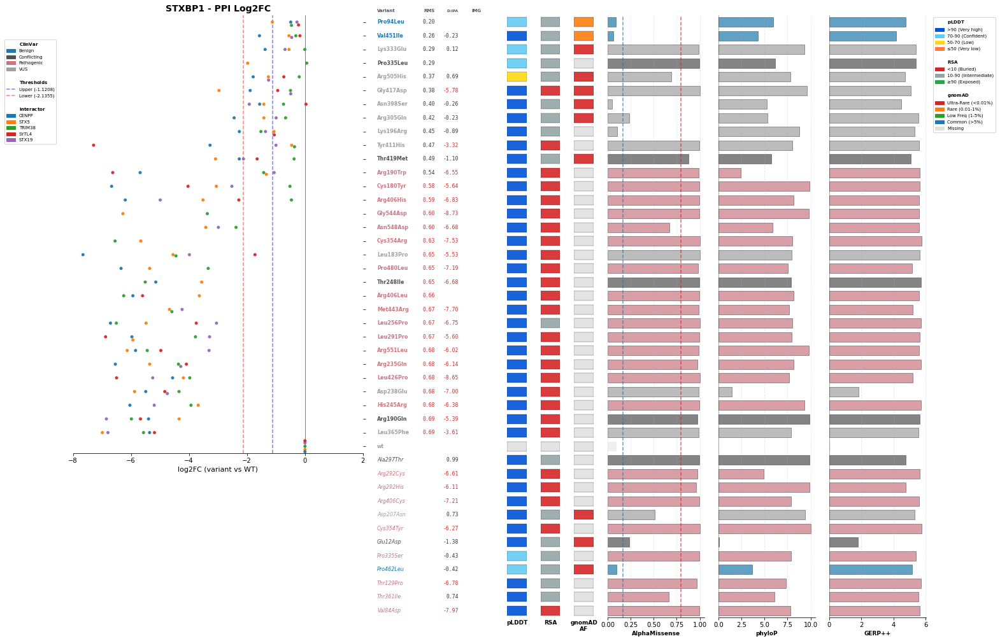

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


def plot_log2fc_panel_swarm(edge_df, db_symbol, orf_distances=None,
                            all_assay_df=None,
                            clnsig_column='clinvar_clnsig_clean',
                            palette_dict=None, row_height=1.0,
                            figsize=(24, 12), save_path=None,
                            annotation_cols=None, point_size=5,
                            top_n_interactors=15,
                            LLR_upper=-1.1208, LLR_lower=-2.1355):
    """
    Plot Log2FC panel with swarmplot, RMS distance, DualIPA, IMG misloc and annotation bar plots.
    PPI variants are ordered by RMS distance (descending).
    Crops the PPI panel to end at 'WT'.
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF',
                           'am_pathogenicity', 'phyloP100way_vertebrate', 
                          'GERP++_RS']# , 'PROVEAN_score']
    
    # Filter annotation columns based on availability
    available_cols = []
    if all_assay_df is not None:
        available_cols.extend([c for c in annotation_cols if c in all_assay_df.columns])
    if len(edge_df) > 0:
        available_cols.extend([c for c in annotation_cols if c in edge_df.columns])
    annotation_cols = sorted(list(set(available_cols)), key=lambda x: annotation_cols.index(x) if x in annotation_cols else 999)
    print(f"Using annotation columns: {annotation_cols}")
    
    # --- PREPARE DISTANCE MAP (Moved up for sorting) ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    
    # Get all variants for this gene from all_assay_df
    all_variants_data = None
    variants_without_ppi = []
    
    if all_assay_df is not None:
        all_variants_data = all_assay_df[all_assay_df['symbol'] == db_symbol].copy()
        if not all_variants_data.empty:
            all_variants_data['aa_change'] = all_variants_data['aa_change'].fillna('WT')
            
            # Find variants in all_assay_df but not in edge_df (PPI data)
            ppi_variants = set(gene_data['aa_change'].fillna('WT').unique()) if len(gene_data) > 0 else set()
            all_gene_variants = set(all_variants_data['aa_change'].unique())
            variants_without_ppi = list(all_gene_variants - ppi_variants)
    
    if len(gene_data) == 0 and len(variants_without_ppi) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    # Process PPI data if available
    if len(gene_data) > 0:
        gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
        gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
            subset=['aa_change', 'ad_symbol'], keep='first'
        )
        gene_data.loc[gene_data['aa_change'] == 'WT', 'log2fc'] = 0
        
        pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
        variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
        
        # Get annotations from PPI data
        avail_annot_cols = [col for col in annotation_cols if col in gene_data.columns]
        variant_annotations = gene_data.groupby('aa_change')[avail_annot_cols].first() if avail_annot_cols else pd.DataFrame()
        
        # all_interactors = sorted(pivot_raw.columns.tolist())
        # cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
        
        # 1. Calculate "Impact" (Total Absolute Log2FC per interactor)
        interactor_impact = gene_data.groupby('ad_symbol')['log2fc'].apply(lambda x: x.abs().sum())
        
        # 2. Identify Top N
        top_interactors = interactor_impact.sort_values(ascending=False).head(top_n_interactors).index.tolist()
        
        # 3. Create a plotting label column
        gene_data['plot_interactor'] = gene_data['ad_symbol'].apply(
            lambda x: x if x in top_interactors else 'Other'
        )
        
        # 4. Define Palette (Top N get colors, Other gets Gray)
        unique_plot_labels = [x for x in top_interactors] # Keep order
        
        # Generate colors for top N
        base_palette = sns.color_palette("tab10" if len(top_interactors) <= 10 else "tab20", n_colors=len(top_interactors))
        interactor_colors = dict(zip(top_interactors, base_palette))
        
        # Add gray for 'Other' if it exists
        if 'Other' in gene_data['plot_interactor'].values:
            unique_plot_labels.append('Other')
            interactor_colors['Other'] = '#CCCCCC' # Light Gray
            
        # colors_list = cmap(np.linspace(0, 1, len(all_interactors)))

        # interactor_colors = dict(zip(all_interactors, colors_list))
        
        # --- SORT PPI VARIANTS BY RMS DISTANCE ---
        # Get list of variants excluding WT
        raw_variants = [v for v in pivot_raw.index if v != 'WT']
        
        # Sort key: (is_nan, -rms_value)
        # This puts valid RMS values first (descending), followed by NaNs
        ppi_variants_sorted = sorted(
            raw_variants,
            key=lambda v: (
                dist_map.get(v, np.nan) is np.nan or np.isnan(dist_map.get(v, np.nan)), 
                dist_map.get(v, 0) if pd.notna(dist_map.get(v, np.nan)) else 0
            )
        )
        
        # Append WT at the end if it exists in the data
        # if 'WT' in pivot_raw.index:
            # ppi_variants_sorted.append('WT')
            
        interactors = pivot_raw.columns.tolist()
    else:
        ppi_variants_sorted = []
        interactors = []
        interactor_colors = {}
        variant_to_clnsig = {}
        variant_annotations = pd.DataFrame()
    
    # Get annotations and clnsig for non-PPI variants from all_assay_df
    if all_variants_data is not None and len(variants_without_ppi) > 0:
        non_ppi_data = all_variants_data[all_variants_data['aa_change'].isin(variants_without_ppi)]
        
        for _, row in non_ppi_data.iterrows():
            variant = row['aa_change']
            if clnsig_column in row and variant not in variant_to_clnsig:
                variant_to_clnsig[variant] = row[clnsig_column]
        
        avail_annot_cols = [col for col in annotation_cols if col in all_variants_data.columns]
        if avail_annot_cols:
            non_ppi_annotations = non_ppi_data.groupby('aa_change')[avail_annot_cols].first()
            variant_annotations = pd.concat([variant_annotations, non_ppi_annotations])
    
    # Sort non-PPI variants alphabetically and combine
    variants_without_ppi_sorted = sorted(variants_without_ppi)
    variants_sorted = ppi_variants_sorted + variants_without_ppi_sorted
    
    # Track which variants have PPI data
    ppi_variant_set = set(ppi_variants_sorted)
    
    # Set categorical order for swarmplot
    if len(gene_data) > 0:
        gene_data['aa_change'] = pd.Categorical(gene_data['aa_change'], categories=variants_sorted, ordered=True)

    # --- ASSAY DATA SETUP ---
    dualipa_map, dualipa_hit_map, img_misloc_map, img_misloc_hit_map = {}, {}, {}, {}
    if all_assay_df is not None:
        assay_gene = all_assay_df[all_assay_df['symbol'] == db_symbol].copy()
        if not assay_gene.empty:
            assay_gene['aa_change'] = assay_gene['aa_change'].fillna('WT')
            if 'dualipa_score' in assay_gene.columns:
                dualipa_map = assay_gene.set_index('aa_change')['dualipa_score'].to_dict()
            if 'dualipa_hit' in assay_gene.columns:
                dualipa_hit_map = assay_gene.set_index('aa_change')['dualipa_hit'].to_dict()
            if 'img_misloc_score' in assay_gene.columns:
                img_misloc_map = assay_gene.set_index('aa_change')['img_misloc_score'].to_dict()
            if 'img_misloc_hit' in assay_gene.columns:
                img_misloc_hit_map = assay_gene.set_index('aa_change')['img_misloc_hit'].to_dict()
    # --- FIGURE SETUP ---
    n_annotations = len(annotation_cols)
    n_interactors = len(interactor_colors)
    base_width = figsize[0] + (3 if n_interactors > 15 else 0)
    
    # Dynamic height based on number of variants
    n_variants = len(variants_sorted)
    row_height_px = 0.35  # Height per variant row in inches
    min_height = 3        # Minimum figure height
    max_height = 40       # Maximum figure height
    dynamic_height = max(min_height, min(max_height, n_variants * row_height_px + 2))
    
    width_ratios = [3, 1.2]
    for col in annotation_cols:
        if col in ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF']:
            width_ratios.append(0.2)
        else:
            width_ratios.append(1)
    
    fig, axes = plt.subplots(1, 2 + n_annotations, figsize=(base_width, dynamic_height),
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.15})
    ax = axes[0]
    ax_scores = axes[1]
    
    # --- SWARMPLOT ---
    if len(gene_data) > 0:
        # Sort so 'Other' plots first (z-order: behind important points)
        gene_data['is_other'] = gene_data['plot_interactor'] == 'Other'
        gene_data = gene_data.sort_values('is_other', ascending=False)
        
        sns.swarmplot(
            data=gene_data,
            x='log2fc',
            y='aa_change',
            hue='plot_interactor', # <--- CHANGED from 'ad_symbol'
            palette=interactor_colors,
            size=point_size,
            alpha=0.95,
            hue_order=unique_plot_labels, # <--- ADDED to ensure consistent color mapping
            ax=ax
        )
        if ax.legend_ is not None:
            ax.legend_.remove()

    # --- Y-AXIS & TITLES ---
    ax.set_yticklabels([])
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position('right')
    
    ax_scores.set_xlim(0, 1)
    ax_scores.set_ylim(-0.5, len(variants_sorted) - 0.5)
    ax_scores.invert_yaxis()
    ax_scores.set_yticks([])
    ax_scores.set_xticks([])
    ax_scores.spines['left'].set_visible(False)
    ax_scores.spines['right'].set_visible(False)
    ax_scores.spines['top'].set_visible(False)
    ax_scores.spines['bottom'].set_visible(False)

    ax_scores.text(0.0, -0.7, "Variant", fontsize=7, ha='left', va='bottom', fontweight='bold', color='#555555')
    ax_scores.text(0.50, -0.7, "RMS", fontsize=7, ha='right', va='bottom', fontweight='bold', color='#555555')
    ax_scores.text(0.70, -0.7, "D-IPA", fontsize=6, ha='right', va='bottom', fontweight='bold', color='#555555')
    ax_scores.text(0.90, -0.7, "IMG", fontsize=7, ha='right', va='bottom', fontweight='bold', color='#555555')

    # --- ADD VARIANT NAMES & SCORES ---
    for i, variant in enumerate(variants_sorted):
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        font_style = 'italic' if variant not in ppi_variant_set else 'normal'
        font_weight = 'normal' if variant not in ppi_variant_set else 'bold'
        ax_scores.text(0.0, i, variant, fontsize=8, ha='left', va='center',
                      color=variant_color, fontweight=font_weight, fontstyle=font_style)
        
        # RMS distance
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if pd.notna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax_scores.text(0.50, i, f"{dist_val:.2f}", fontsize=8, ha='right', va='center',
                              fontfamily='monospace', color=dist_color)
        
        # DualIPA score
        dualipa_val = dualipa_map.get(variant, np.nan)
        if pd.notna(dualipa_val):
            try:
                dualipa_color = '#d62728' if dualipa_hit_map.get(variant, False) else '#333333'
                ax_scores.text(0.70, i, f"{float(dualipa_val):.2f}", fontsize=8, ha='right', va='center',
                              fontfamily='monospace', color=dualipa_color)
            except (ValueError, TypeError):
                pass
        
        # IMG misloc score
        img_val = img_misloc_map.get(variant, np.nan)
        if pd.notna(img_val):
            try:
                img_color = '#d62728' if img_misloc_hit_map.get(variant, False) else '#333333'
                ax_scores.text(0.90, i, f"{float(img_val):.2f}", fontsize=8, ha='right', va='center',
                              fontfamily='monospace', color=img_color)
            except (ValueError, TypeError):
                pass

    # if len(ppi_variants_sorted) > 0 and len(variants_without_ppi_sorted) > 0:
        # separator_y = len(ppi_variants_sorted) - 0.5
        # ax_scores.axhline(y=separator_y, color='#666666', linestyle='-', linewidth=2, alpha=0.7)

    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=LLR_upper, color='blue', linestyle='--', alpha=0.5, linewidth=1.5)
    ax.axvline(x=LLR_lower, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_ylabel('')
    ax.set_xlim(-8, 2)
    ax.set_ylim(-0.5, len(variants_sorted) - 0.5)
    ax.invert_yaxis()
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(f"{db_symbol} - PPI Log2FC", fontsize=14, fontweight='bold')

    # --- ANNOTATION BAR PLOTS ---
    annotation_labels = {
        'plddt_f32': 'pLDDT', 'rsa_f32': 'RSA', 'gnomAD4.1_joint_AF': 'gnomAD\nAF',
        'am_pathogenicity': 'AlphaMissense', 'phyloP100way_vertebrate': 'phyloP',
        'GERP++_RS': 'GERP++', 'PROVEAN_score': 'PROVEAN',
    }
    
    plddt_colors = {'>90': '#0053D6', '70-90': '#65CBF3', '50-70': '#FFDB13', '$\\leqslant$50': '#FF7D45'}
    rsa_colors = {'<10': '#d62728', '10-90': '#95a5a6', '$\\geqslant$90': '#28a745'}
    gnomad_colors = {
        'Ultra-Rare (<0.01%)': '#d62728',  # Red - rare/potentially pathogenic
        'Rare (0.01-1%)': '#ff7f0e',        # Orange
        'Low Freq (1-5%)': '#2ca02c',       # Green
        'Common (>5%)': '#1f77b4',          # Blue - common/likely benign
        'Missing': '#E0E0E0',               # Gray
    }
    
    
    variant_plddt_cat = {}
    variant_rsa_cat = {}
    variant_gnomad_cat = {}
    if len(gene_data) > 0 and 'pLDDT_Category' in gene_data.columns:
        variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
    if len(gene_data) > 0 and 'RSA_Category' in gene_data.columns:
        variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
    if len(gene_data) > 0 and 'gnomAD_Class' in gene_data.columns:
        variant_gnomad_cat.update(gene_data.groupby('aa_change')['gnomAD_Class'].first().to_dict())
    if all_variants_data is not None:
        if 'pLDDT_Category' in all_variants_data.columns:
            for v in variants_without_ppi:
                cat_data = all_variants_data[all_variants_data['aa_change'] == v]['pLDDT_Category']
                if len(cat_data) > 0: variant_plddt_cat[v] = cat_data.iloc[0]
        if 'RSA_Category' in all_variants_data.columns:
            for v in variants_without_ppi:
                cat_data = all_variants_data[all_variants_data['aa_change'] == v]['RSA_Category']
                if len(cat_data) > 0: variant_rsa_cat[v] = cat_data.iloc[0]
        if 'gnomAD_Class' in all_variants_data.columns:
            for v in variants_without_ppi:
                cat_data = all_variants_data[all_variants_data['aa_change'] == v]['gnomAD_Class']
                if len(cat_data) > 0: variant_gnomad_cat[v] = cat_data.iloc[0]
    
    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 2]
        
        if col == 'plddt_f32':
            for i, variant in enumerate(variants_sorted):
                cat = variant_plddt_cat.get(variant, np.nan)
                color = plddt_colors.get(cat, '#E0E0E0') if pd.notna(cat) else '#E0E0E0'
                ax_bar.barh(i, 1, height=0.7, color=color, alpha=0.9, edgecolor='black', linewidth=0.3)
            ax_bar.set_xlim(0, 1)
            ax_bar.set_xticks([])
        elif col == 'rsa_f32':
            for i, variant in enumerate(variants_sorted):
                cat = variant_rsa_cat.get(variant, np.nan)
                color = rsa_colors.get(cat, '#E0E0E0') if pd.notna(cat) else '#E0E0E0'
                ax_bar.barh(i, 1, height=0.7, color=color, alpha=0.9, edgecolor='black', linewidth=0.3)
            ax_bar.set_xlim(0, 1)
            ax_bar.set_xticks([])
        elif col == 'gnomAD4.1_joint_AF':
            for i, variant in enumerate(variants_sorted):
                cat = variant_gnomad_cat.get(variant, 'Missing')
                color = gnomad_colors.get(cat, '#E0E0E0') if pd.notna(cat) else '#E0E0E0'
                ax_bar.barh(i, 1, height=0.7, color=color, alpha=0.9, edgecolor='black', linewidth=0.3)
            ax_bar.set_xlim(0, 1)
            ax_bar.set_xticks([])

        else:
            values, bar_colors = [], []
            for variant in variants_sorted:
                val = np.nan
                if variant in variant_annotations.index and col in variant_annotations.columns:
                    val = variant_annotations.loc[variant, col]
                elif all_variants_data is not None and col in all_variants_data.columns:
                    v_data = all_variants_data[all_variants_data['aa_change'] == variant]
                    if len(v_data) > 0: val = v_data[col].iloc[0]
                
                try:
                    clean_val = float(val)
                    values.append(clean_val)
                except (ValueError, TypeError):
                    values.append(np.nan)

                if variant == 'WT': bar_colors.append('#28a745')
                else:
                    clnsig = variant_to_clnsig.get(variant, 'Unknown')
                    bar_colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
            
            values = np.array(values, dtype=float)
            y_positions = np.arange(len(variants_sorted))
            ax_bar.barh(y_positions, values, height=0.7, color=bar_colors, alpha=0.7, edgecolor='black', linewidth=0.5)
            for i, val in enumerate(values):
                if np.isnan(val): ax_bar.barh(y_positions[i], 0.1, height=0.7, color='#E0E0E0', alpha=0.5)
            
            ax_bar.set_xlabel(annotation_labels.get(col, col), fontsize=9, fontweight='bold')
            ax_bar.grid(axis='x', linestyle='--', alpha=0.3)
            
            # Add thresholds for specific columns
            if col in ['GERP++_RS', 'phyloP100way_vertebrate']:
                ax_bar.axvline(x=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
            
            # AlphaMissense thresholds (Supporting level)
            if col == 'am_pathogenicity':
                ax_bar.axvline(x=0.792, color='#d62728', linestyle='--', alpha=0.7, linewidth=1.5, label='Pathogenic (≥0.792)')
                # ax_bar.axvline(x=0.169, color='#2ca02c', linestyle='--', alpha=0.7, linewidth=1.5, label='Benign (≤0.169)')
                ax_bar.axvline(x=0.169, color=palette_dict['clinvar_clnsig_clean']['Benign'], linestyle='--', alpha=0.7, linewidth=1.5, label='Benign (≤0.169)')

        ax_bar.set_ylim(-0.5, len(variants_sorted) - 0.5)
        ax_bar.invert_yaxis()
        ax_bar.set_yticks([])
        ax_bar.spines['left'].set_visible(False)
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        if col not in ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF']:
            ax_bar.spines['bottom'].set_visible(True)
        else:
            ax_bar.spines['bottom'].set_visible(False)
            ax_bar.set_xlabel(annotation_labels.get(col, col), fontsize=9, fontweight='bold')
            
            
        # if len(ppi_variants_sorted) > 0 and len(variants_without_ppi_sorted) > 0:
            # separator_y = len(ppi_variants_sorted) - 0.5
            # ax_bar.axhline(y=separator_y, color='#666666', linestyle='-', linewidth=2, alpha=0.7)

    # --- pLDDT and RSA LEGEND (right side, combined) ---
    ax_last = axes[-1]
    
    # Combined legend with both pLDDT and RSA
    combined_handles = []
    combined_labels = []
    
    # pLDDT section
    combined_handles.append(Patch(facecolor='none', edgecolor='none'))
    combined_labels.append(r'$\bf{pLDDT}$')
    combined_handles.append(Patch(color='#0053D6'))
    combined_labels.append('>90 (Very high)')
    combined_handles.append(Patch(color='#65CBF3'))
    combined_labels.append('70-90 (Confident)')
    combined_handles.append(Patch(color='#FFDB13'))
    combined_labels.append('50-70 (Low)')
    combined_handles.append(Patch(color='#FF7D45'))
    combined_labels.append('≤50 (Very low)')
    
    # Spacer
    combined_handles.append(Patch(facecolor='none', edgecolor='none'))
    combined_labels.append('')
    
    # RSA section
    combined_handles.append(Patch(facecolor='none', edgecolor='none'))
    combined_labels.append(r'$\bf{RSA}$')
    combined_handles.append(Patch(color='#d62728'))
    combined_labels.append('<10 (Buried)')
    combined_handles.append(Patch(color='#95a5a6'))
    combined_labels.append('10-90 (Intermediate)')
    combined_handles.append(Patch(color='#28a745'))
    combined_labels.append('≥90 (Exposed)')
    
    # Spacer
    combined_handles.append(Patch(facecolor='none', edgecolor='none'))
    combined_labels.append('')
    
    # gnomAD section
    combined_handles.append(Patch(facecolor='none', edgecolor='none'))
    combined_labels.append(r'$\bf{gnomAD}$')
    combined_handles.append(Patch(color='#d62728'))
    combined_labels.append('Ultra-Rare (<0.01%)')
    combined_handles.append(Patch(color='#ff7f0e'))
    combined_labels.append('Rare (0.01-1%)')
    combined_handles.append(Patch(color='#2ca02c'))
    combined_labels.append('Low Freq (1-5%)')
    combined_handles.append(Patch(color='#1f77b4'))
    combined_labels.append('Common (>5%)')
    combined_handles.append(Patch(color='#E0E0E0'))
    combined_labels.append('Missing')
    
    ax_last.legend(handles=combined_handles, labels=combined_labels,
                   bbox_to_anchor=(1.05, 1.0), loc='upper left',
                   fontsize=7, title_fontsize=8, frameon=True, fancybox=True)


    # --- LEGEND ---
    legend_x = -0.05
    legend_handles = []
    legend_labels = []
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        legend_handles.append(Patch(facecolor='none', edgecolor='none', label=''))
        legend_labels.append(r'$\bf{ClinVar}$')
        for cat in sorted(clinvar_categories_used):
            legend_handles.append(Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black")))
            legend_labels.append(cat)
        # legend_handles.append(Patch(color='#28a745'))
        # legend_labels.append('WT')
        legend_handles.append(Patch(facecolor='none', edgecolor='none'))
        legend_labels.append('')
    
    legend_handles.append(Patch(facecolor='none', edgecolor='none'))
    legend_labels.append(r'$\bf{Thresholds}$')
    
    legend_handles.append(Line2D([0], [0], color='blue', linestyle='--', linewidth=1.5, alpha=0.5))
    legend_labels.append(f'Upper ({LLR_upper})')
    
    legend_handles.append(Line2D([0], [0], color='red', linestyle='--', linewidth=1.5, alpha=0.5))
    legend_labels.append(f'Lower ({LLR_lower})')
    
    legend_handles.append(Patch(facecolor='none', edgecolor='none'))
    legend_labels.append('')
    
    if interactor_colors:
        legend_handles.append(Patch(facecolor='none', edgecolor='none'))
        legend_labels.append(r'$\bf{Interactor}$')
        
        # Iterate over unique_plot_labels (Top N + Other) instead of all interactors
        for label in unique_plot_labels: 
            legend_handles.append(Patch(color=interactor_colors[label]))
            legend_labels.append(label)
    
    ax.legend(handles=legend_handles, labels=legend_labels,
              bbox_to_anchor=(legend_x, 0.95), loc='upper right',
              fontsize=7, frameon=True, fancybox=True,
              ncol=2 if n_interactors > 15 else 1)

    plt.tight_layout()
    
    # === RESIZING LOGIC ===
    if len(ppi_variants_sorted) > 0 and len(ppi_variants_sorted) < len(variants_sorted):
        n_ppi = len(ppi_variants_sorted)
        n_total = len(variants_sorted)
        
        pos_main = ax.get_position()
        pos_ref = ax_scores.get_position()
        
        new_height = (pos_ref.height / n_total) * n_ppi
        top_y = pos_ref.y0 + pos_ref.height
        new_y0 = top_y - new_height
        
        ax.set_position([pos_main.x0, new_y0, pos_main.width, new_height])
        ax.set_ylim(-0.5, n_ppi - 0.5)
        ax.invert_yaxis()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes


# Single gene plot with all annotations
fig, axes = plot_log2fc_panel_swarm(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    all_assay_df=all_assay_df,
    palette_dict=palette_dict
)

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

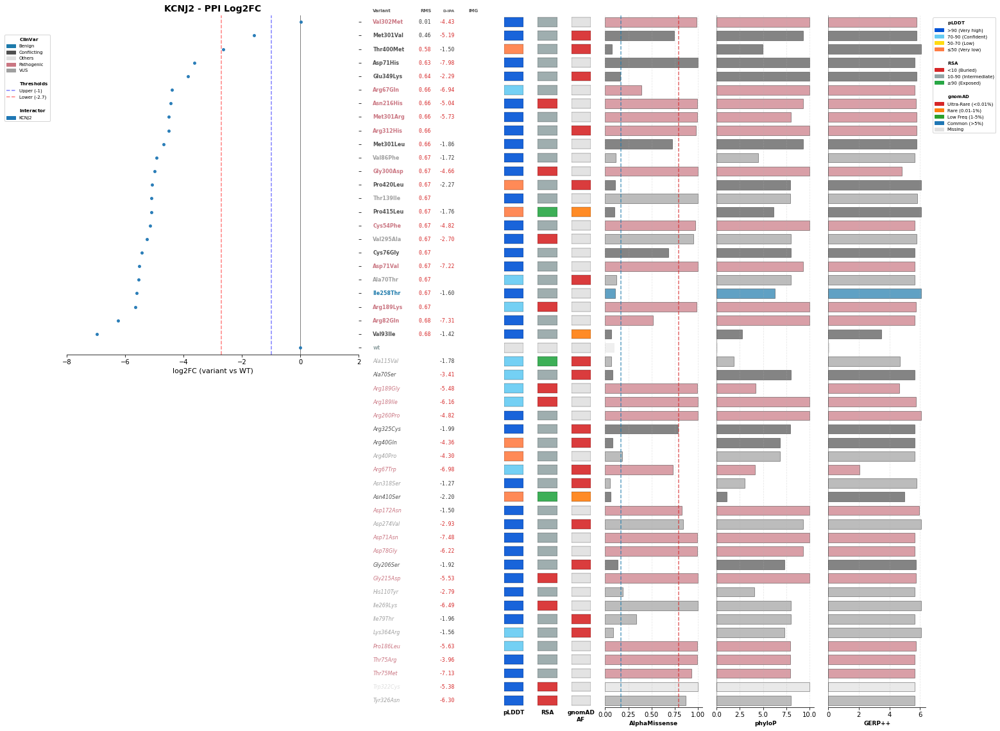

In [30]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel_swarm(
    edge_df=edge_df,
    db_symbol='KCNJ2',
    orf_distances=orf_distances,
    all_assay_df=all_assay_df,
    palette_dict=palette_dict,
    LLR_lower=-2.7,
    LLR_upper=-1
)

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 58.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.

Saved: ../3_outputs/sqY2H/log2fc_barplots/MLH1_log2fc_panel_swarm.pdf


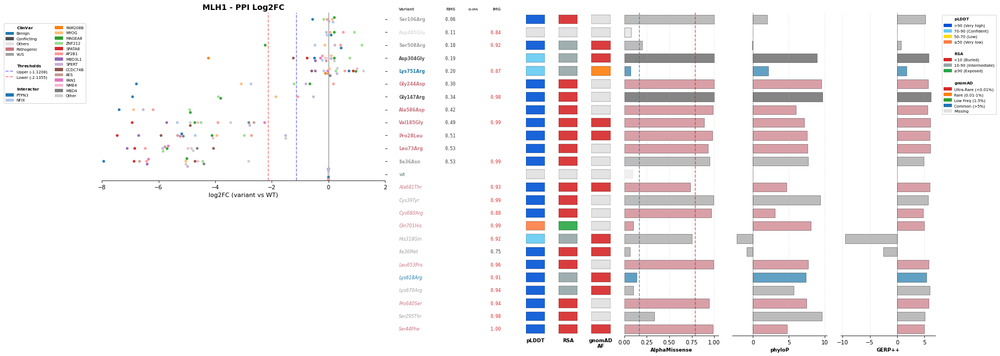

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 13.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 80.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed

Saved: ../3_outputs/sqY2H/log2fc_barplots/LITAF_log2fc_panel_swarm.pdf


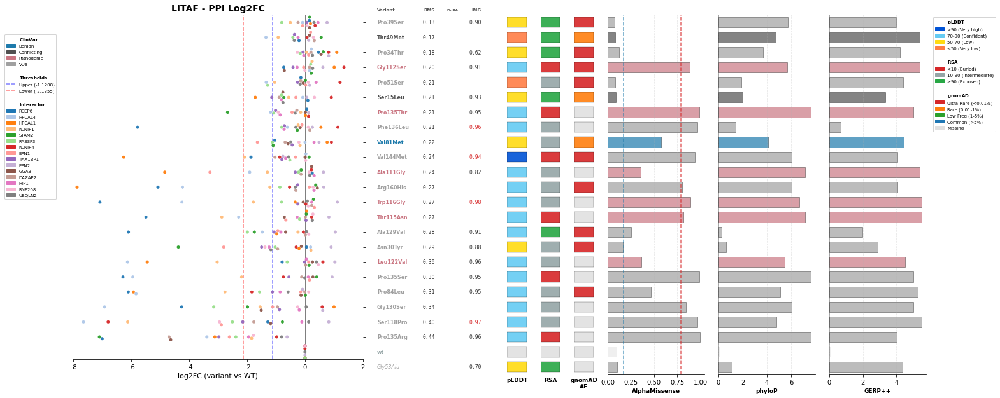

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 36.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.

Saved: ../3_outputs/sqY2H/log2fc_barplots/EMD_log2fc_panel_swarm.pdf


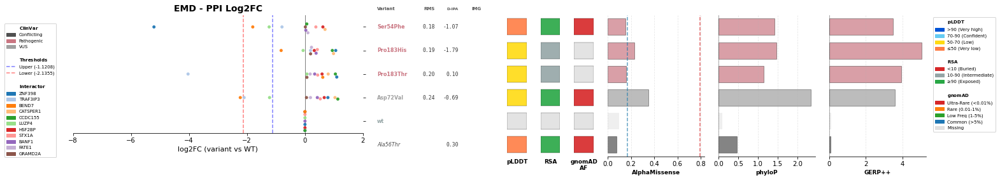

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/GFAP_log2fc_panel_swarm.pdf


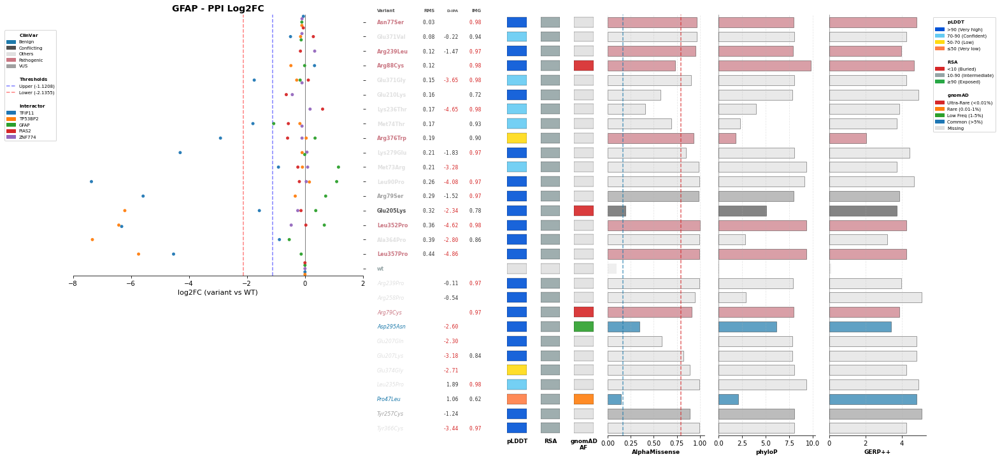

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT6A_log2fc_panel_swarm.pdf


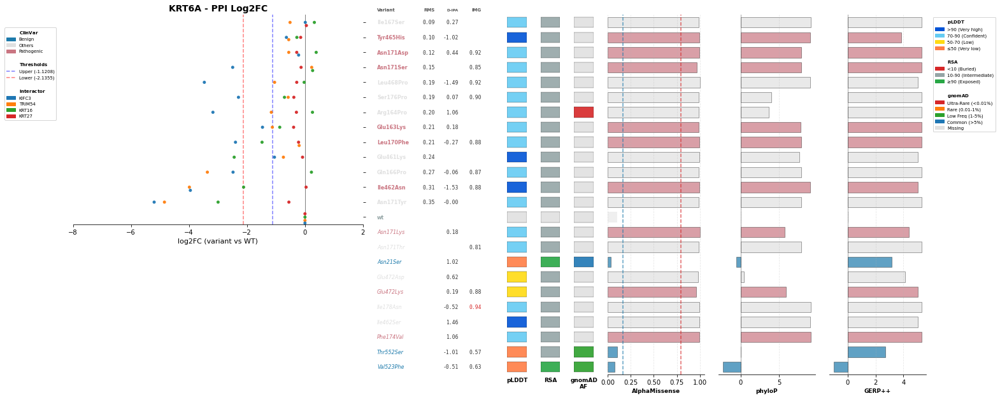

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 68.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.

Saved: ../3_outputs/sqY2H/log2fc_barplots/PLP1_log2fc_panel_swarm.pdf


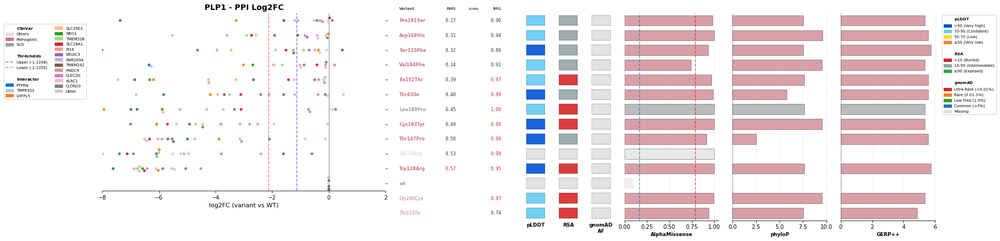

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/HGD_log2fc_panel_swarm.pdf


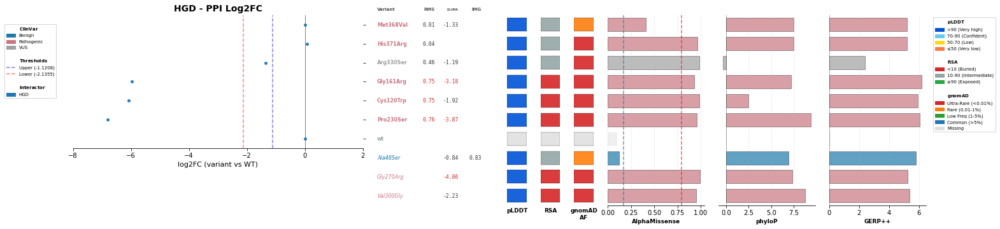

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/STXBP1_log2fc_panel_swarm.pdf


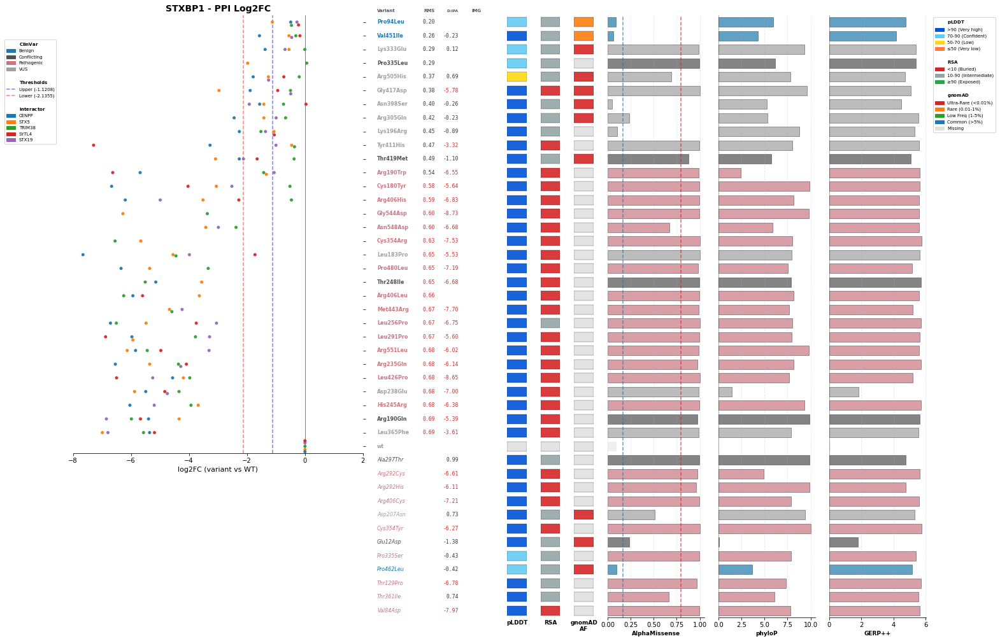

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 78.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.

Saved: ../3_outputs/sqY2H/log2fc_barplots/UBQLN2_log2fc_panel_swarm.pdf


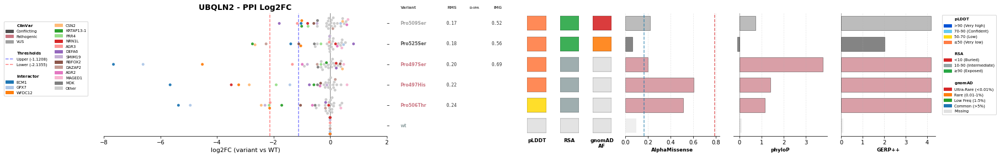

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT8_log2fc_panel_swarm.pdf


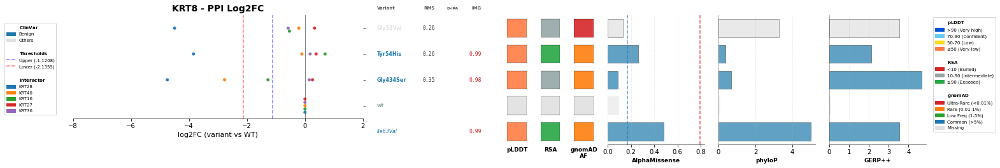

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/AGXT_log2fc_panel_swarm.pdf


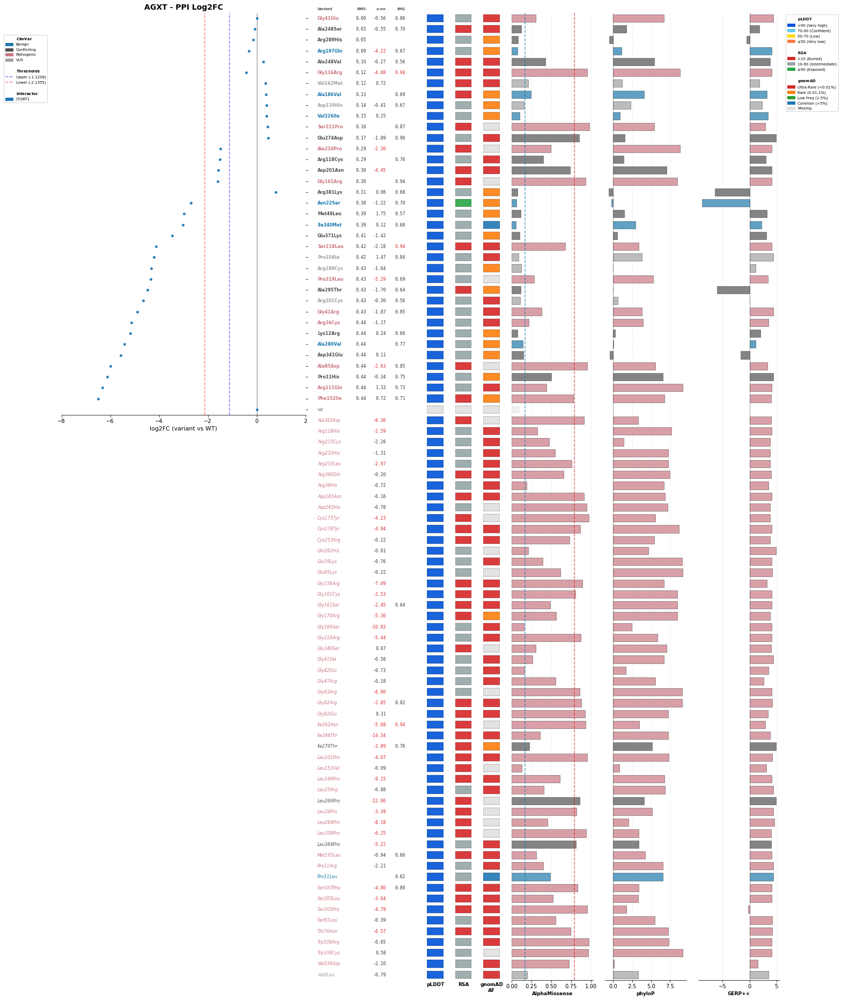

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/HPRT1_log2fc_panel_swarm.pdf


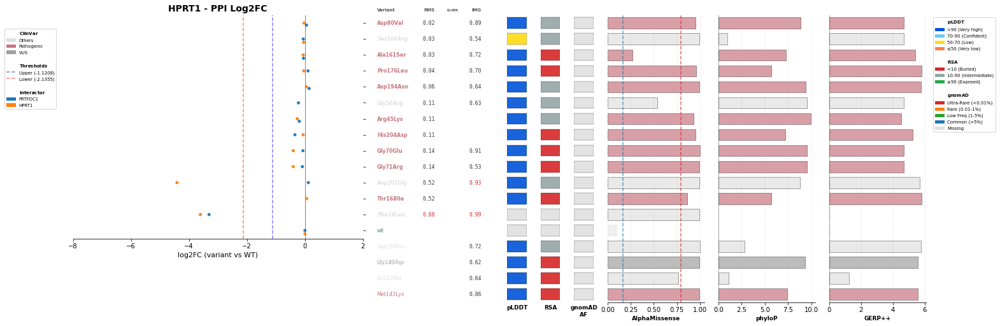

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/TPM1_log2fc_panel_swarm.pdf


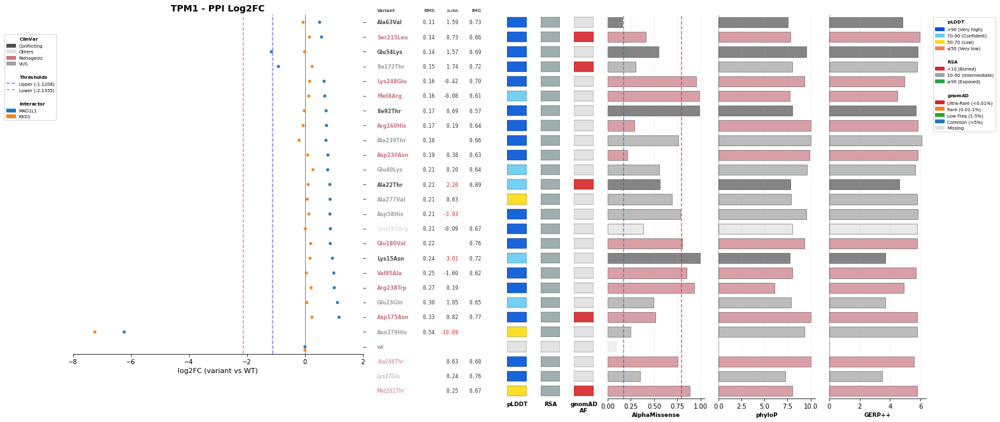

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 50.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.

Saved: ../3_outputs/sqY2H/log2fc_barplots/SUOX_log2fc_panel_swarm.pdf


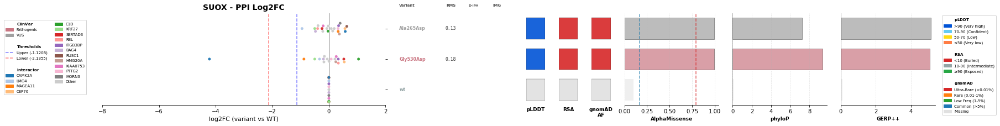

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/TTR_log2fc_panel_swarm.pdf


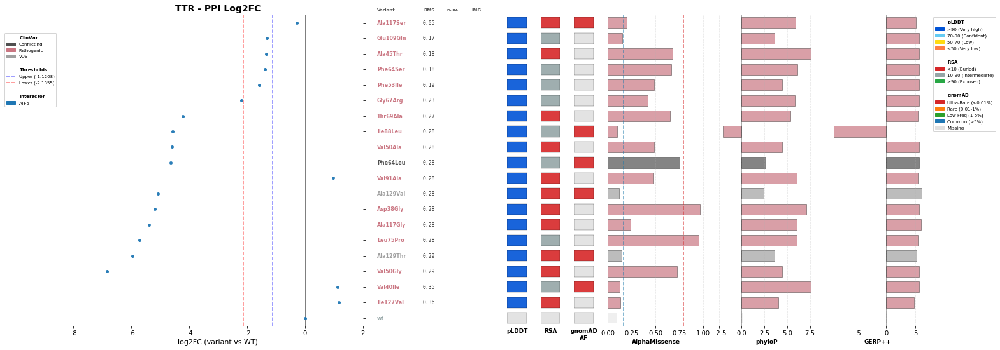

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/TMEM43_log2fc_panel_swarm.pdf


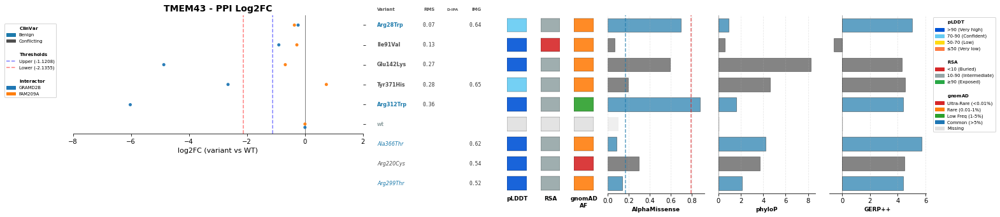

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 26.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.

Saved: ../3_outputs/sqY2H/log2fc_barplots/BAG3_log2fc_panel_swarm.pdf


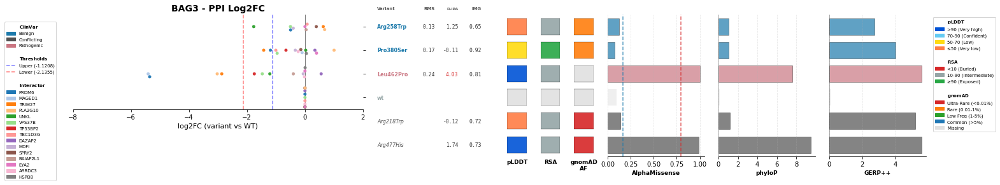

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/HMBS_log2fc_panel_swarm.pdf


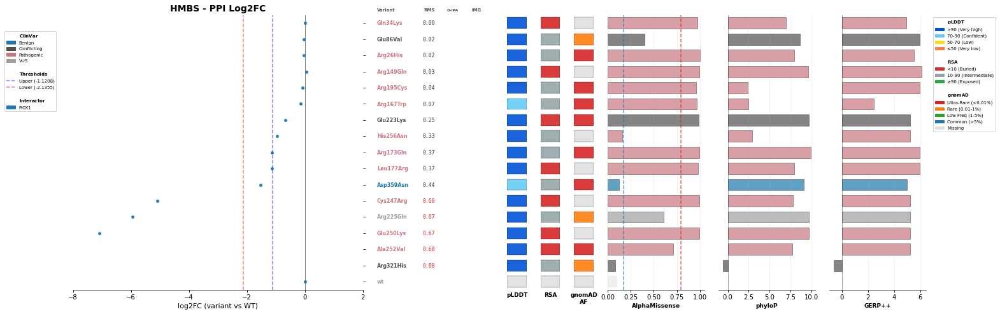

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KCNJ2_log2fc_panel_swarm.pdf


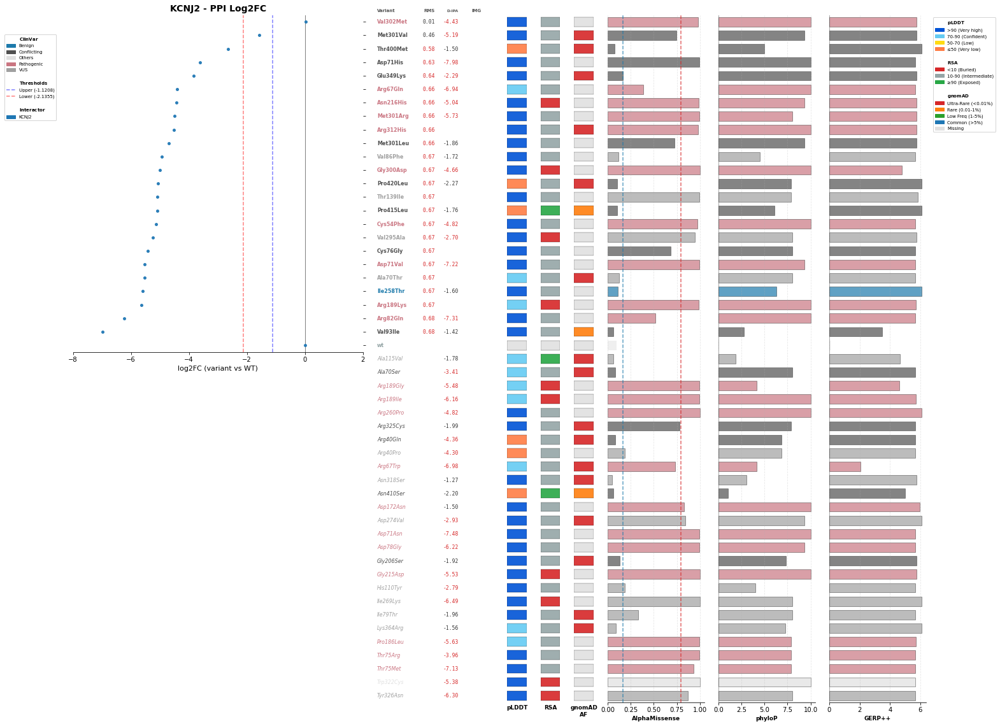

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PMP22_log2fc_panel_swarm.pdf


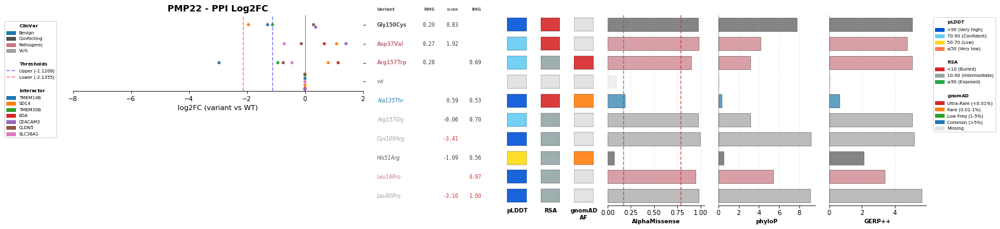

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/SFTPC_log2fc_panel_swarm.pdf


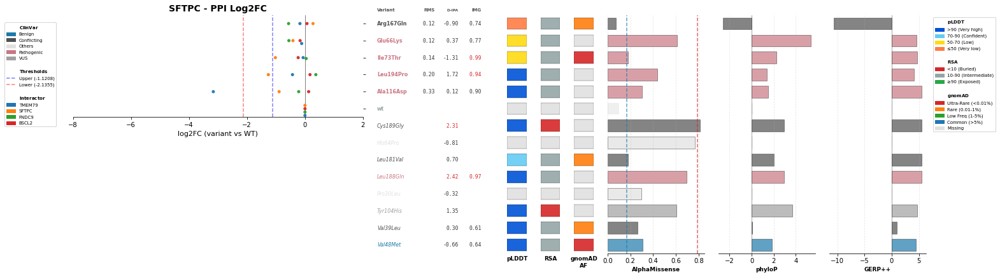

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/FA2H_log2fc_panel_swarm.pdf


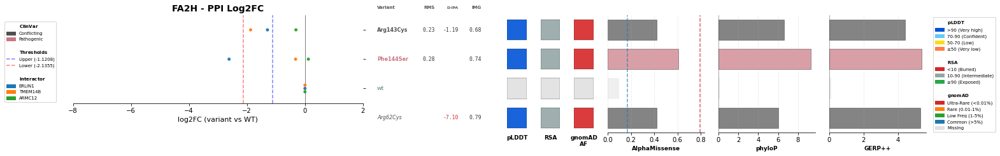

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/SH3BP2_log2fc_panel_swarm.pdf


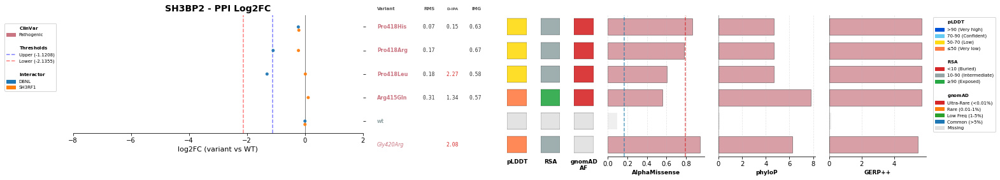

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/IL36RN_log2fc_panel_swarm.pdf


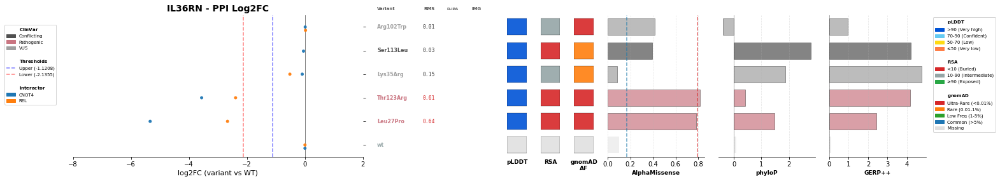

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/MVK_log2fc_panel_swarm.pdf


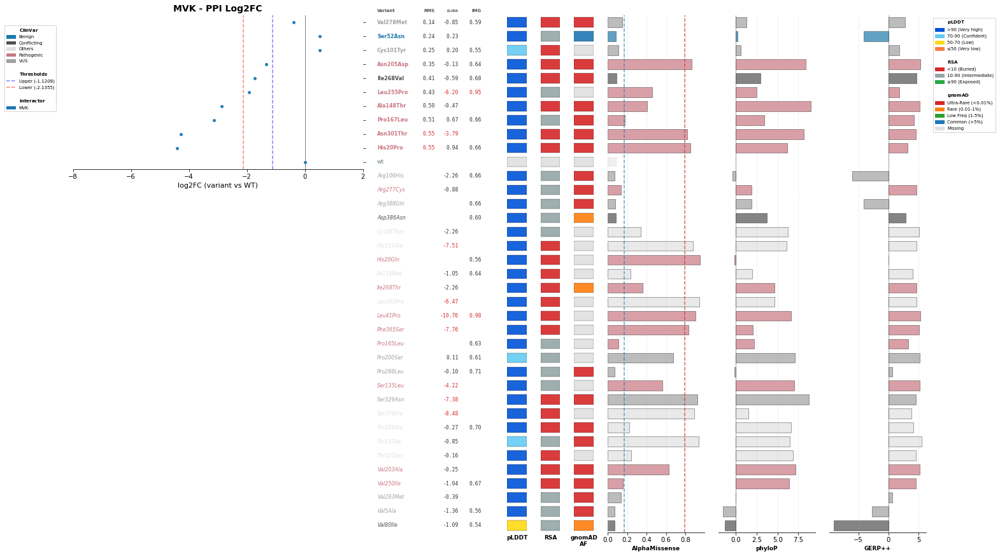

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/HBD_log2fc_panel_swarm.pdf


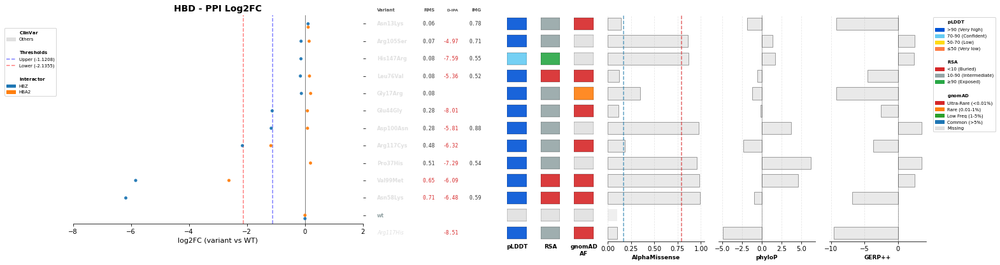

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/SMAD3_log2fc_panel_swarm.pdf


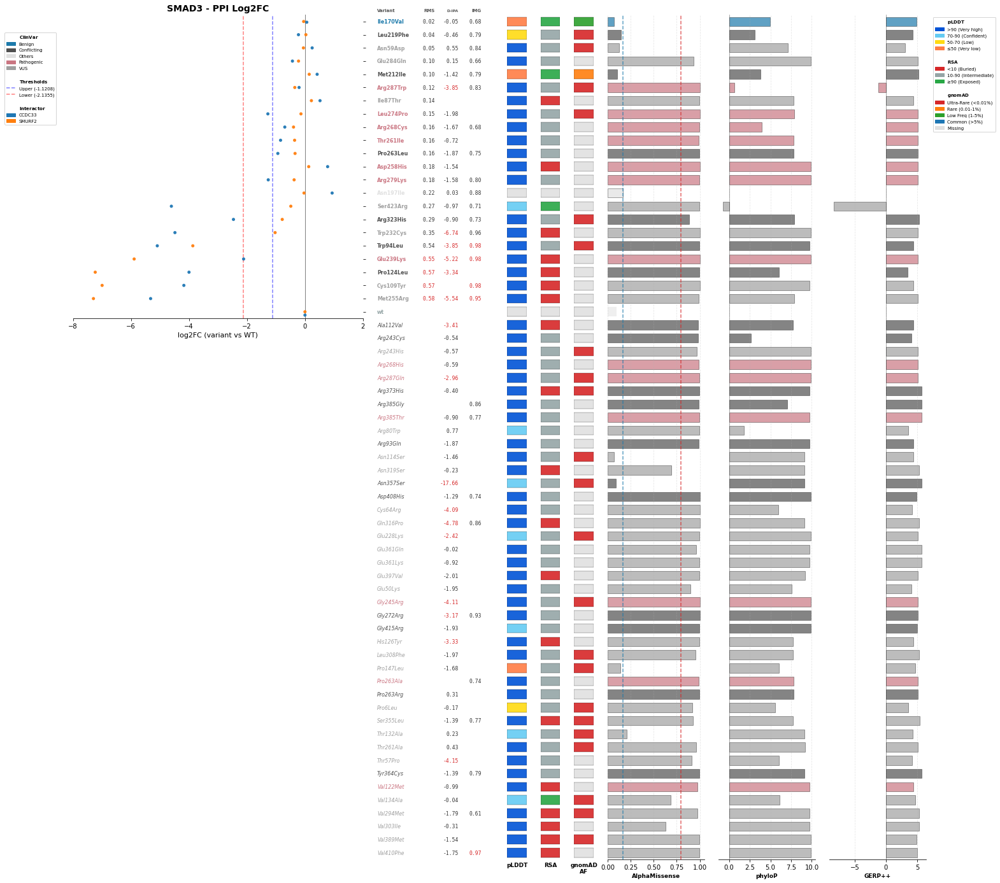

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/COQ8A_log2fc_panel_swarm.pdf


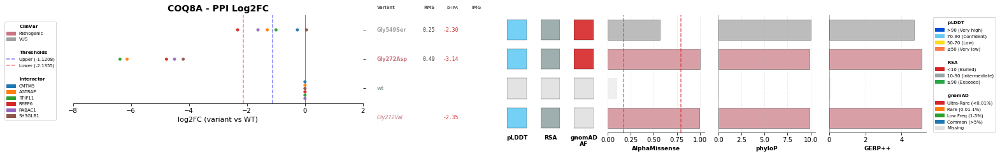

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KCTD7_log2fc_panel_swarm.pdf


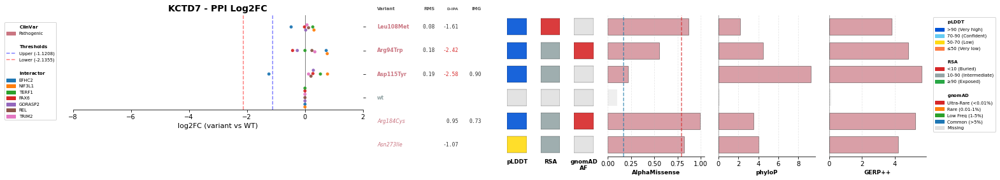

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/TH_log2fc_panel_swarm.pdf


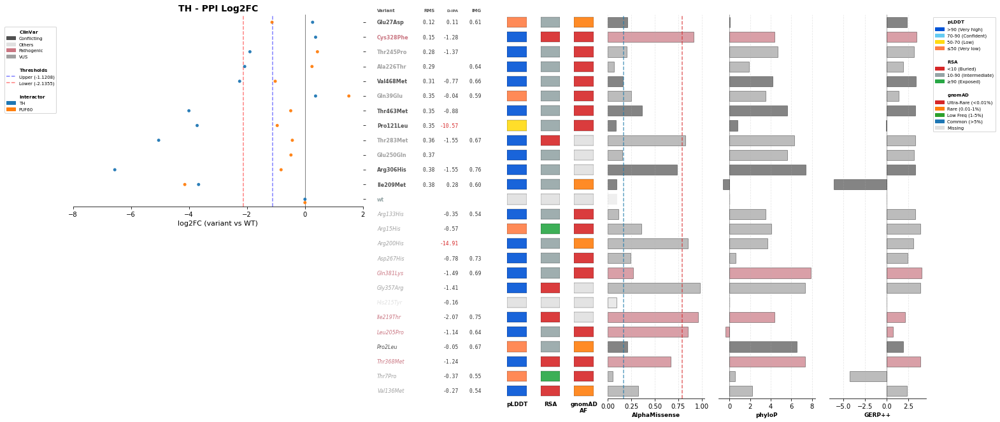

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/SMARCB1_log2fc_panel_swarm.pdf


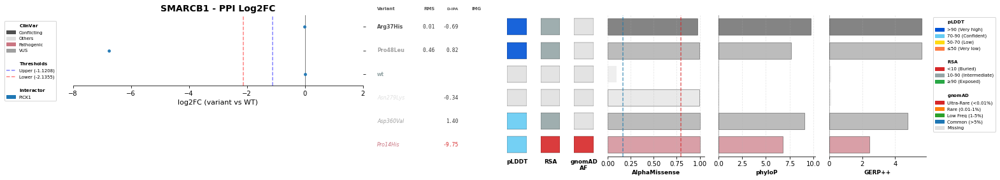

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/NAA10_log2fc_panel_swarm.pdf


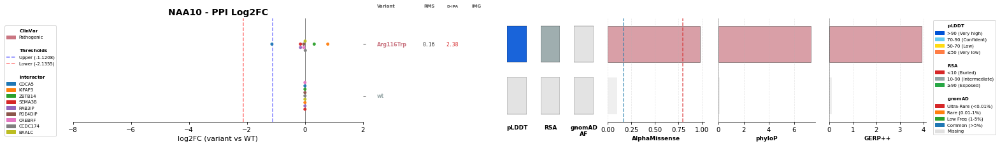

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/GSS_log2fc_panel_swarm.pdf


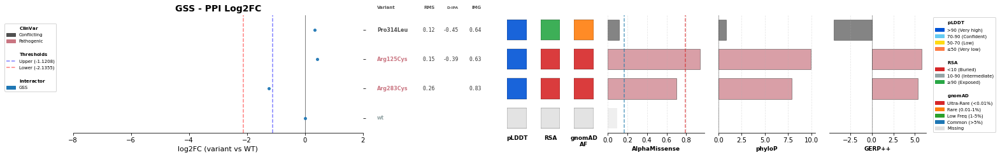

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/ALAS2_log2fc_panel_swarm.pdf


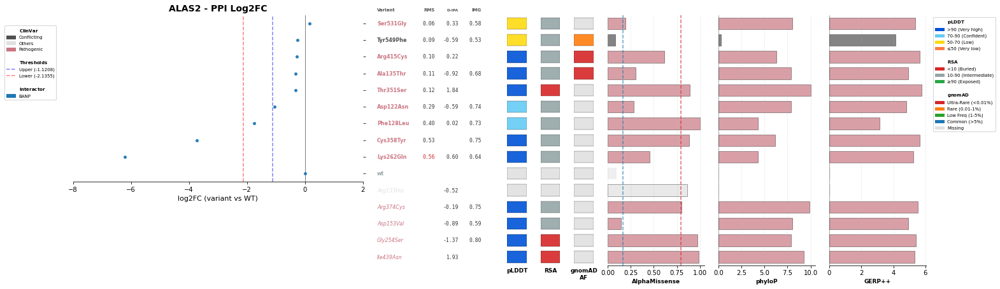

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/GRN_log2fc_panel_swarm.pdf


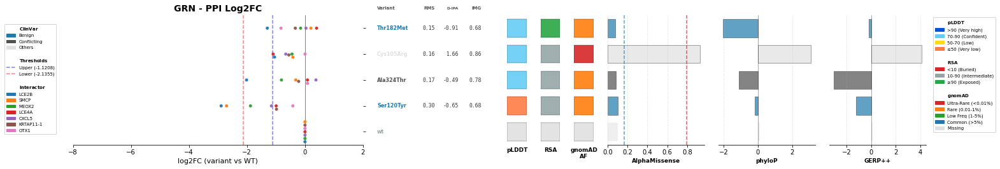

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PITX2_log2fc_panel_swarm.pdf


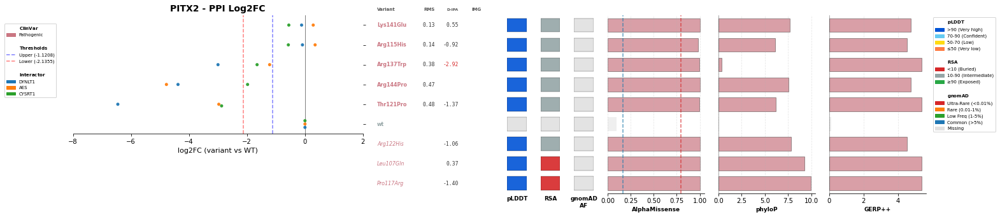

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/ACSF3_log2fc_panel_swarm.pdf


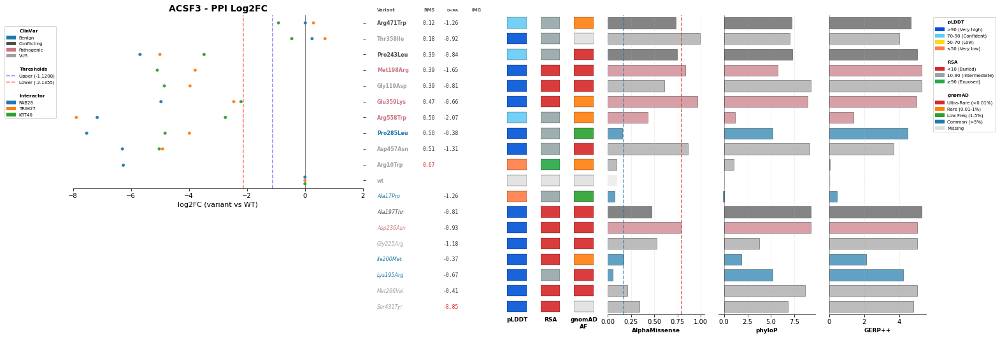

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/ASNS_log2fc_panel_swarm.pdf


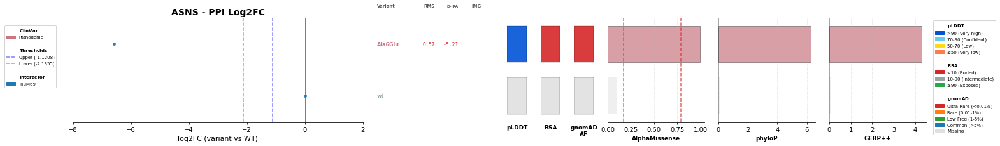

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT2_log2fc_panel_swarm.pdf


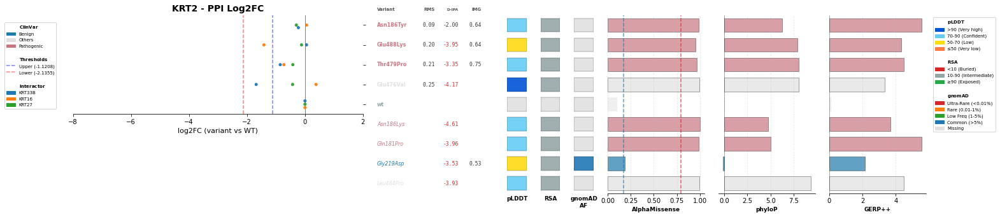

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PRPS1_log2fc_panel_swarm.pdf


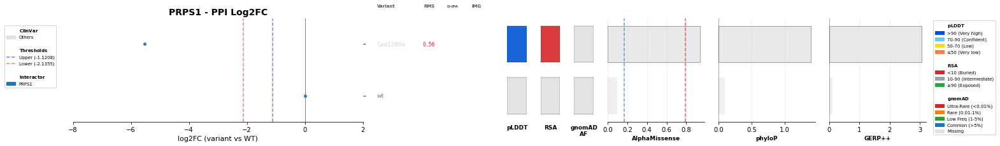

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PRKAR1A_log2fc_panel_swarm.pdf


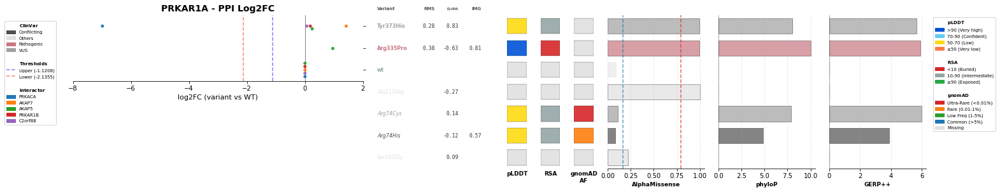

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT86_log2fc_panel_swarm.pdf


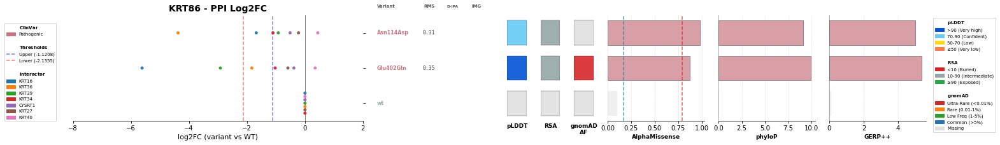

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/IER3IP1_log2fc_panel_swarm.pdf


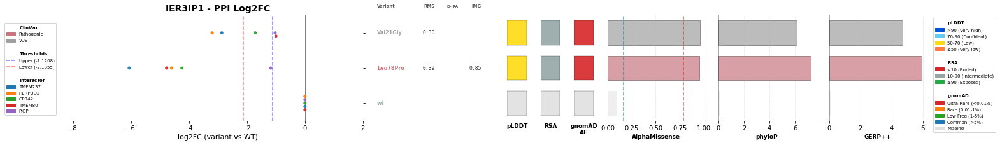

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/GCK_log2fc_panel_swarm.pdf


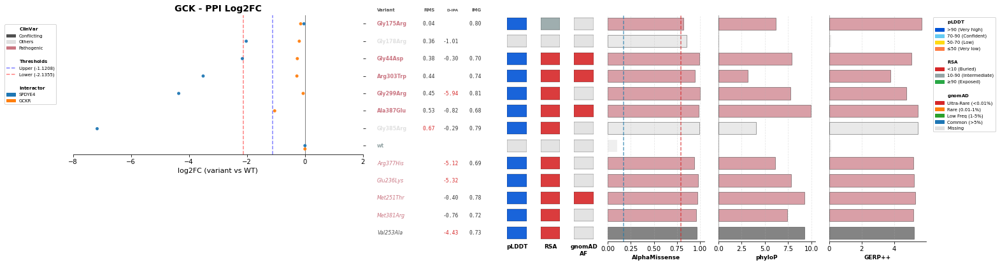

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/UROD_log2fc_panel_swarm.pdf


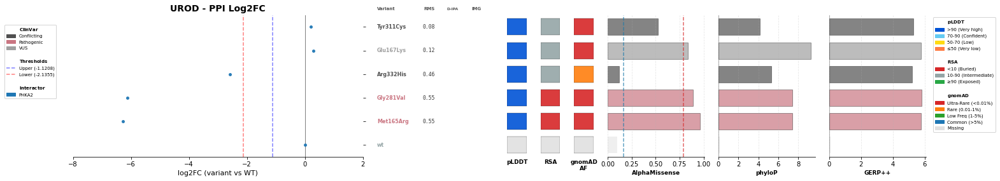

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/NEUROG3_log2fc_panel_swarm.pdf


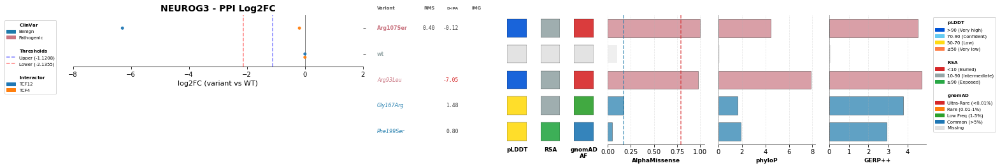

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/STAR_log2fc_panel_swarm.pdf


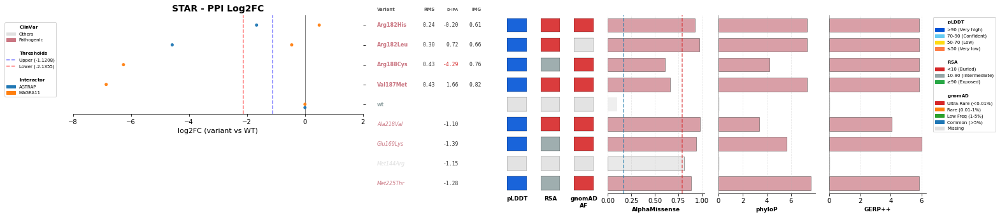

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/NMNAT1_log2fc_panel_swarm.pdf


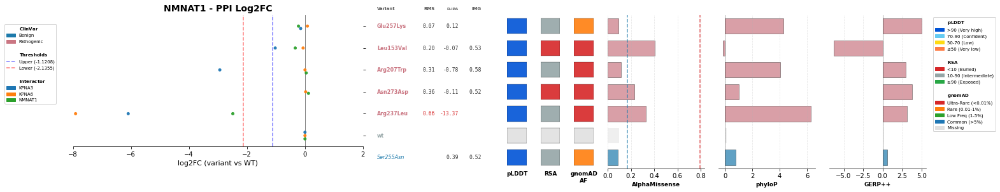

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/SIX1_log2fc_panel_swarm.pdf


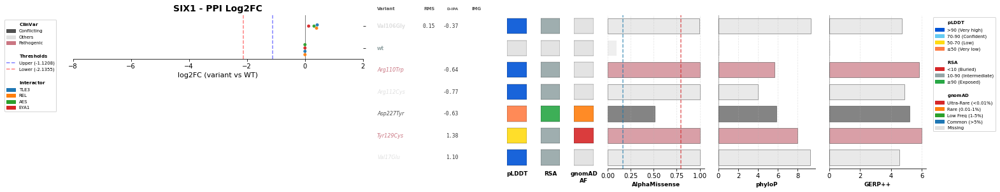

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/GMPPB_log2fc_panel_swarm.pdf


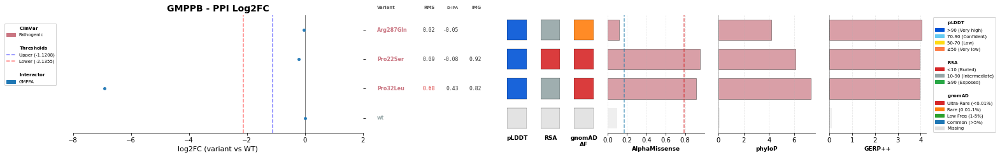

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PCCA_log2fc_panel_swarm.pdf


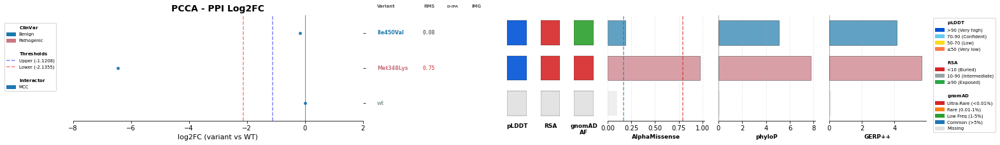

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/ZMYND10_log2fc_panel_swarm.pdf


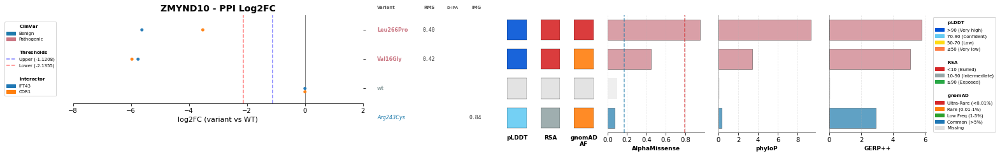

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/GALE_log2fc_panel_swarm.pdf


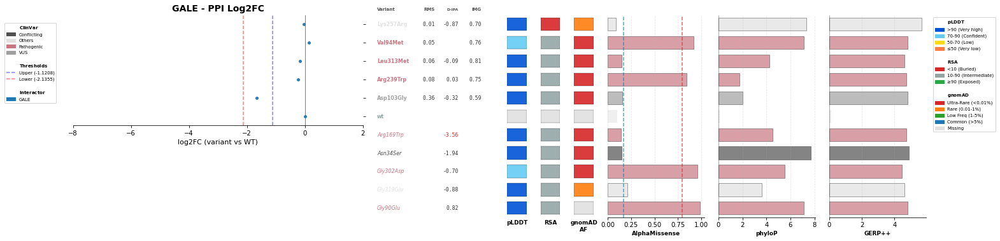

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/VHL_log2fc_panel_swarm.pdf


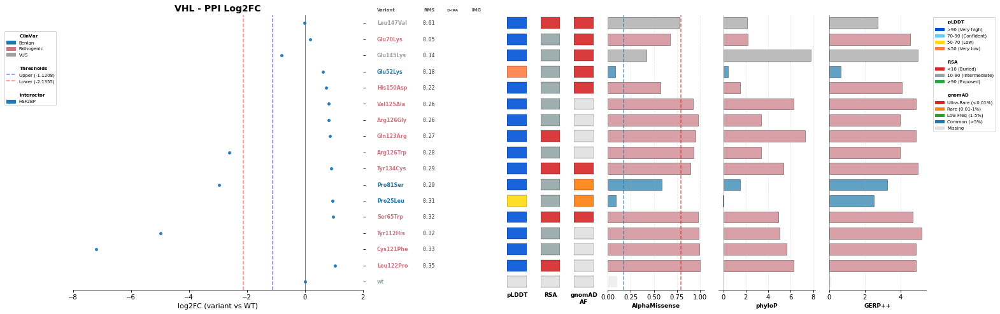

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/FBP1_log2fc_panel_swarm.pdf


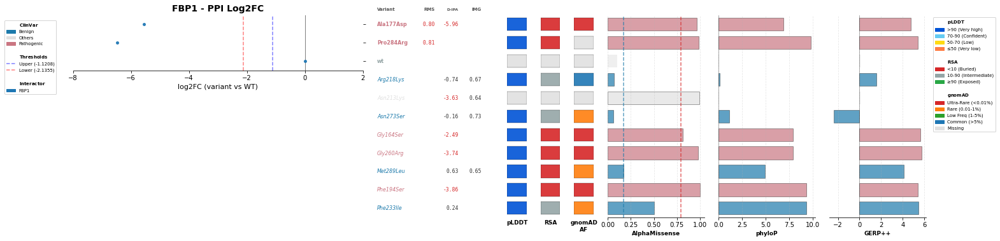

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PYGL_log2fc_panel_swarm.pdf


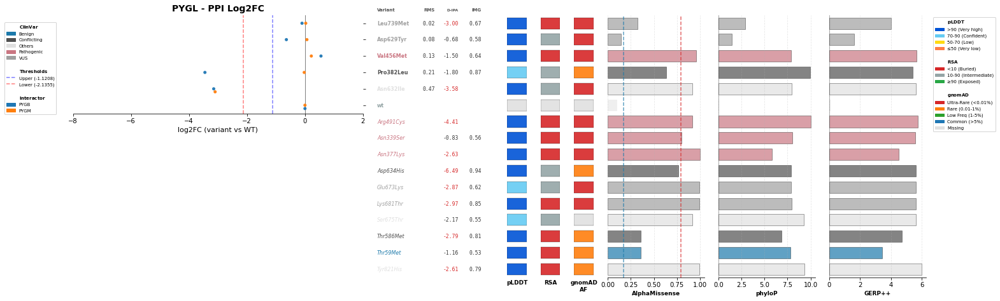

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/AIPL1_log2fc_panel_swarm.pdf


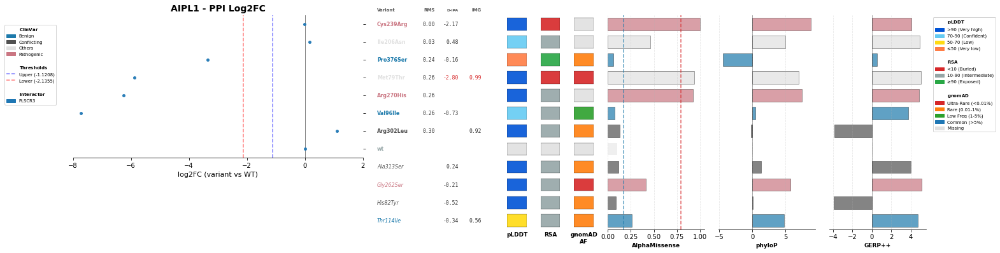

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/COL2A1_log2fc_panel_swarm.pdf


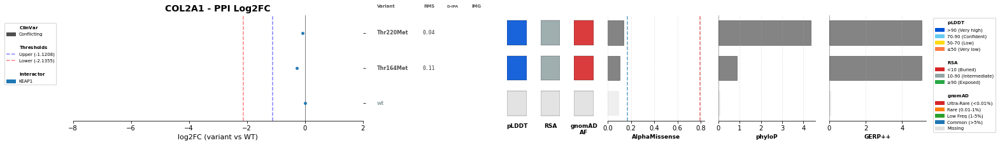

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PNKP_log2fc_panel_swarm.pdf


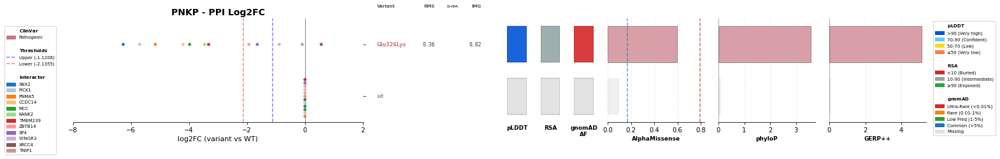

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KLHL3_log2fc_panel_swarm.pdf


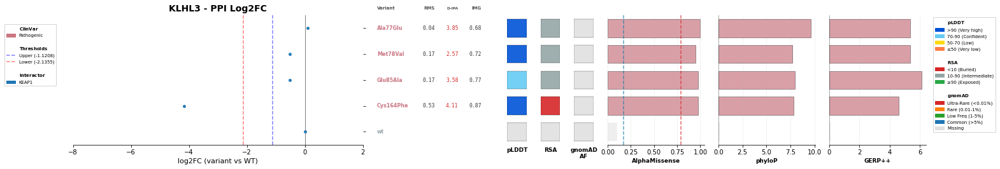

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KCTD1_log2fc_panel_swarm.pdf


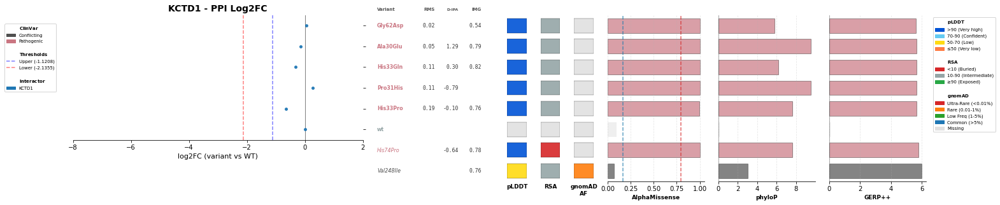

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/CRYAB_log2fc_panel_swarm.pdf


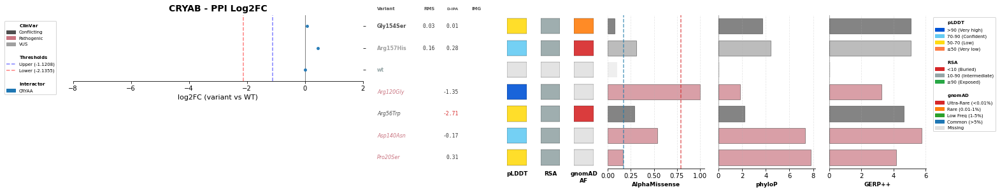

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/NR0B1_log2fc_panel_swarm.pdf


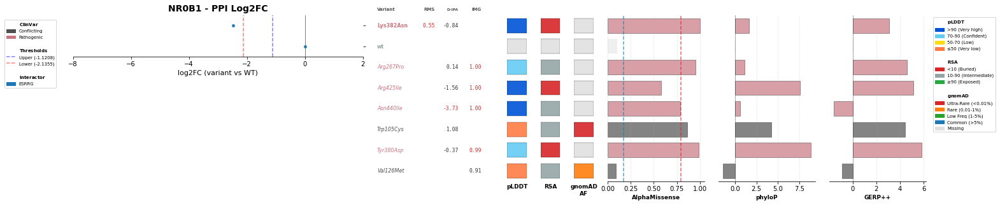

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/THAP1_log2fc_panel_swarm.pdf


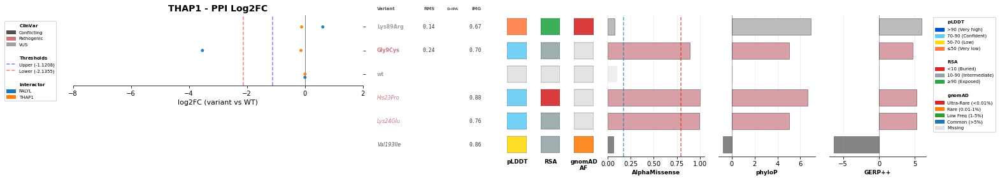

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/CLN6_log2fc_panel_swarm.pdf


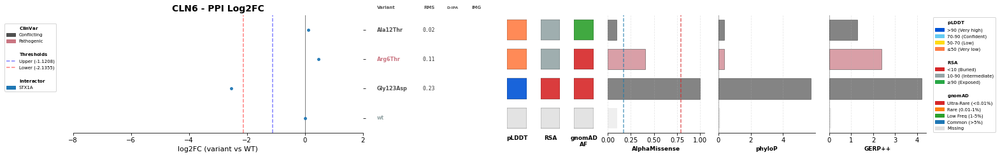

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/TPK1_log2fc_panel_swarm.pdf


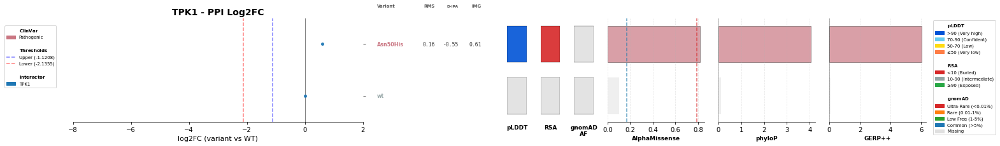

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT5_log2fc_panel_swarm.pdf


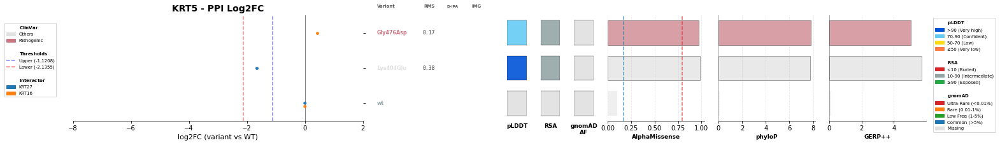

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/NCF2_log2fc_panel_swarm.pdf


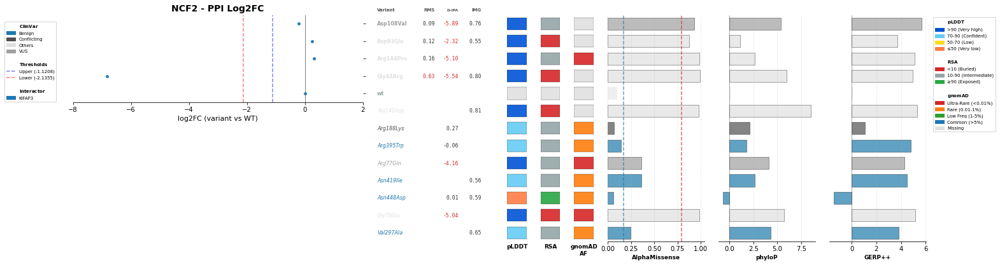

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PKP2_log2fc_panel_swarm.pdf


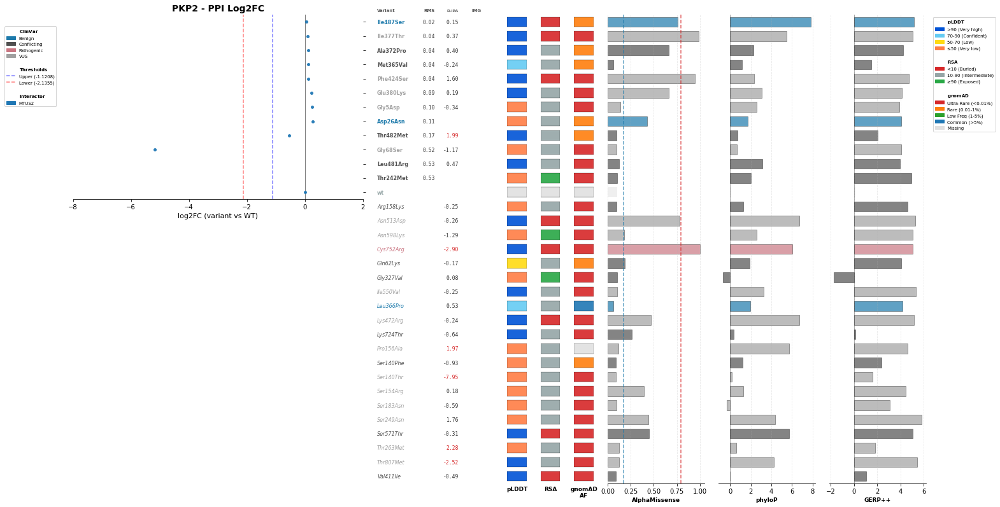

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/CHN1_log2fc_panel_swarm.pdf


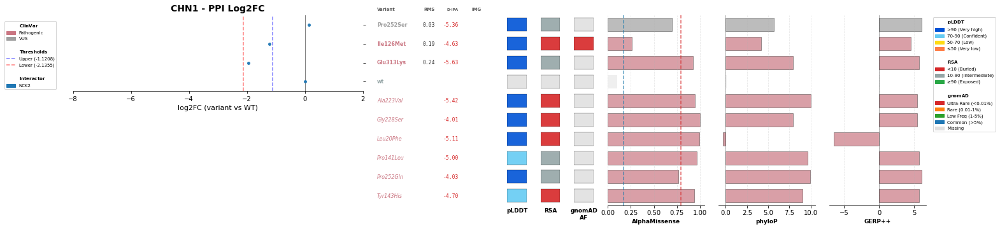

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/LDHB_log2fc_panel_swarm.pdf


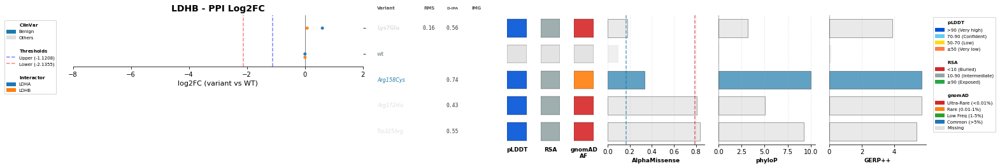

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/EZH2_log2fc_panel_swarm.pdf


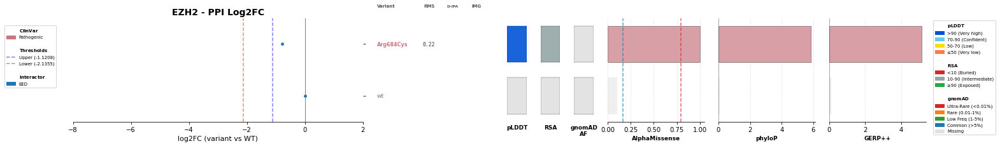

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/PTS_log2fc_panel_swarm.pdf


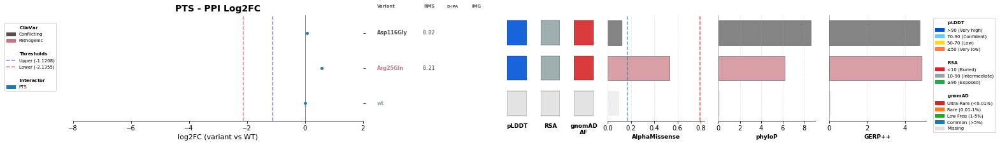

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/AP2S1_log2fc_panel_swarm.pdf


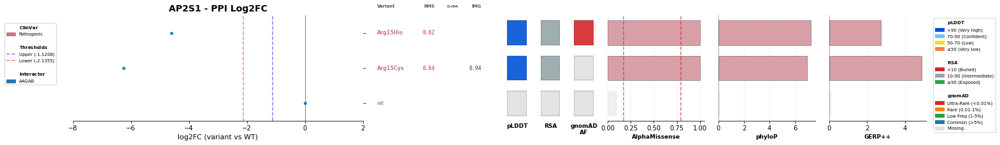

In [31]:
for symbol in edge_df['symbol'].unique():
    fig, axes = plot_log2fc_panel_swarm(
        edge_df=edge_df,
        db_symbol=symbol,
        orf_distances=orf_distances,
        all_assay_df=all_assay_df,
        palette_dict=palette_dict,
        save_path=f'{outputs_dir}/log2fc_barplots/{symbol}_log2fc_panel_swarm.pdf',
        top_n_interactors=15
    )

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS', 'Eigen-PC-phred_coding']


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 20.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 80.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed

Saved: ../3_outputs/sqY2H/log2fc_barplots/LITAF_log2fc_panel_swarm_Eigen-PC-phred_coding.pdf


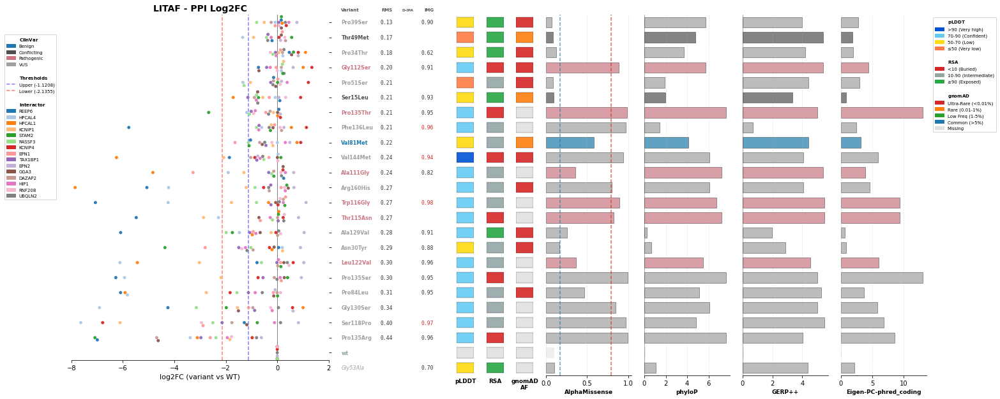

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS', 'Eigen-PC-phred_coding']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/STXBP1_log2fc_panel_swarm_Eigen-PC-phred_coding.pdf


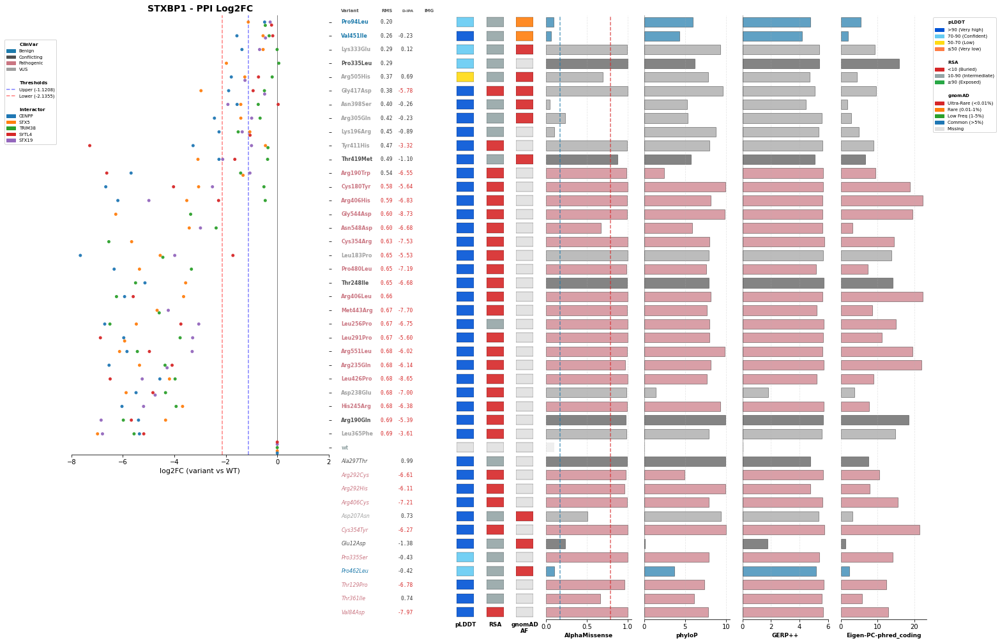

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS', 'Eigen-PC-phred_coding']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/AGXT_log2fc_panel_swarm_Eigen-PC-phred_coding.pdf


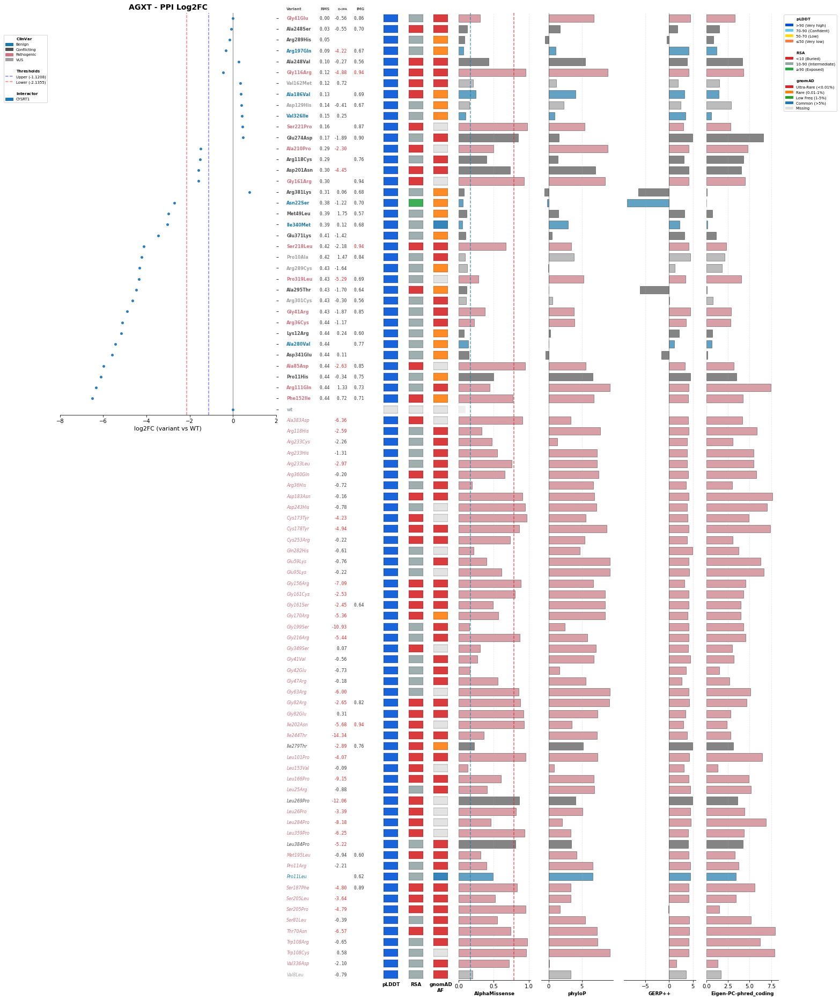

Using annotation columns: ['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF', 'am_pathogenicity', 'phyloP100way_vertebrate', 'GERP++_RS', 'Eigen-PC-phred_coding']


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:323: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_plddt_cat.update(gene_data.groupby('aa_change')['pLDDT_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variant_rsa_cat.update(gene_data.groupby('aa_change')['RSA_Category'].first().to_dict())
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_28055/1445353803.py:327: FutureWarning: The default of observed=False is deprecated and will be changed to True in 

Saved: ../3_outputs/sqY2H/log2fc_barplots/MVK_log2fc_panel_swarm_Eigen-PC-phred_coding.pdf


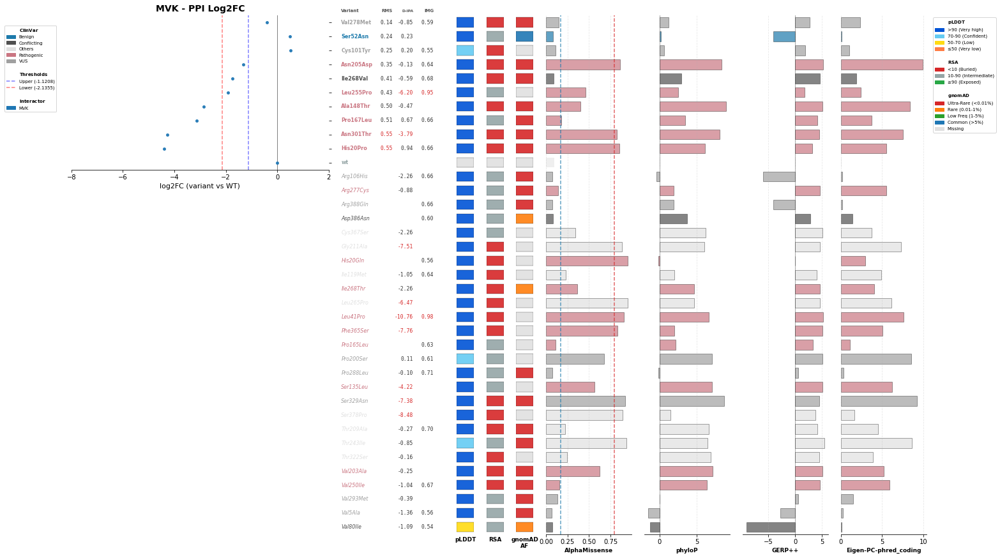

In [32]:
for symbol in ['LITAF', 'STXBP1', 'AGXT', 'MVK']:
    fig, axes = plot_log2fc_panel_swarm(
        edge_df=edge_df,
        db_symbol=symbol,
        orf_distances=orf_distances,
        all_assay_df=all_assay_df,
        palette_dict=palette_dict,
        annotation_cols=['plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF',
                         'am_pathogenicity', 'phyloP100way_vertebrate', 
                         'GERP++_RS', 'Eigen-PC-phred_coding'],
        save_path=f'{outputs_dir}/log2fc_barplots/{symbol}_log2fc_panel_swarm_Eigen-PC-phred_coding.pdf'
    )

In [33]:
edge_df[edge_df.symbol == 'UBQLN2'].ad_symbol.unique()

array(['RTL8C', 'ZG16B', 'MAGED1', 'KRTAP19-5', 'TRIM32', 'RNF4',
       'EFEMP1', 'MDK', 'BCL2L11', 'AGR3', 'RBFOX2', 'CSN2', 'ECM1',
       'LATS1', 'RNF208', 'SFTPA2', 'DEFA6', 'STAM2', 'GPX7', 'CCDC158',
       'KRTAP13-1', 'PRR4', 'NRN1L', 'JPH4', 'WFDC12', 'DAZAP2', 'SMIM19',
       'NPY', 'LASP1', 'UBQLN2', 'HGS', 'GALP', 'AGR2'], dtype=object)